# Import Library

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import math
import cmath
import csv
import time

In [3]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, Model, Input
from tensorflow.keras.layers import Dense, Conv1D, Flatten, GRU, Input, MaxPooling1D, concatenate, BatchNormalization, Reshape
from tensorflow.keras.losses import MeanSquaredError, MeanAbsolutePercentageError
from tensorflow.keras.optimizers import Adam, RMSprop, SGD
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from tensorflow.keras.utils import plot_model

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_percentage_error, r2_score

In [5]:
from scipy.interpolate import interp1d

# Fungsi Penting

In [6]:
def formating_result(resis, ketebalan, total_depth):
  depth = np.concatenate(([0], np.cumsum(ketebalan), [total_depth]))
  depth_plot = np.repeat(depth, 2)[1:-1]
  resis_plot = np.repeat(resis, 2)

  return depth_plot, resis_plot

In [7]:

def measure_MSE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict):
  # MSE untuk resistivitas_semu
  mse_resistivitas = np.mean(np.square(resistivitas_semu - resistivitas_semu_predict))

  # MSE untuk fasa
  mse_fasa = np.mean(np.square(fasa - fasa_predict))

  # Cetak hasil
  print(f"MSE Resistivitas Semu: {mse_resistivitas:.2f}")
  print(f"MSE Fasa: {mse_fasa:.2f}")

In [8]:

def measure_MAPE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict):
  # Hitung MAPE
  mape_appres = np.mean(np.abs((resistivitas_semu - resistivitas_semu_predict) / resistivitas_semu)) * 100

  # Cetak hasil
  print(f"MAPE resistivitas semu: {mape_appres:.2f}%")
  # Hitung MAPE
  mape_phase = np.mean(np.abs((fasa - fasa_predict) / fasa)) * 100

  # Cetak hasil
  print(f"MAPE fasa: {mape_phase:.2f}%")

  return mape_appres, mape_phase

In [9]:
import numpy as np

def measure_RMSE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict):
  # RMSE untuk resistivitas_semu
  rmse_resistivitas = np.sqrt(np.mean(np.square(resistivitas_semu - resistivitas_semu_predict)))

  # RMSE untuk fasa
  rmse_fasa = np.sqrt(np.mean(np.square(fasa - fasa_predict)))

  # Cetak hasil
  print(f"RMSE Resistivitas Semu: {rmse_resistivitas:.2f}")
  print(f"RMSE Fasa: {rmse_fasa:.2f}")

In [10]:
from scipy.interpolate import interp1d
from sklearn.metrics import mean_squared_error, mean_absolute_percentage_error

def measure_interpolated_resistivities(resis_true, ketebalan_true, resis_predict, ketebalan_predict, total_depth):
  # Formating data
  depth_true_plot, resis_true_plot = formating_result(resis_true, ketebalan_true, total_depth)
  depth_pred_plot, resis_pred_plot = formating_result(resis_predict, ketebalan_predict, total_depth)

  # Definisikan grid kedalaman umum
  common_depths = np.linspace(0, 4000, 200)

  # Interpolasi ke grid umum
  interp_true = interp1d(depth_true_plot, resis_true_plot, kind='previous', fill_value='extrapolate')
  interp_pred = interp1d(depth_pred_plot, resis_pred_plot, kind='previous', fill_value='extrapolate')

  res_true_interp = interp_true(common_depths)
  res_pred_interp = interp_pred(common_depths)

  # Sekarang bisa dibandingkan secara numerik juga
  mse_interp = mean_squared_error(res_true_interp, res_pred_interp)
  rmse_interp = np.sqrt(mse_interp) # Calculate RMSE
  mape_interp = mean_absolute_percentage_error(res_true_interp, res_pred_interp)

  print(f"[Interpolated] MSE model resistivitas: {mse_interp:.4f}")
  print(f"[Interpolated] RMSE model resistivitas: {rmse_interp:.4f}") # Print RMSE
  print(f"[Interpolated] MAPE model resistivitas: {mape_interp*100:.2f}%")

  plt.figure(figsize=(8, 6))

  # Plot garis hasil interpolasi
  plt.scatter(res_true_interp, common_depths, label='True (Interpolated)', color='blue', linewidth=2)
  plt.scatter(resis_pred_plot, depth_pred_plot, label='Resistivitas Prediksi', color='red', linestyle='--', linewidth=2)
  plt.scatter(res_pred_interp, common_depths, label='Predicted (Interpolated)', color='red', linestyle='--', linewidth=2)


  # Sumbu y dibalik agar makin dalam ke bawah
  plt.gca().invert_yaxis()

  # Label dan judul
  plt.xlabel('Resistivitas (Ohm.m)', fontsize=12)
  plt.ylabel('Kedalaman (m)', fontsize=12)
  plt.title('Perbandingan Interpolasi Resistivitas Sebenarnya vs Prediksi', fontsize=14)
  plt.legend()
  plt.grid(True, linestyle='--', alpha=0.6)
  plt.xlim(0, 2000)
  plt.ylim(4000,0)

  plt.show()

In [11]:
def plot_model(resis_predict, ketebalan_predict ,total_depth):

  depth_pred_plot, resis_pred_plot = formating_result(resis_predict , ketebalan_predict, total_depth)
  # Buat plot
  plt.figure(figsize=(8, 6))

  # Plot Resistivitas Prediksi (Pred)
  plt.plot(resis_pred_plot, depth_pred_plot, label='Resistivitas Prediksi', color='red', linestyle='--', linewidth=2)

  # Pengaturan sumbu dan grafik
  plt.xlabel('Resistivitas (Ohm.m)', fontsize=12)
  plt.ylabel('Kedalaman (m)', fontsize=12)
  plt.title('Hasil Inversi Magnetotelurik 1D', fontsize=14)
  plt.legend(loc='upper right')
  plt.grid(True, linestyle='--', alpha=0.6)

  # Sesuaikan rentang sumbu
  plt.xlim(0, 1200)  # Rentang resistivitas dari 0 hingga 1200 Ohm.m
  plt.ylim(4000, 0)  # Rentang kedalaman dari 0 hingga 1000 m (dibalik agar makin dalam ke bawah)

  plt.show()

In [12]:

def plot_model_compare(res_true, ketebalan_true, res_predict, ketebalan_predict, total_depth):
  depth_true_plot, resis_true_plot = formating_result(resis_true, ketebalan_true, total_depth)
  depth_pred_plot, resis_pred_plot = formating_result(resis_predict , ketebalan_predict, total_depth)

  # Buat plot
  plt.figure(figsize=(8, 6))

  # Plot Resistivitas Sebenarnya (True)
  plt.plot(resis_true_plot, depth_true_plot, label='Resistivitas Sebenarnya', color='blue', linewidth=2)

  # Plot Resistivitas Prediksi (Pred)
  plt.plot(resis_pred_plot, depth_pred_plot, label='Resistivitas Prediksi', color='red', linestyle='--', linewidth=2)

  # Pengaturan sumbu dan grafik
  plt.xlabel('Resistivitas (Ohm.m)', fontsize=12)
  plt.ylabel('Kedalaman (m)', fontsize=12)
  plt.title('Hasil Inversi Magnetotelurik 1D', fontsize=14)
  plt.legend(loc='upper right')
  plt.grid(True, linestyle='--', alpha=0.6)

  # Sesuaikan rentang sumbu
  plt.xlim(0, 1200)  # Rentang resistivitas dari 0 hingga 1200 Ohm.m
  plt.ylim(4000, 0)  # Rentang kedalaman dari 0 hingga 1000 m (dibalik agar makin dalam ke bawah)

  plt.show()

In [13]:
def plot_MT(resis_predict, ketebalan_predict, period, fasa, resistivitas_semu, fasa_predict,resistivitas_semu_predict, total_depth):

  depth_pred_plot, resis_pred_plot = formating_result(resis_predict , ketebalan_predict, total_depth)

  #Buat figure dan GridSpec
  fig = plt.figure(figsize=(15, 8))
  gs = gridspec.GridSpec(2, 2, width_ratios=[2, 1])  # 2 baris, 2 kolom, kolom kanan lebih kecil

  # Subplot 1: Resistivitas Semu
  ax1 = fig.add_subplot(gs[0, 0])
  ax1.scatter(period, resistivitas_semu[0], 'o', color='blue', label='data sebenarnya', markersize=4)
  ax1.plot(period, resistivitas_semu_predict[0], '--', color='red', label='data prediksi', markersize=4)
  ax1.set_ylabel('App. Resistivity [$\Omega$m]', fontsize=12)
  ax1.set_xlabel('Periods (Sec.)', fontsize=12)
  ax1.set_xscale('log')
  ax1.set_ylim([0, 1000])
  ax1.set_xlim([10**-4, 10**4])
  ax1.grid(True, linestyle='--', alpha=0.6)
  ax1.set_title('Kurva Resistivitas Semu', fontsize=14)
  ax1.legend()

  # Subplot 2: Phase
  ax2 = fig.add_subplot(gs[1, 0])
  ax2.scatter(period, fasa[0], 'o', color='blue', label='data sebenarnya', markersize=4)
  ax2.plot(period, fasa_predict[0], '--', color='red', label='data prediksi', markersize=4)
  ax2.set_ylabel('Phase [derajat]', fontsize=12)
  ax2.set_xlabel('Periods (Sec.)', fontsize=12)
  ax2.set_xscale('log')
  ax2.set_ylim([0, 90])
  ax2.set_xlim([10**-4, 10**4])
  ax2.grid(True, linestyle='--', alpha=0.6)
  ax2.set_title('Kurva Fasa', fontsize=14)
  ax2.legend()

  # Subplot 3: Resistivitas Prediksi (span 2 baris)
  ax3 = fig.add_subplot(gs[:, 1])  # Ini artinya: kolom ke-2, tapi mencakup dua baris
  ax3.plot(resis_pred_plot, depth_pred_plot, label='Resistivitas Prediksi', color='red', linestyle='--', linewidth=2)
  ax3.set_xlabel('Resistivitas (Ohm.m)', fontsize=12)
  ax3.set_ylabel('Kedalaman (m)', fontsize=12)
  ax3.set_title('Model Inversi Magnetotelurik 1D', fontsize=14)
  ax3.legend(loc='upper right')
  ax3.grid(True, linestyle='--', alpha=0.6)
  ax3.set_xlim(0, 1200)
  ax3.set_ylim(4000, 0)  # Dari permukaan ke bawah

  plt.tight_layout()
  plt.show()


<>:13: SyntaxWarning: invalid escape sequence '\O'
<>:13: SyntaxWarning: invalid escape sequence '\O'
/tmp/ipython-input-1248842096.py:13: SyntaxWarning: invalid escape sequence '\O'
  ax1.set_ylabel('App. Resistivity [$\Omega$m]', fontsize=12)


In [14]:
def plot_MT_compare(res_true, thick_true, res_pred, thick_pred,
                    periods, phase_true, res_app_true, phase_pred, res_app_pred,
                    total_depth):

    # Convert model to depth-resistivity format
    depth_true_plot, res_true_plot = formating_result(res_true, thick_true, total_depth)
    depth_pred_plot, res_pred_plot = formating_result(res_pred, thick_pred, total_depth)

    # Create figure and GridSpec layout
    fig = plt.figure(figsize=(15, 8))
    gs = gridspec.GridSpec(2, 2, width_ratios=[2, 1])

    # === Subplot 1: Apparent Resistivity ===
    ax1 = fig.add_subplot(gs[0, 0])
    ax1.scatter(periods, res_app_true[0], color='blue', label='True Data', s=20, marker='o')
    ax1.plot(periods, res_app_pred[0], '--', color='red', label='Predicted Data', linewidth=2)
    ax1.set_xscale('log')
    ax1.set_xlim(1e-4, 1e4)
    ax1.set_ylim(0, 1200)
    ax1.set_xlabel('Perioda (s)', fontsize=12)
    ax1.set_ylabel('Resistivitas Semu [$\Omega$m]', fontsize=12)
    ax1.set_title('Kurva Resistivitas Semu ($\\rho$)', fontsize=14)
    ax1.grid(True, linestyle='--', alpha=0.6)
    ax1.legend()

    # === Subplot 2: Phase ===
    ax2 = fig.add_subplot(gs[1, 0])
    ax2.scatter(periods, phase_true[0], color='blue', label='Data Sebenarnya', s=20, marker='o')
    ax2.plot(periods, phase_pred[0], '--', color='red', label='Data Prediksi', linewidth=2)
    ax2.set_xscale('log')
    ax2.set_xlim(1e-4, 1e4)
    ax2.set_ylim(0, 90)
    ax2.set_xlabel('Periodq (s)', fontsize=12)
    ax2.set_ylabel('Fasa [°]', fontsize=12)
    ax2.set_title('Kurva Fasa (°)', fontsize=14)
    ax2.grid(True, linestyle='--', alpha=0.6)
    ax2.legend()

    # === Subplot 3: 1D Inversion Result ===
    ax3 = fig.add_subplot(gs[:, 1])
    ax3.plot(res_pred_plot, depth_pred_plot, label='Resistivitas Prediksi', color='red', linestyle='--', linewidth=2)
    ax3.plot(res_true_plot, depth_true_plot, label='Resistivitas Sebenarnya', color='blue', linestyle='--', linewidth=2)
    ax3.set_xlim(0, 1200)
    ax3.set_ylim(total_depth, 0)  # Depth from surface to bottom
    ax3.set_xlabel('Resistivitas [$\Omega$·m]', fontsize=12)
    ax3.set_ylabel('Kedalaman (m)', fontsize=12)
    ax3.set_title('Model Inversi Magnetotelurik 1D', fontsize=14)
    ax3.grid(True, linestyle='--', alpha=0.6)
    ax3.legend(loc='upper right')

    plt.tight_layout()
    plt.show()


<>:21: SyntaxWarning: invalid escape sequence '\O'
<>:45: SyntaxWarning: invalid escape sequence '\O'
<>:21: SyntaxWarning: invalid escape sequence '\O'
<>:45: SyntaxWarning: invalid escape sequence '\O'
/tmp/ipython-input-3284210955.py:21: SyntaxWarning: invalid escape sequence '\O'
  ax1.set_ylabel('Resistivitas Semu [$\Omega$m]', fontsize=12)
/tmp/ipython-input-3284210955.py:45: SyntaxWarning: invalid escape sequence '\O'
  ax3.set_xlabel('Resistivitas [$\Omega$·m]', fontsize=12)


#Forward Modelling

In [15]:
#Fungsi forward modelling
def forward_modelling(res_true, ketebalan, frequencies):
    resistivitas_semu = np.array([])
    fasa = np.array([])
    for frequency in frequencies:
        w = 2 * np.pi * frequency
        mu = 4 * np.pi * 10**(-7)
        n = len(res_true)
        Z = list(range(n))  # Initialize Z as a list
        Z[n-1] = cmath.sqrt(w * mu * res_true[n-1] * 1j)  # Calculate basement impedance
        for j in range(n-2, -1, -1):
            Z0j = cmath.sqrt(1j * w * mu * res_true[j])  # Intrinsic impedance of current layer
            kj = cmath.sqrt(1j * w * mu / res_true[j])  # Wave number
            ej = cmath.exp(-2 * ketebalan[j] * kj)  # Exponential factor
            Rj = (Z0j - Z[j+1]) / (Z0j + Z[j+1])  # Reflection coefficient
            Z[j] = Z0j * (1 - Rj * ej) / (1 + Rj * ej)  # Impedance of current layer
        Z_intrinsik = Z[0]  # Top layer impedance
        absZ = abs(Z_intrinsik)
        appres = (absZ * absZ) / (mu * w)  # Apparent resistivity
        phase = np.degrees(cmath.phase(Z_intrinsik))  # Phase in degrees
        resistivitas_semu = np.append(resistivitas_semu, appres)
        fasa = np.append(fasa, phase)
    return resistivitas_semu, fasa  # Return the arrays

#Pembuatan Dataset

In [16]:
import numpy as np
import time



# Parameter dataset
jumlah_data = 1000000  # contoh 10 ribu dulu untuk testing
jumlah_layer = 20
total_depth = 4000  # meter
layer_thickness = total_depth / jumlah_layer  # 200 meter
frequencies = np.logspace(-4, 4, num=69)  # 60 frekuensi logaritmik
sampel_resistivitas = np.arange(1, 1001, 1)  # Resistivitas dari 1-1000 Ohm.m

In [ ]:
# Start timer
start = time.time()

# Inisialisasi list untuk dataset
input_res_list = []
input_phase_list = []
output_model_list = []

# Loop pembuatan dataset
for i in range(jumlah_data):
    # Random p untuk probabilitas resistivitas tetap
    p = np.random.uniform(0.4, 1.0)

    # Mulai membuat model resistivitas
    resistivities = []
    res_awal = np.random.choice(sampel_resistivitas)
    resistivities.append(res_awal)

    for j in range(1, jumlah_layer):
        if np.random.rand() < p:
            # Sama dengan resistivitas sebelumnya
            resistivities.append(resistivities[-1])
        else:
            # Pilih resistivitas baru
            resistivities.append(np.random.choice(sampel_resistivitas))

    resistivities = np.array(resistivities)

    # Karena ketebalan layer tetap 200m, kita bisa buat array ketebalan langsung
    thicknesses = np.full(jumlah_layer, layer_thickness)

    # Forward modeling - kamu perlu pastikan punya fungsi ini
    resistivitas_semu, fasa = forward_modelling(resistivities, thicknesses, frequencies)

    # Gabungkan output model: bisa resistivitas saja atau resistivitas + ketebalan
    output_model = resistivities  # karena ketebalan fix, biasanya cukup resistivitas saja

    # Simpan data ke list
    input_res_list.append(resistivitas_semu)
    input_phase_list.append(fasa)
    output_model_list.append(output_model)

# Konversi list ke numpy array
input_res_array = np.array(input_res_list)
input_phase_array = np.array(input_phase_list)
output_model_array = np.array(output_model_list)

# End timer
end = time.time()
print(f"Dataset dibuat dalam {(end-start)/60:.2f} menit")


KeyboardInterrupt: 

In [ ]:
df_input_res = pd.DataFrame(input_res_array)
df_input_phase = pd.DataFrame(input_phase_array)
df_output_model = pd.DataFrame(output_model_array)

df_input_res.to_csv('/content/drive/MyDrive/Tugas Akhir/Data_Raw/input_resistivitas_takhingga_4.csv', index=False)
df_input_phase.to_csv('/content/drive/MyDrive/Tugas Akhir/Data_Raw/input_phase_takhingga_4.csv', index=False)
df_output_model.to_csv('/content/drive/MyDrive/Tugas Akhir/Data_Raw/output_model_takhingga_4.csv', index=False)

#Membaca dataset, normalisasi dan standarisasi

In [17]:
df_input_res = pd.read_csv('/content/drive/MyDrive/Tugas Akhir/Data_Raw/input_resistivitas_takhingga_4.csv')
df_input_phase = pd.read_csv('/content/drive/MyDrive/Tugas Akhir/Data_Raw/input_phase_takhingga_4.csv')
df_output_model = pd.read_csv('/content/drive/MyDrive/Tugas Akhir/Data_Raw/output_model_takhingga_4.csv')

In [18]:
input_res_readed = df_input_res.to_numpy()
input_phase_readed = df_input_phase.to_numpy()
output_model_readed = df_output_model.to_numpy()

In [19]:
input_res_readed = input_res_readed.reshape(input_res_readed.shape[0], input_res_readed.shape[1])
input_phase_readed = input_phase_readed.reshape(input_phase_readed.shape[0], input_phase_readed.shape[1])
output_model_readed = output_model_readed.reshape(output_model_readed.shape[0], output_model_readed.shape[1])

In [20]:
# Terapkan transformasi logaritmik pada data input dan output
input_res_readed_log = np.log10(input_res_readed)
input_phase_readed_log = np.log10(input_phase_readed)
output_model_readed_log = np.log10(output_model_readed)

print("Shape input_res_readed_log:", input_res_readed_log.shape)
print("Shape input_phase_readed_log:", input_phase_readed_log.shape)
print("Shape output_model_readed_log:", output_model_readed_log.shape)

Shape input_res_readed_log: (1000000, 69)
Shape input_phase_readed_log: (1000000, 69)
Shape output_model_readed_log: (1000000, 20)


In [21]:
input_res_scaler = MinMaxScaler(feature_range=(0, 1))
input_phase_scaler = MinMaxScaler(feature_range=(0, 1))
output_model_scaler = MinMaxScaler(feature_range=(0, 1))

In [22]:
input_res_scaled = input_res_scaler.fit_transform(input_res_readed_log)
input_phase_scaled = input_phase_scaler.fit_transform(input_phase_readed_log)
output_model_scaled = output_model_scaler.fit_transform(output_model_readed_log)

In [23]:
df_input_res_scaled = pd.DataFrame(input_res_scaled)
df_input_phase_scaled = pd.DataFrame(input_phase_scaled)
df_output_model_scaled = pd.DataFrame(output_model_scaled)

In [ ]:
df_input_res_scaled.to_csv('/content/drive/MyDrive/Tugas Akhir/Data_Normalized/input_resistivitas_scaled_takhingga_log_4.csv', index=False)
df_input_phase_scaled.to_csv('/content/drive/MyDrive/Tugas Akhir/Data_Normalized/input_phase_scaled_takhingga_log_4.csv', index=False)
df_output_model_scaled.to_csv('/content/drive/MyDrive/Tugas Akhir/Data_Normalized/output_model_scaled_takhingga_log_4.csv', index=False)

#Membaca Dataset Normalisasi dan data Splitting

In [24]:
df_X_input_res = pd.read_csv('/content/drive/MyDrive/Tugas Akhir/Data_Normalized/input_resistivitas_scaled_takhingga_log_4.csv')
df_X_input_phase = pd.read_csv('/content/drive/MyDrive/Tugas Akhir/Data_Normalized/input_phase_scaled_takhingga_log_4.csv')
df_Y_output_model = pd.read_csv('/content/drive/MyDrive/Tugas Akhir/Data_Normalized/output_model_scaled_takhingga_log_4.csv')

In [25]:
X_input_res = df_X_input_res.to_numpy()
X_input_phase = df_X_input_phase.to_numpy()
Y_output_model = df_Y_output_model.to_numpy()

In [26]:
X_input_res_reshape = X_input_res.reshape(X_input_res.shape[0], X_input_res.shape[1], 1)
X_input_phase_reshape = X_input_phase.reshape(X_input_phase.shape[0], X_input_phase.shape[1], 1)
Y_output_model_reshape = Y_output_model.reshape(Y_output_model.shape[0], Y_output_model.shape[1])

In [27]:
# Bagi data menjadi training dan gabungan validation/test
X_train_res, X_val_res, X_train_phase, X_val_phase, y_train, y_val = train_test_split(
    X_input_res_reshape, X_input_phase_reshape, Y_output_model_reshape, test_size=0.2, random_state=42
)




In [28]:
X_train = [X_train_res, X_train_phase]
X_val = [X_val_res, X_val_phase]

# Model CNN-GRU

In [ ]:
def CNN_GRU_Model_Scratch():

    #Input
    input_res = Input(shape=(X_train_res.shape[1],1), name = "input_res")
    input_phase = Input(shape=(X_train_phase.shape[1],1), name = "input_phase")

    # Convolusi input res
    x1 = Conv1D(filters=16, kernel_size=2, strides=1, activation='relu', padding = 'same')(input_res) # Changed stride to strides
    x1 = MaxPooling1D(pool_size=2)(x1)
    x1 = Conv1D(filters=32, kernel_size=2, strides=1, activation='relu', padding = 'same')(x1)
    x1 = MaxPooling1D(pool_size=2, strides=1)(x1)
    x1 = Flatten()(x1)

    # Convolusi input phase
    z1 = Conv1D(filters=16, kernel_size=2, strides=1, activation='relu', padding = 'same')(input_phase) # Changed stride to strides
    z1 = MaxPooling1D(pool_size=2, strides=1)(z1)
    z1 = Conv1D(filters=32, kernel_size=2, strides=1,  activation='relu', padding = 'same')(z1)
    z1 = MaxPooling1D(pool_size=2, strides=1)(z1)
    z1 = Flatten()(z1)

    merge = concatenate([x1, z1])
    dense_layer = Dense(128, activation = "relu")(merge) # Changed Dense to dense_layer
    # Reshape the output of the dense layer to be 3D for the GRU layer
    reshape_layer = layers.Reshape((1, dense_layer.shape[-1]))(dense_layer)
    gru_layer = GRU(32, activation= "tanh", recurrent_activation="sigmoid")(reshape_layer) # Changed Dense to dense_layer and Gru to gru_layer

    output = Dense(Y_output_model_reshape.shape[1])(gru_layer)  # Access the output shape using Y_output_model_reshape and apply the Dense layer to gru_layer

    model = Model(inputs=[input_res, input_phase], outputs=output)

    return model

In [ ]:
def CNN_GRU_Model_Improved_V3():
    input_res = Input(shape=(X_train_res.shape[1], 1), name="input_res")
    input_phase = Input(shape=(X_train_phase.shape[1], 1), name="input_phase")

    # === Convolutional Branch for input_res ===
    x = Conv1D(32, kernel_size=3, activation='relu', padding='same')(input_res)
    x = Conv1D(64, kernel_size=3, activation='relu', padding='same')(x)
    x = MaxPooling1D(pool_size=2, strides=2)(x)
    x = Conv1D(128, kernel_size=3, activation='relu', padding='same')(x)
    x = Conv1D(256, kernel_size=3, activation='relu', padding='same')(x)
    x = MaxPooling1D(pool_size=2, strides=2)(x)

    # === Convolutional Branch for input_phase ===
    z = Conv1D(32, kernel_size=3, activation='relu', padding='same')(input_phase)
    z = Conv1D(64, kernel_size=3, activation='relu', padding='same')(z)
    z = MaxPooling1D(pool_size=2, strides=2)(z)
    z = Conv1D(128, kernel_size=3, activation='relu', padding='same')(z)
    z = Conv1D(256, kernel_size=3, activation='relu', padding='same')(z)
    z = MaxPooling1D(pool_size=2, strides=2)(z)

    # Flatten and Merge
    x = Flatten()(x)
    z = Flatten()(z)
    merged = concatenate([x, z])

    # Dense layer for higher-level features
    dense = Dense(256, activation="relu")(merged)
    dense = Dense(128, activation="relu")(dense)

    # Reshape before GRU
    reshape = layers.Reshape((1, dense.shape[-1]))(dense)

    # GRU layers
    gru = GRU(64, return_sequences=True)(reshape)
    gru = GRU(64, return_sequences=True)(gru)
    gru = GRU(32)(gru)

    # Output
    output = Dense(Y_output_model_reshape.shape[1])(gru)

    model = Model(inputs=[input_res, input_phase], outputs=output)
    return model


In [ ]:
model = CNN_GRU_Model_Improved_V3()

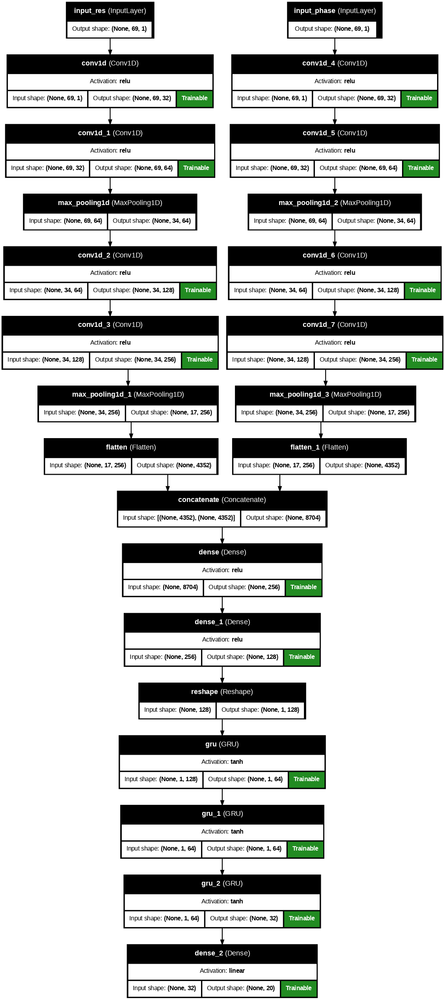

In [ ]:

plot_model(
    model,
    to_file='advanced_model.png',
    show_shapes=True,
    show_layer_names=True,
    show_layer_activations=True,  # Tampilkan aktivasi
    show_trainable=True,          # Tampilkan status trainable
    expand_nested=True,           # Perluas sub-model
    dpi=80                       # Resolusi tinggi
)

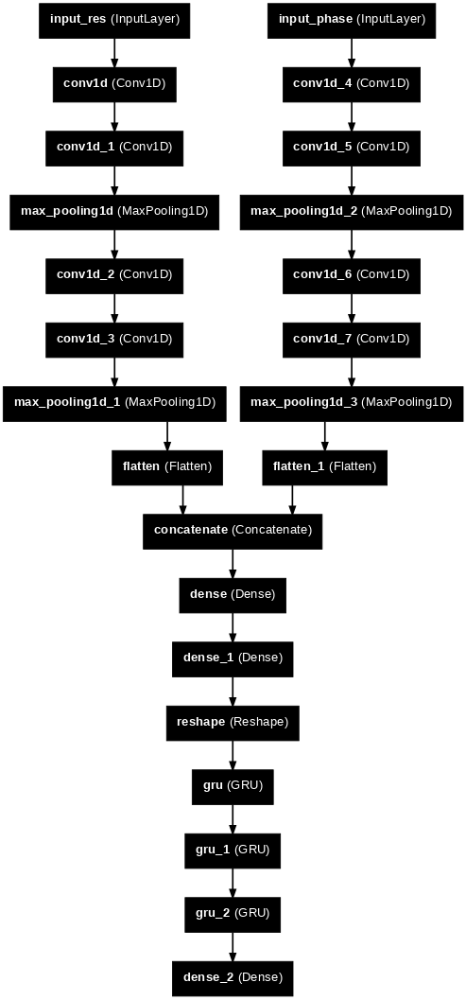

In [ ]:
plot_model(model, to_file='model_simple.png',
           show_shapes=False, show_layer_names=True, dpi=60)

In [ ]:
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_res           │ (None, 69, 1)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_phase         │ (None, 69, 1)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d (Conv1D)     │ (None, 69, 32)    │        128 │ input_res[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_4 (Conv1D)   │ (None, 69, 32)    │        128 │ input_phase[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_1 (Conv1D)   │ (None, 69, 64)    │      6,208 │ conv1d[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_5 (Conv1D)   │ (None, 69, 64)    │      6,208 │ conv1d_4[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d       │ (None, 34, 64)    │          0 │ conv1d_1[0][0]    │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_2     │ (None, 34, 64)    │          0 │ conv1d_5[0][0]    │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_2 (Conv1D)   │ (None, 34, 128)   │     24,704 │ max_pooling1d[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_6 (Conv1D)   │ (None, 34, 128)   │     24,704 │ max_pooling1d_2[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_3 (Conv1D)   │ (None, 34, 256)   │     98,560 │ conv1d_2[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_7 (Conv1D)   │ (None, 34, 256)   │     98,560 │ conv1d_6[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_1     │ (None, 17, 256)   │          0 │ conv1d_3[0][0]    │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_3     │ (None, 17, 256)   │          0 │ conv1d_7[0][0]    │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 4352)      │          0 │ max_pooling1d_1[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_1 (Flatten) │ (None, 4352)      │          0 │ max_pooling1d_3[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 8704)      │          0 │ flatten[0][0],    │
│ (Concatenate)       │                   │            │ flatten_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 256)       │  2,228,480 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 128)       │     32,896 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape (Reshape)   │ (None, 1, 128)    │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gru (GRU)           │ (None, 1, 64)     │     37,248 │ reshape[0][0]     │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 2,592,852 (9.89 MB)

 Trainable params: 2,592,852 (9.89 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
callbacks = [EarlyStopping(monitor='val_loss', patience=15, verbose=1, restore_best_weights=True)]

In [ ]:
    checkpoint_filepath = '/content/drive/MyDrive/Tugas Akhir/Model/checkpoint_Improved_model_V3.h5' # Choose a path in your Drive
    model_checkpoint_callback = ModelCheckpoint(
        filepath=checkpoint_filepath,
        save_weights_only=False, # Set to True if you only want to save weights
        monitor='val_loss',
        mode='min',
        save_best_only=True)

In [ ]:
model.summary()

In [ ]:
    # Use Adam optimizer with learning rate scheduling
model.compile(optimizer = tf.keras.optimizers.Adam(learning_rate=0.0001), loss = tf.keras.losses.MeanSquaredError(), metrics = ['MSE'])

In [ ]:
start = time.time()
history = model.fit(
    x=[X_train_res, X_train_phase],
    y=y_train,
    epochs=200,
    batch_size=16,  # sesuai paper
    validation_data=([X_val_res, X_val_phase], y_val),
    verbose=1,
    callbacks = [callbacks, model_checkpoint_callback]
)
end = time.time()
print(f"Waktu eksekusi: {(end - start) / 60:.2f} menit")

Epoch 1/200
49998/50000 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - MSE: 0.0168 - loss: 0.0168

50000/50000 ━━━━━━━━━━━━━━━━━━━━ 1249s 25ms/step - MSE: 0.0168 - loss: 0.0168 - val_MSE: 0.0046 - val_loss: 0.0046
Epoch 2/200
49998/50000 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - MSE: 0.0044 - loss: 0.0044

50000/50000 ━━━━━━━━━━━━━━━━━━━━ 1243s 25ms/step - MSE: 0.0044 - loss: 0.0044 - val_MSE: 0.0038 - val_loss: 0.0038
Epoch 3/200
49999/50000 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - MSE: 0.0037 - loss: 0.0037

50000/50000 ━━━━━━━━━━━━━━━━━━━━ 1312s 26ms/step - MSE: 0.0037 - loss: 0.0037 - val_MSE: 0.0033 - val_loss: 0.0033
Epoch 4/200
50000/50000 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - MSE: 0.0033 - loss: 0.0033

50000/50000 ━━━━━━━━━━━━━━━━━━━━ 1268s 25ms/step - MSE: 0.0033 - loss: 0.0033 - val_MSE: 0.0031 - val_loss: 0.0031
Epoch 5/200
50000/50000 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - MSE: 0.0030 - loss: 0.0030

50000/50000 ━━━━━━━━━━━━━━━━━━━━ 1251s 25ms/step - MSE: 0.0030 - loss: 0.0030 - val_MSE: 0.0028 - val_loss: 0.0028
Epoch 6/200
49998/50000 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - MSE: 0.0028 - loss: 0.0028

... (31 outputs left out)

50000/50000 ━━━━━━━━━━━━━━━━━━━━ 1092s 22ms/step - MSE: 0.0014 - loss: 0.0014 - val_MSE: 0.0015 - val_loss: 0.0015
Epoch 66/200
50000/50000 ━━━━━━━━━━━━━━━━━━━━ 1104s 22ms/step - MSE: 0.0014 - loss: 0.0014 - val_MSE: 0.0015 - val_loss: 0.0015
Epoch 67/200
50000/50000 ━━━━━━━━━━━━━━━━━━━━ 1139s 23ms/step - MSE: 0.0014 - loss: 0.0014 - val_MSE: 0.0015 - val_loss: 0.0015
Epoch 68/200
50000/50000 ━━━━━━━━━━━━━━━━━━━━ 1127s 23ms/step - MSE: 0.0014 - loss: 0.0014 - val_MSE: 0.0015 - val_loss: 0.0015
Epoch 69/200
50000/50000 ━━━━━━━━━━━━━━━━━━━━ 1096s 22ms/step - MSE: 0.0014 - loss: 0.0014 - val_MSE: 0.0015 - val_loss: 0.0015
Epoch 70/200
50000/50000 ━━━━━━━━━━━━━━━━━━━━ 1115s 22ms/step - MSE: 0.0014 - loss: 0.0014 - val_MSE: 0.0015 - val_loss: 0.0015
Epoch 71/200
50000/50000 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - MSE: 0.0014 - loss: 0.0014

50000/50000 ━━━━━━━━━━━━━━━━━━━━ 1157s 23ms/step - MSE: 0.0014 - loss: 0.0014 - val_MSE: 0.0014 - val_loss: 0.0014
Epoch 72/200
50000/50000 ━━━━━━━━━━━━━━━━━━━━ 1111s 22ms/step - MSE: 0.0014 - loss: 0.0014 - val_MSE: 0.0015 - val_loss: 0.0015
Epoch 73/200
49999/50000 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - MSE: 0.0014 - loss: 0.0014

50000/50000 ━━━━━━━━━━━━━━━━━━━━ 1177s 24ms/step - MSE: 0.0014 - loss: 0.0014 - val_MSE: 0.0014 - val_loss: 0.0014
Epoch 74/200
50000/50000 ━━━━━━━━━━━━━━━━━━━━ 1180s 24ms/step - MSE: 0.0014 - loss: 0.0014 - val_MSE: 0.0014 - val_loss: 0.0014
Epoch 75/200
49999/50000 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - MSE: 0.0014 - loss: 0.0014

50000/50000 ━━━━━━━━━━━━━━━━━━━━ 1141s 23ms/step - MSE: 0.0014 - loss: 0.0014 - val_MSE: 0.0014 - val_loss: 0.0014
Epoch 76/200
50000/50000 ━━━━━━━━━━━━━━━━━━━━ 1112s 22ms/step - MSE: 0.0014 - loss: 0.0014 - val_MSE: 0.0014 - val_loss: 0.0014
Epoch 77/200
 9337/50000 ━━━━━━━━━━━━━━━━━━━━ 13:42 20ms/step - MSE: 0.0014 - loss: 0.0014

In [ ]:
model2 = tf.keras.models.load_model('/content/drive/MyDrive/Tugas Akhir/Model/checkpoint_Improved_model_V3.h5')

In [ ]:
    # Use Adam optimizer with learning rate scheduling
model2.compile(optimizer = tf.keras.optimizers.Adam(learning_rate=0.0001), loss = tf.keras.losses.MeanSquaredError(), metrics = ['MSE'])

In [ ]:
start = time.time()
history = model2.fit(
    x=[X_train_res, X_train_phase],
    y=y_train,
    epochs=200,
    initial_epoch = 76,
    batch_size=16,  # sesuai paper
    validation_data=([X_val_res, X_val_phase], y_val),
    verbose=1,
    callbacks = [callbacks, model_checkpoint_callback]
)
end = time.time()
print(f"Waktu eksekusi: {(end - start) / 60:.2f} menit")

Epoch 77/200
49998/50000 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - MSE: 0.0014 - loss: 0.0014

50000/50000 ━━━━━━━━━━━━━━━━━━━━ 1094s 22ms/step - MSE: 0.0014 - loss: 0.0014 - val_MSE: 0.0014 - val_loss: 0.0014
Epoch 78/200
50000/50000 ━━━━━━━━━━━━━━━━━━━━ 1007s 20ms/step - MSE: 0.0014 - loss: 0.0014 - val_MSE: 0.0015 - val_loss: 0.0015
Epoch 79/200
50000/50000 ━━━━━━━━━━━━━━━━━━━━ 1005s 20ms/step - MSE: 0.0014 - loss: 0.0014 - val_MSE: 0.0014 - val_loss: 0.0014
Epoch 80/200
49998/50000 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - MSE: 0.0013 - loss: 0.0013

50000/50000 ━━━━━━━━━━━━━━━━━━━━ 999s 20ms/step - MSE: 0.0013 - loss: 0.0013 - val_MSE: 0.0014 - val_loss: 0.0014
Epoch 81/200
50000/50000 ━━━━━━━━━━━━━━━━━━━━ 999s 20ms/step - MSE: 0.0013 - loss: 0.0013 - val_MSE: 0.0014 - val_loss: 0.0014
Epoch 82/200
50000/50000 ━━━━━━━━━━━━━━━━━━━━ 993s 20ms/step - MSE: 0.0013 - loss: 0.0013 - val_MSE: 0.0014 - val_loss: 0.0014
Epoch 83/200
50000/50000 ━━━━━━━━━━━━━━━━━━━━ 997s 20ms/step - MSE: 0.0013 - loss: 0.0013 - val_MSE: 0.0014 - val_loss: 0.0014
Epoch 84/200
50000/50000 ━━━━━━━━━━━━━━━━━━━━ 991s 20ms/step - MSE: 0.0013 - loss: 0.0013 - val_MSE: 0.0014 - val_loss: 0.0014
Epoch 85/200
50000/50000 ━━━━━━━━━━━━━━━━━━━━ 994s 20ms/step - MSE: 0.0013 - loss: 0.0013 - val_MSE: 0.0014 - val_loss: 0.0014
Epoch 86/200
50000/50000 ━━━━━━━━━━━━━━━━━━━━ 993s 20ms/step - MSE: 0.0013 - loss: 0.0013 - val_MSE: 0.0016 - val_loss: 0.0016
Epoch 87/200
50000/50000 ━━━━━━━━━━━━━━━━━━━━ 992s 20ms/step - MSE: 0.0013 - loss: 0.0013 - val_MSE: 0.0014 - val_loss: 0.00

50000/50000 ━━━━━━━━━━━━━━━━━━━━ 1001s 20ms/step - MSE: 0.0013 - loss: 0.0013 - val_MSE: 0.0014 - val_loss: 0.0014
Epoch 91/200
50000/50000 ━━━━━━━━━━━━━━━━━━━━ 1001s 20ms/step - MSE: 0.0013 - loss: 0.0013 - val_MSE: 0.0014 - val_loss: 0.0014
Epoch 92/200
50000/50000 ━━━━━━━━━━━━━━━━━━━━ 1003s 20ms/step - MSE: 0.0013 - loss: 0.0013 - val_MSE: 0.0015 - val_loss: 0.0015
Epoch 93/200
50000/50000 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - MSE: 0.0013 - loss: 0.0013

50000/50000 ━━━━━━━━━━━━━━━━━━━━ 999s 20ms/step - MSE: 0.0013 - loss: 0.0013 - val_MSE: 0.0014 - val_loss: 0.0014
Epoch 94/200
50000/50000 ━━━━━━━━━━━━━━━━━━━━ 997s 20ms/step - MSE: 0.0013 - loss: 0.0013 - val_MSE: 0.0014 - val_loss: 0.0014
Epoch 95/200
50000/50000 ━━━━━━━━━━━━━━━━━━━━ 1006s 20ms/step - MSE: 0.0013 - loss: 0.0013 - val_MSE: 0.0014 - val_loss: 0.0014
Epoch 96/200
50000/50000 ━━━━━━━━━━━━━━━━━━━━ 995s 20ms/step - MSE: 0.0013 - loss: 0.0013 - val_MSE: 0.0014 - val_loss: 0.0014
Epoch 97/200
50000/50000 ━━━━━━━━━━━━━━━━━━━━ 1002s 20ms/step - MSE: 0.0013 - loss: 0.0013 - val_MSE: 0.0014 - val_loss: 0.0014
Epoch 98/200
50000/50000 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - MSE: 0.0013 - loss: 0.0013

50000/50000 ━━━━━━━━━━━━━━━━━━━━ 1005s 20ms/step - MSE: 0.0013 - loss: 0.0013 - val_MSE: 0.0014 - val_loss: 0.0014
Epoch 99/200
50000/50000 ━━━━━━━━━━━━━━━━━━━━ 998s 20ms/step - MSE: 0.0013 - loss: 0.0013 - val_MSE: 0.0014 - val_loss: 0.0014
Epoch 100/200
49999/50000 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - MSE: 0.0013 - loss: 0.0013

... (6 outputs left out)

50000/50000 ━━━━━━━━━━━━━━━━━━━━ 1011s 20ms/step - MSE: 0.0012 - loss: 0.0012 - val_MSE: 0.0013 - val_loss: 0.0013
Epoch 136/200
50000/50000 ━━━━━━━━━━━━━━━━━━━━ 1009s 20ms/step - MSE: 0.0012 - loss: 0.0012 - val_MSE: 0.0014 - val_loss: 0.0014
Epoch 137/200
50000/50000 ━━━━━━━━━━━━━━━━━━━━ 1000s 20ms/step - MSE: 0.0012 - loss: 0.0012 - val_MSE: 0.0013 - val_loss: 0.0013
Epoch 138/200
50000/50000 ━━━━━━━━━━━━━━━━━━━━ 999s 20ms/step - MSE: 0.0012 - loss: 0.0012 - val_MSE: 0.0013 - val_loss: 0.0013
Epoch 139/200
50000/50000 ━━━━━━━━━━━━━━━━━━━━ 1012s 20ms/step - MSE: 0.0012 - loss: 0.0012 - val_MSE: 0.0013 - val_loss: 0.0013
Epoch 140/200
50000/50000 ━━━━━━━━━━━━━━━━━━━━ 1018s 20ms/step - MSE: 0.0012 - loss: 0.0012 - val_MSE: 0.0013 - val_loss: 0.0013
Epoch 141/200
50000/50000 ━━━━━━━━━━━━━━━━━━━━ 1020s 20ms/step - MSE: 0.0012 - loss: 0.0012 - val_MSE: 0.0013 - val_loss: 0.0013
Epoch 142/200
50000/50000 ━━━━━━━━━━━━━━━━━━━━ 1012s 20ms/step - MSE: 0.0012 - loss: 0.0012 - val_MSE: 0.0013 - 

50000/50000 ━━━━━━━━━━━━━━━━━━━━ 1010s 20ms/step - MSE: 0.0012 - loss: 0.0012 - val_MSE: 0.0013 - val_loss: 0.0013
Epoch 145/200
50000/50000 ━━━━━━━━━━━━━━━━━━━━ 1014s 20ms/step - MSE: 0.0012 - loss: 0.0012 - val_MSE: 0.0013 - val_loss: 0.0013
Epoch 146/200
50000/50000 ━━━━━━━━━━━━━━━━━━━━ 1011s 20ms/step - MSE: 0.0012 - loss: 0.0012 - val_MSE: 0.0013 - val_loss: 0.0013
Epoch 147/200
50000/50000 ━━━━━━━━━━━━━━━━━━━━ 1011s 20ms/step - MSE: 0.0012 - loss: 0.0012 - val_MSE: 0.0013 - val_loss: 0.0013
Epoch 148/200
50000/50000 ━━━━━━━━━━━━━━━━━━━━ 1019s 20ms/step - MSE: 0.0012 - loss: 0.0012 - val_MSE: 0.0013 - val_loss: 0.0013
Epoch 149/200
50000/50000 ━━━━━━━━━━━━━━━━━━━━ 1010s 20ms/step - MSE: 0.0012 - loss: 0.0012 - val_MSE: 0.0013 - val_loss: 0.0013
Epoch 150/200
50000/50000 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - MSE: 0.0012 - loss: 0.0012

50000/50000 ━━━━━━━━━━━━━━━━━━━━ 1010s 20ms/step - MSE: 0.0012 - loss: 0.0012 - val_MSE: 0.0013 - val_loss: 0.0013
Epoch 151/200
50000/50000 ━━━━━━━━━━━━━━━━━━━━ 1018s 20ms/step - MSE: 0.0012 - loss: 0.0012 - val_MSE: 0.0014 - val_loss: 0.0014
Epoch 152/200
50000/50000 ━━━━━━━━━━━━━━━━━━━━ 1010s 20ms/step - MSE: 0.0012 - loss: 0.0012 - val_MSE: 0.0013 - val_loss: 0.0013
Epoch 153/200
50000/50000 ━━━━━━━━━━━━━━━━━━━━ 1020s 20ms/step - MSE: 0.0012 - loss: 0.0012 - val_MSE: 0.0013 - val_loss: 0.0013
Epoch 154/200
50000/50000 ━━━━━━━━━━━━━━━━━━━━ 1013s 20ms/step - MSE: 0.0012 - loss: 0.0012 - val_MSE: 0.0013 - val_loss: 0.0013
Epoch 155/200
50000/50000 ━━━━━━━━━━━━━━━━━━━━ 1021s 20ms/step - MSE: 0.0012 - loss: 0.0012 - val_MSE: 0.0013 - val_loss: 0.0013
Epoch 156/200
50000/50000 ━━━━━━━━━━━━━━━━━━━━ 1029s 21ms/step - MSE: 0.0012 - loss: 0.0012 - val_MSE: 0.0013 - val_loss: 0.0013
Epoch 157/200
50000/50000 ━━━━━━━━━━━━━━━━━━━━ 1027s 21ms/step - MSE: 0.0012 - loss: 0.0012 - val_MSE: 0.0013 -

50000/50000 ━━━━━━━━━━━━━━━━━━━━ 1019s 20ms/step - MSE: 0.0012 - loss: 0.0012 - val_MSE: 0.0013 - val_loss: 0.0013
Epoch 161/200
 2075/50000 ━━━━━━━━━━━━━━━━━━━━ 15:08 19ms/step - MSE: 0.0012 - loss: 0.0012

In [ ]:
# Ambil data MSE dari riwayat training
mse_training = history.history['loss']
mse_validation = history.history['val_loss']

# Buat plot
plt.plot(mse_training, label='MSE Training')
plt.plot(mse_validation, label='MSE Validation')
plt.title('Kurva MSE Training dan Validation')
plt.xlim(0, len(mse_training))
plt.ylim(0, max(mse_training))
plt.xlabel('Epoch')
plt.ylabel('MSE')
plt.legend()
plt.show()

In [ ]:
model2.save('/content/drive/MyDrive/Tugas Akhir/Model/CNN_GRU_Model_Improved_takhingga_log_4.h5')

#Deploy model dan Prediksi

In [29]:
model = tf.keras.models.load_model('/content/drive/MyDrive/Tugas Akhir/Model/checkpoint_Improved_model_V3.h5')

In [30]:
import numpy as np

# ... (kode untuk forward modelling dan fungsi normalisasi/denormalisasi) ...


# Forward modelling untuk data input
resis_true= np.array([1000, 800, 200, 50])
ketebalan_true = np.array([200, 500, 1000])

resistivitas_semu, fasa = forward_modelling(resis_true, ketebalan_true, frequencies)

resistivitas_semu = np.array([resistivitas_semu])
fasa = np.array([fasa])

#Reshape sebelum Logaritma
resistivitas_semu = resistivitas_semu[0].reshape(1, X_input_res.shape[1]) # Corrected reshape syntax
fasa = fasa.reshape(1, X_input_phase.shape[1])

#Logaritma data input
resistivitas_semu_log = np.log10(resistivitas_semu)
fasa_log = np.log10(fasa)

# Normalisasi data input
resistivitas_semu_normalized = input_res_scaler.transform(resistivitas_semu_log)
fasa_normalized = input_phase_scaler.transform(fasa_log)

# Reshape jika perlu (misalnya, untuk input CNN)
resistivitas_semu_normalized = resistivitas_semu_normalized.reshape(1, X_input_res.shape[1], 1)
fasa_normalized = fasa_normalized.reshape(1, X_input_phase.shape[1], 1)

# Prediksi
predictions = model.predict([resistivitas_semu_normalized, fasa_normalized])

# Denormalisasi hasil prediksi, apply to the predictions, not hasil
predictions_denormalized = output_model_scaler.inverse_transform(predictions)

# Delogaritmik hasil prediksi
predictions_denormalized = np.power(10, predictions_denormalized)

# Accessing the values from predictions_denormalized
resis_predict = predictions_denormalized[0] #
ketebalan_predict = np.full(jumlah_layer-1,layer_thickness)

#Forward Modelling from prediction model
resistivitas_semu_predict, fasa_predict = forward_modelling(resis_predict,ketebalan_predict,frequencies)
resistivitas_semu_predict = np.array([resistivitas_semu_predict])
fasa_predict = np.array([fasa_predict])


#print(hasil) #No need to print hasil as it's not used

print("Nilai Resis_True", resis_true)
print("Nilai ketebalan_True",ketebalan_true)
print("Nilai resis_predict",resis_predict)
print("Nilai ketebalan_predict",ketebalan_predict)

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 875ms/step
Nilai Resis_True [1000  800  200   50]
Nilai ketebalan_True [ 200  500 1000]
Nilai resis_predict [991.7686   796.6119   932.8809   374.87903  196.37386  207.79977
 173.42241  314.12518   69.442635  50.6901    53.28848   49.714672
  49.813404  50.94802   53.254963  50.369884  51.607296  49.938423
  52.32385   47.78992 ]
Nilai ketebalan_predict [200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200.
 200. 200. 200. 200. 200.]


#Perhitungan Error

In [31]:
measure_MSE(resistivitas_semu[0], fasa[0], resistivitas_semu_predict[0], fasa_predict[0])

MSE Resistivitas Semu: 32.33
MSE Fasa: 0.07


In [32]:
measure_MAPE(resistivitas_semu, fasa, resistivitas_semu_predict[0], fasa_predict[0])

MAPE resistivitas semu: 1.97%
MAPE fasa: 0.41%


(np.float64(1.9666545024841782), np.float64(0.40656402893269716))

In [33]:
measure_RMSE(resistivitas_semu[0], fasa[0], resistivitas_semu_predict[0], fasa_predict[0])

RMSE Resistivitas Semu: 5.69
RMSE Fasa: 0.26


[Interpolated] MSE model resistivitas: 7297.2136
[Interpolated] RMSE model resistivitas: 85.4237
[Interpolated] MAPE model resistivitas: 12.34%


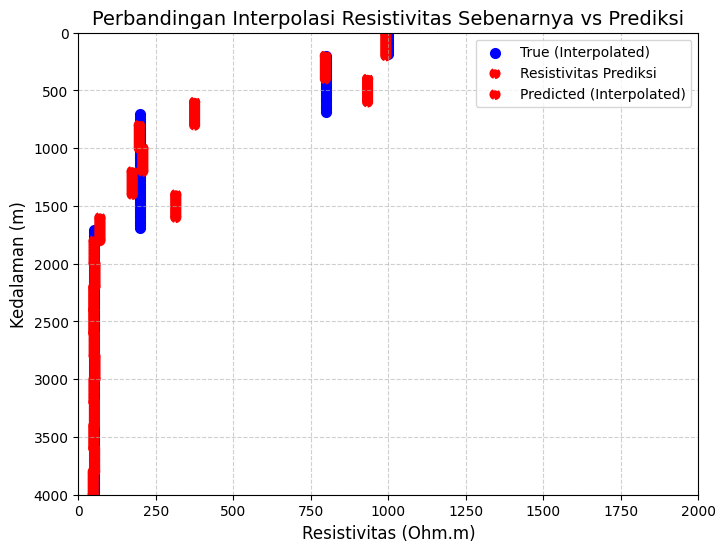

In [34]:
measure_interpolated_resistivities(resis_true,ketebalan_true,resis_predict,ketebalan_predict,total_depth)

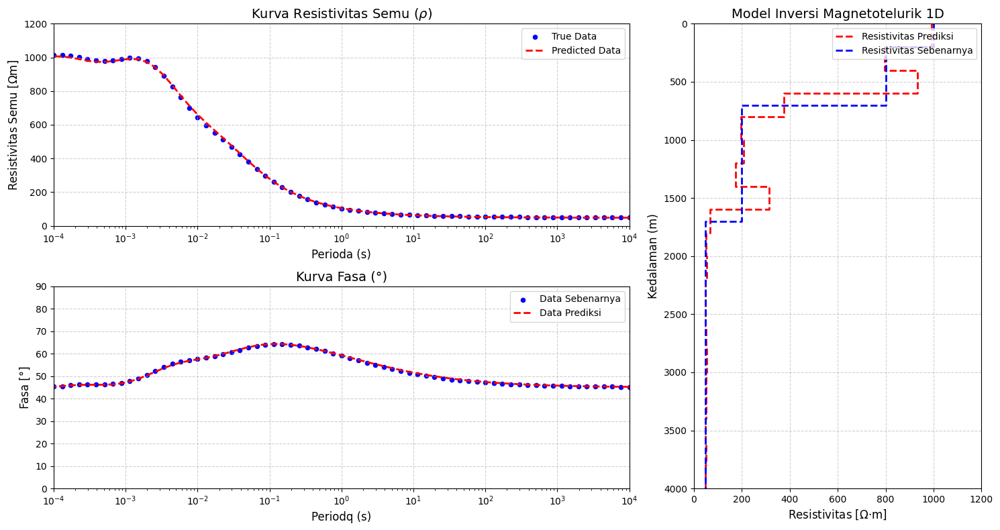

In [35]:
plot_MT_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, 1/frequencies, fasa, resistivitas_semu, fasa_predict, resistivitas_semu_predict, total_depth)

#Grafik

In [36]:
def plot_appres(resistivitas_semu, resistivitas_semu_predict,frequencies):
  plt.figure(figsize=(6, 3))

  plt.scatter(1/frequencies, resistivitas_semu[0], color='blue', label='True Data', s=6)
  plt.plot(1/frequencies, resistivitas_semu_predict[0], color='red', label='Prediction Data', linestyle = '-')

  plt.xscale('log')
  plt.xlim(1e-4, 1e4)
  plt.ylim(0, 1200)
  plt.xlabel('Period (s)', fontsize=10)
  plt.ylabel('Apparent Resistivity ($\Omega$m)', fontsize=9)
  plt.grid(True, linestyle='--', alpha=0.6)

  plt.legend(fontsize = 10)
  plt.show()


<>:11: SyntaxWarning: invalid escape sequence '\O'
<>:11: SyntaxWarning: invalid escape sequence '\O'
/tmp/ipython-input-2517529506.py:11: SyntaxWarning: invalid escape sequence '\O'
  plt.ylabel('Apparent Resistivity ($\Omega$m)', fontsize=9)


In [37]:
def plot_phase(fasa, fasa_predict,frequencies):
  plt.figure(figsize=(6, 3))

  plt.scatter(1/frequencies, fasa[0], color='blue', label='True Data', s=6)
  plt.plot(1/frequencies, fasa_predict[0], color='red', label='Prediction Data', linestyle = '-')

  plt.xscale('log')
  plt.xlim(1e-4, 1e4)
  plt.ylim(0, 90)
  plt.xlabel('Period (s)', fontsize=10)
  plt.ylabel('Phase [°]', fontsize=10)
  plt.grid(True, linestyle='--', alpha=0.6)

  plt.legend(fontsize = 9)
  plt.show()


In [38]:
def plot_model_compare_2(res_true, ketebalan_true, res_predict, ketebalan_predict, total_depth):
  depth_true_plot, resis_true_plot = formating_result(resis_true, ketebalan_true, total_depth)
  depth_pred_plot, resis_pred_plot = formating_result(resis_predict , ketebalan_predict, total_depth)

  # Buat plot
  plt.figure(figsize=(6, 6))

  # Plot Resistivitas Sebenarnya (True)
  plt.plot(resis_true_plot, depth_true_plot, label='True Model', color='blue', linewidth=2)

  # Plot Resistivitas Prediksi (Pred)
  plt.plot(resis_pred_plot, depth_pred_plot, label='Predicted Model', color='red', linestyle='--', linewidth=2)

  # Pengaturan sumbu dan grafik
  plt.xlabel('Resistivity ($\Omega$m)', fontsize=12)
  plt.ylabel('Depth (m)', fontsize=12)
  plt.legend(loc='upper right', fontsize = 9)
  plt.grid(True, linestyle='--', alpha=0.6)

  # Sesuaikan rentang sumbu
  plt.xlim(0, 1200)  # Rentang resistivitas dari 0 hingga 1200 Ohm.m
  plt.ylim(4000, 0)  # Rentang kedalaman dari 0 hingga 1000 m (dibalik agar makin dalam ke bawah)

  plt.show()

<>:15: SyntaxWarning: invalid escape sequence '\O'
<>:15: SyntaxWarning: invalid escape sequence '\O'
/tmp/ipython-input-1980269464.py:15: SyntaxWarning: invalid escape sequence '\O'
  plt.xlabel('Resistivity ($\Omega$m)', fontsize=12)


In [39]:
import matplotlib.pyplot as plt

def plot_model_full(res_true, ketebalan_true,
                    res_predict, ketebalan_predict,
                    resistivitas_semu, resistivitas_semu_predict,
                    fasa, fasa_predict,
                    frequencies, total_depth):

    # --- Format data untuk model ---
    depth_true_plot, resis_true_plot = formating_result(res_true, ketebalan_true, total_depth)
    depth_pred_plot, resis_pred_plot = formating_result(res_predict, ketebalan_predict, total_depth)
    mape_appres, mape_phase = measure_MAPE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

    periods = 1/frequencies

    # --- Buat figure 1 row 3 kolom ---
    fig, axs = plt.subplots(1, 3, figsize=(12, 4))

    # ========== 1. Plot Model Resistivitas ==========
    axs[0].plot(resis_true_plot, depth_true_plot, color='blue', label='True Model', linewidth=2)
    axs[0].plot(resis_pred_plot, depth_pred_plot, color='red', linestyle='--', label='Predicted Model', linewidth=2)
    axs[0].set_xlabel('Resistivity ($\Omega$m)', fontsize=10)
    axs[0].set_ylabel('Depth (m)', fontsize=10)
    axs[0].set_xlim(0, 1200)
    axs[0].set_ylim(total_depth, 0)
    axs[0].grid(True, linestyle='--', alpha=0.6)

    # ========== 2. Plot Apparent Resistivity ==========
    axs[1].scatter(periods, resistivitas_semu[0], color='blue', s=6, label='True Data')
    axs[1].plot(periods, resistivitas_semu_predict[0], color='red', linestyle='-', label='Prediction Data')
    axs[1].set_xscale('log')
    axs[1].set_xlim(1e-4, 1e4)
    axs[1].set_ylim(0, 1200)
    axs[1].set_xlabel('Period (s)', fontsize=10)
    axs[1].set_ylabel('App. Resistivity ($\Omega$m)', fontsize=9)
    axs[1].grid(True, linestyle='--', alpha=0.6)

    # ========== 3. Plot Phase ==========
    axs[2].scatter(periods, fasa[0], color='blue', s=6, label='True Data')
    axs[2].plot(periods, fasa_predict[0], color='red', linestyle='-', label='Prediction Data')
    axs[2].set_xscale('log')
    axs[2].set_xlim(1e-4, 1e4)
    axs[2].set_ylim(0, 90)
    axs[2].set_xlabel('Period (s)', fontsize=10)
    axs[2].set_ylabel('Phase (°)', fontsize=10)
    axs[2].grid(True, linestyle='--', alpha=0.6)

    # # --- Legend gabungan di bawah figure (tanpa duplikat) ---
    # lines, labels = [], []
    # for ax in axs:
    #     line, label = ax.get_legend_handles_labels()
    #     lines.extend(line)
    #     labels.extend(label)

    # # Hilangkan label duplikat dengan dict (hanya ambil pertama kali muncul)
    # by_label = dict(zip(labels, lines))

    # fig.legend(by_label.values(), by_label.keys(),
    #           loc='lower center', ncol=3, frameon=False, fontsize=9)

    plt.figtext(0.5, 0.01,
            f"MAPE Apparent Resistivity: {mape_appres:.2f}%  |   MAPE Phase: {mape_phase:.2f}%",
            wrap=True, horizontalalignment='center', fontsize=13,
            bbox=dict(facecolor='white', edgecolor='gray', alpha=0.5))

    plt.tight_layout(rect=[0,0.08,1,1])  # beri ruang untuk legend
    plt.show()


<>:22: SyntaxWarning: invalid escape sequence '\O'
<>:35: SyntaxWarning: invalid escape sequence '\O'
<>:22: SyntaxWarning: invalid escape sequence '\O'
<>:35: SyntaxWarning: invalid escape sequence '\O'
/tmp/ipython-input-1812567841.py:22: SyntaxWarning: invalid escape sequence '\O'
  axs[0].set_xlabel('Resistivity ($\Omega$m)', fontsize=10)
/tmp/ipython-input-1812567841.py:35: SyntaxWarning: invalid escape sequence '\O'
  axs[1].set_ylabel('App. Resistivity ($\Omega$m)', fontsize=9)


MAPE resistivitas semu: 1.97%
MAPE fasa: 0.41%


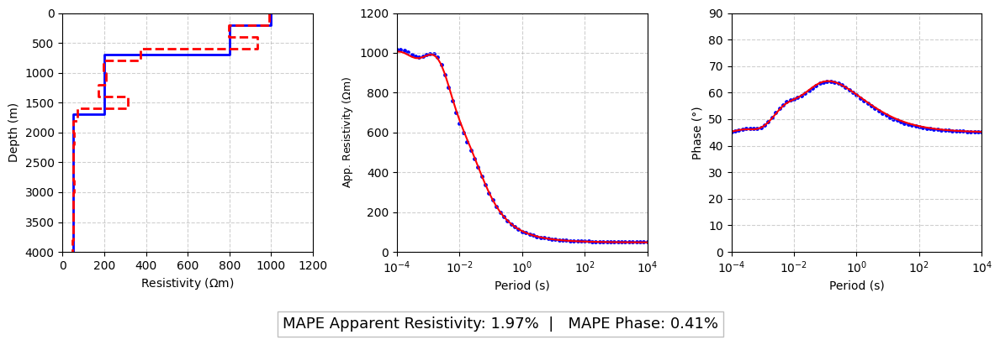

In [40]:
plot_model_full(resis_true, ketebalan_true,
                    resis_predict, ketebalan_predict,
                    resistivitas_semu, resistivitas_semu_predict,
                    fasa, fasa_predict,
                    frequencies, total_depth)

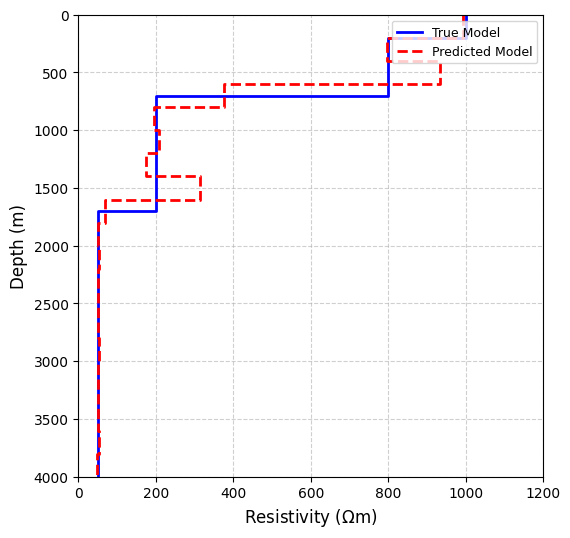

In [41]:
plot_model_compare_2(resis_true,ketebalan_true,resis_predict,ketebalan_predict,total_depth)

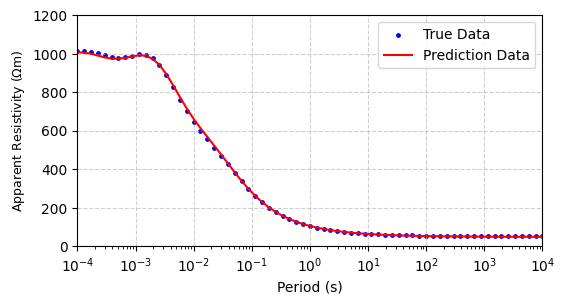

In [ ]:
plot_appres(resistivitas_semu, resistivitas_semu_predict,frequencies)

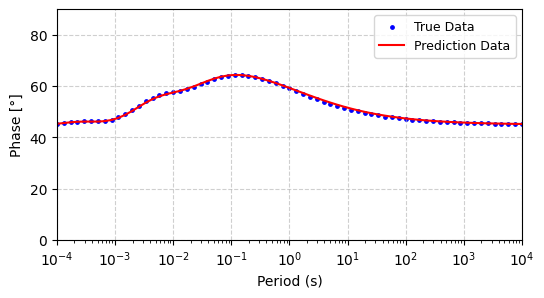

In [ ]:
plot_phase(fasa, fasa_predict,frequencies)

# Prediksi Data Training

## Prediksi

In [ ]:
# Ambil ground truth untuk sample ke-0
resis_true = y_train[0].reshape(1, -1)
resis_true = output_model_scaler.inverse_transform(resis_true)  # Undo MinMax
resis_true = np.power(10, resis_true)  # Undo log10

ketebalan_true = np.full(jumlah_layer-1, layer_thickness)

# Ambil input data asli sample ke-0 dan inverse normalisasi
resistivitas_semu = X_train_res[0].reshape(1, -1)
fasa = X_train_phase[0].reshape(1, -1)

# Undo normalisasi (hasilnya masih log10)
resistivitas_semu_log = input_res_scaler.inverse_transform(resistivitas_semu)
fasa_log = input_phase_scaler.inverse_transform(fasa)

# Undo logaritma → dapat nilai asli
resistivitas_semu = np.power(10, resistivitas_semu_log)
fasa = np.power(10, fasa_log)

# Sekarang: jika kamu ingin **prediksi ulang**, maka:
# 1. Ambil resistivitas_semu & fasa (asli), lalu
# 2. log10 lagi → normalisasi lagi

resistivitas_semu_log = np.log10(resistivitas_semu)
fasa_log = np.log10(fasa)

resistivitas_semu_normalized = input_res_scaler.transform(resistivitas_semu_log)
fasa_normalized = input_phase_scaler.transform(fasa_log)

# Reshape untuk CNN-GRU input
resistivitas_semu_normalized = resistivitas_semu_normalized.reshape(1, X_input_res.shape[1], 1)
fasa_normalized = fasa_normalized.reshape(1, X_input_phase.shape[1], 1)

# Prediksi model
predictions = model.predict([resistivitas_semu_normalized, fasa_normalized])

# Undo normalisasi dan log10 dari output
predictions_denormalized = output_model_scaler.inverse_transform(predictions)
predictions_denormalized = np.power(10, predictions_denormalized)

# Split hasil prediksi
resis_predict = predictions_denormalized[0]  # jika output hanya resistivitas saja
ketebalan_predict = np.full(jumlah_layer-1, layer_thickness)

# Forward modelling
resistivitas_semu_predict, fasa_predict = forward_modelling(resis_predict, ketebalan_predict, frequencies)

resistivitas_semu_predict = np.array([resistivitas_semu_predict])
fasa_predict = np.array([fasa_predict])

#print(hasil) #No need to print hasil as it's not used


print("Nilai resis_predict",resis_predict)
print("Nilai ketebalan_predict",ketebalan_predict)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 232ms/step
Nilai resis_predict [820.67865 814.7638  810.27295 818.2017  833.68805 819.4199  823.26605
 812.5929  840.02936 819.711   821.22034 800.7738  823.8403  816.55225
 827.0449  844.7789  836.3018  812.4876  825.17596 807.8075 ]
Nilai ketebalan_predict [200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200.
 200. 200. 200. 200. 200.]


## Error

In [ ]:
measure_MSE(resistivitas_semu[0], fasa[0], resistivitas_semu_predict[0], fasa_predict[0])


MSE Resistivitas Semu: 41.17
MSE Fasa: 0.00


In [ ]:
measure_MAPE(resistivitas_semu[0], fasa[0], resistivitas_semu_predict[0], fasa_predict[0])

MAPE resistivitas semu: 0.64%
MAPE fasa: 0.11%


(np.float64(0.6370115622612561), np.float64(0.11366799744175946))

In [ ]:
measure_RMSE(resistivitas_semu[0], fasa[0], resistivitas_semu_predict[0], fasa_predict[0])

RMSE Resistivitas Semu: 6.42
RMSE Fasa: 0.07


[Interpolated] MSE model resistivitas: 126.6838
[Interpolated] RMSE model resistivitas: 11.2554
[Interpolated] MAPE model resistivitas: 1.04%


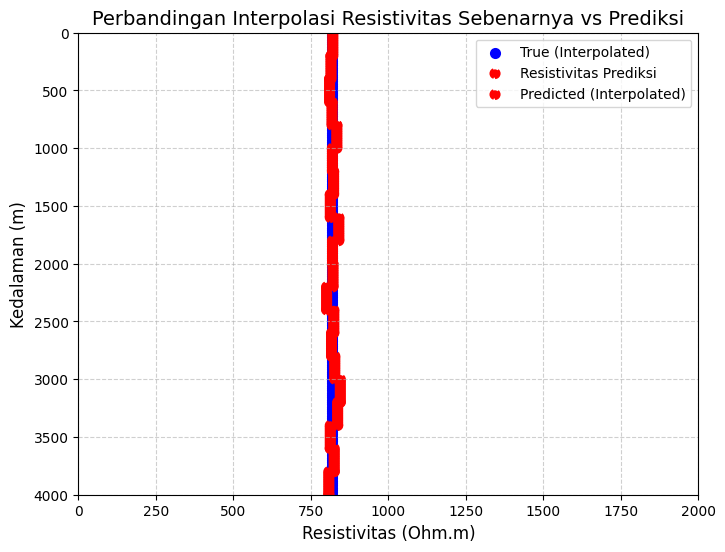

In [ ]:
measure_interpolated_resistivities(resis_true,ketebalan_true,resis_predict,ketebalan_predict,total_depth)

##Grafik


MAPE resistivitas semu: 0.64%
MAPE fasa: 0.11%


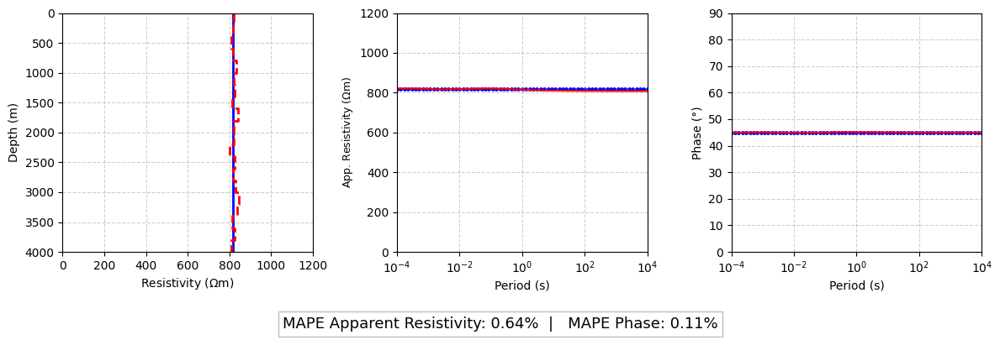

In [ ]:
plot_model_full(resis_true, ketebalan_true,
                    resis_predict, ketebalan_predict,
                    resistivitas_semu, resistivitas_semu_predict,
                    fasa, fasa_predict,
                    frequencies, total_depth)

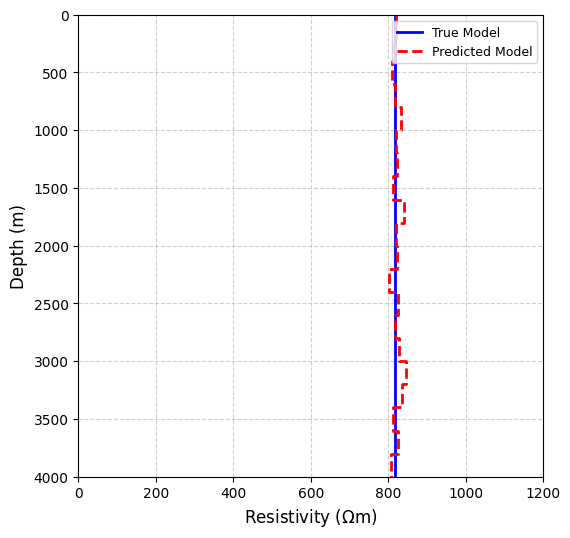

In [ ]:
plot_model_compare_2(resis_true,ketebalan_true,resis_predict,ketebalan_predict,total_depth)


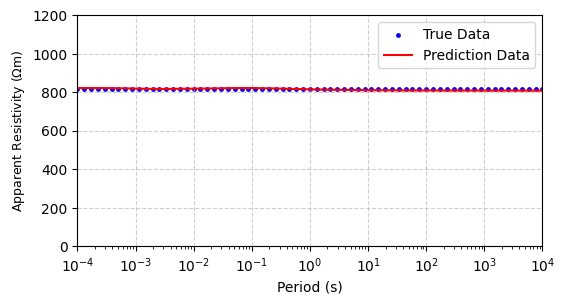

In [ ]:
plot_appres(resistivitas_semu, resistivitas_semu_predict,frequencies)

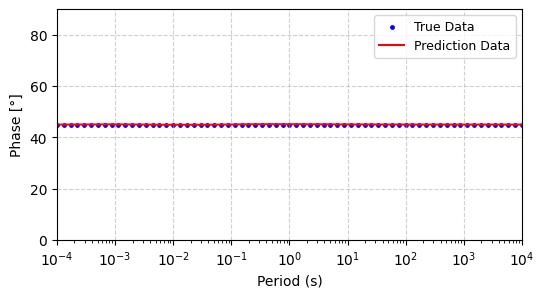

In [ ]:
plot_phase(fasa, fasa_predict,frequencies)

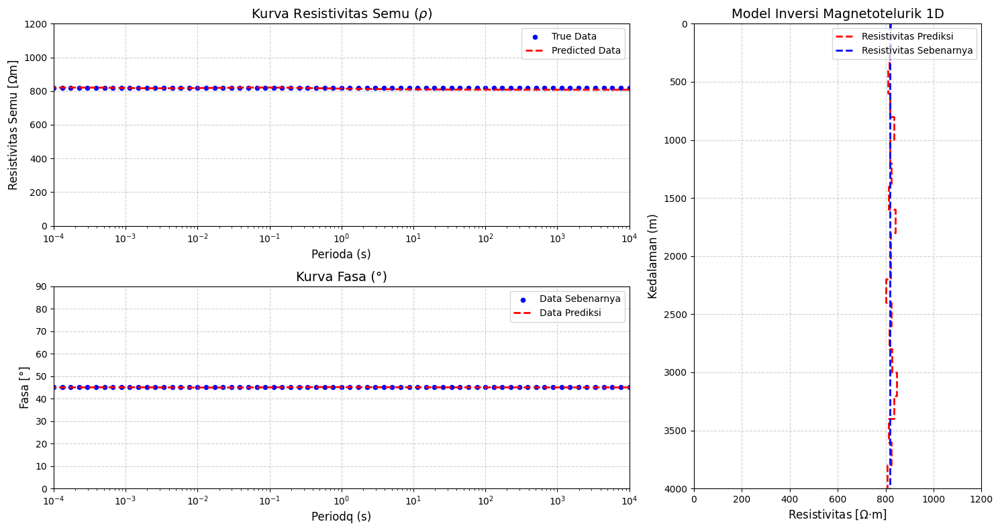

In [ ]:
plot_MT_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, 1/frequencies, fasa, resistivitas_semu, fasa_predict, resistivitas_semu_predict, total_depth)

# Prediksi Data validasi

## Prediksi

In [ ]:
# Ambil ground truth untuk sample ke-0
resis_true = y_val[2].reshape(1, -1)
resis_true = output_model_scaler.inverse_transform(resis_true)  # Undo MinMax
resis_true = np.power(10, resis_true)  # Undo log10

ketebalan_true = np.full(jumlah_layer-1, layer_thickness)

# Ambil input data asli sample ke-0 dan inverse normalisasi
resistivitas_semu = X_val_res[2].reshape(1, -1)
fasa = X_val_phase[2].reshape(1, -1)

# Undo normalisasi (hasilnya masih log10)
resistivitas_semu_log = input_res_scaler.inverse_transform(resistivitas_semu)
fasa_log = input_phase_scaler.inverse_transform(fasa)

# Undo logaritma → dapat nilai asli
resistivitas_semu = np.power(10, resistivitas_semu_log)
fasa = np.power(10, fasa_log)

# Sekarang: jika kamu ingin **prediksi ulang**, maka:
# 1. Ambil resistivitas_semu & fasa (asli), lalu
# 2. log10 lagi → normalisasi lagi

resistivitas_semu_log = np.log10(resistivitas_semu)
fasa_log = np.log10(fasa)

resistivitas_semu_normalized = input_res_scaler.transform(resistivitas_semu_log)
fasa_normalized = input_phase_scaler.transform(fasa_log)

# Reshape untuk CNN-GRU input
resistivitas_semu_normalized = resistivitas_semu_normalized.reshape(1, X_input_res.shape[1], 1)
fasa_normalized = fasa_normalized.reshape(1, X_input_phase.shape[1], 1)

# Prediksi model
predictions = model.predict([resistivitas_semu_normalized, fasa_normalized])

# Undo normalisasi dan log10 dari output
predictions_denormalized = output_model_scaler.inverse_transform(predictions)
predictions_denormalized = np.power(10, predictions_denormalized)

# Split hasil prediksi
resis_predict = predictions_denormalized[0]  # jika output hanya resistivitas saja
ketebalan_predict = np.full(jumlah_layer-1, layer_thickness)

# Forward modelling
resistivitas_semu_predict, fasa_predict = forward_modelling(resis_predict, ketebalan_predict, frequencies)

resistivitas_semu_predict = np.array([resistivitas_semu_predict])
fasa_predict = np.array([fasa_predict])

#print(hasil) #No need to print hasil as it's not used


print("Nilai resis_predict",resis_predict)
print("Nilai ketebalan_predict",ketebalan_predict)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step
Nilai resis_predict [818.09753 948.7007  952.86017 960.4327  942.11707 925.7091  961.57806
 904.3097  979.6807  951.20654 955.7741  940.24976 839.65686 559.29333
 561.8954  528.15063 547.23004 521.3321  524.15936 518.40564]
Nilai ketebalan_predict [200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200.
 200. 200. 200. 200. 200.]


## Error

In [ ]:
measure_MSE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MSE Resistivitas Semu: 31.63
MSE Fasa: 0.00


In [ ]:
measure_MAPE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MAPE resistivitas semu: 0.78%
MAPE fasa: 0.11%


(np.float64(0.7783029726595041), np.float64(0.10560463942381071))

In [ ]:
measure_RMSE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

RMSE Resistivitas Semu: 5.62
RMSE Fasa: 0.07


[Interpolated] MSE model resistivitas: 974.3299
[Interpolated] RMSE model resistivitas: 31.2143
[Interpolated] MAPE model resistivitas: 2.38%


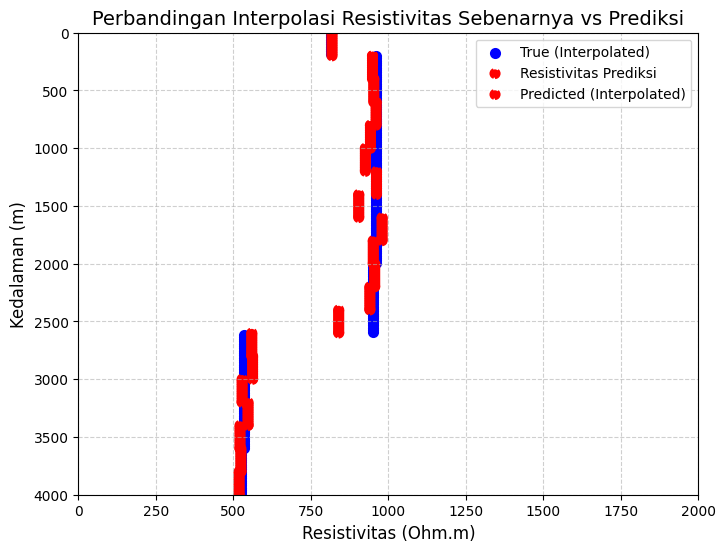

In [ ]:
measure_interpolated_resistivities(resis_true,ketebalan_true,resis_predict,ketebalan_predict,total_depth)

## Grafik

MAPE resistivitas semu: 0.78%
MAPE fasa: 0.11%


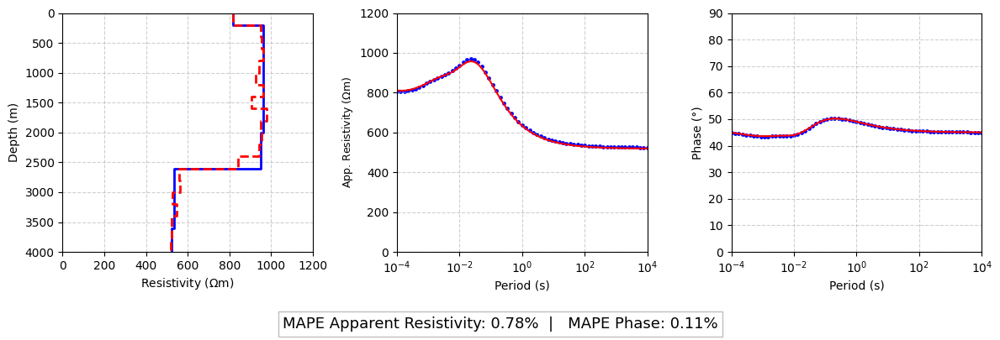

In [ ]:
plot_model_full(resis_true, ketebalan_true,
                    resis_predict, ketebalan_predict,
                    resistivitas_semu, resistivitas_semu_predict,
                    fasa, fasa_predict,
                    frequencies, total_depth)

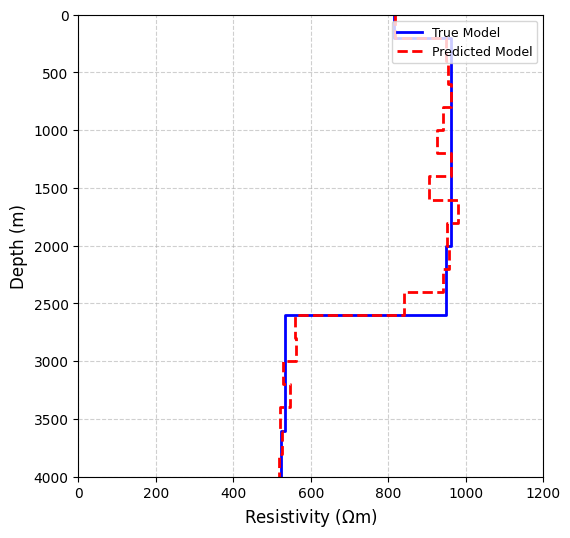

In [ ]:
plot_model_compare_2(resis_true,ketebalan_true,resis_predict,ketebalan_predict,total_depth)

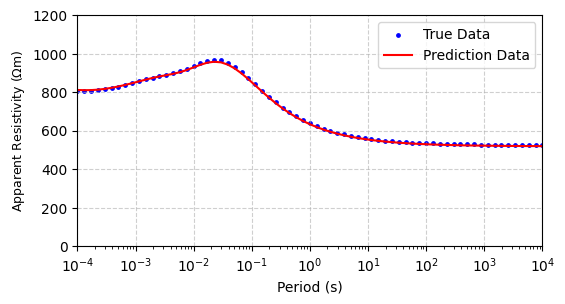

In [ ]:
plot_appres(resistivitas_semu, resistivitas_semu_predict,frequencies)

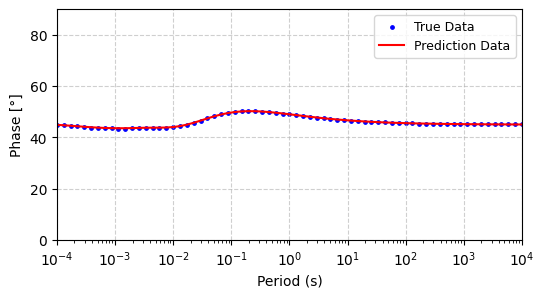

In [ ]:
plot_phase(fasa, fasa_predict,frequencies)

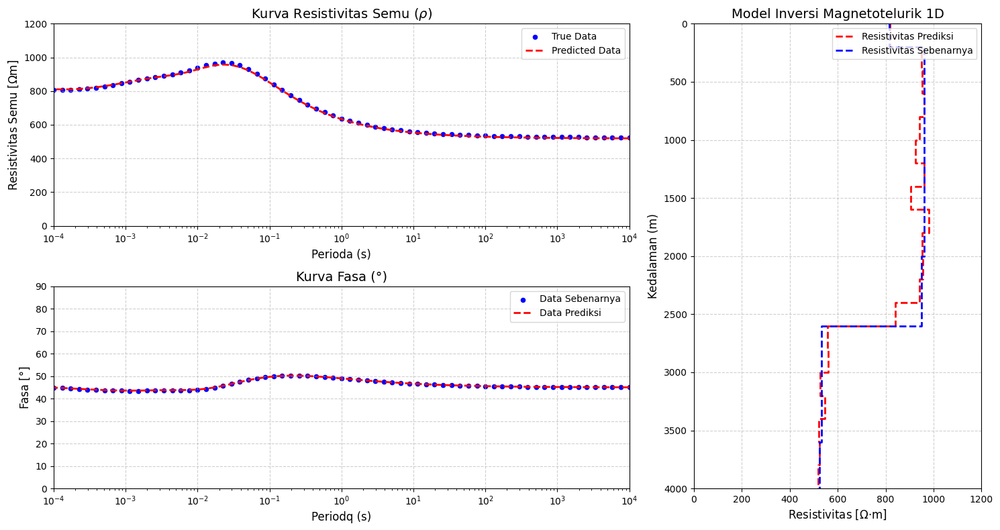

In [ ]:
plot_MT_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, 1/frequencies, fasa, resistivitas_semu, fasa_predict, resistivitas_semu_predict, total_depth)

# Prediksi Bumi Homogen

## Model Bumi Homogen I

### Prediksi

In [ ]:


# Forward modelling untuk data input
resis_true= np.array([100, 100])
ketebalan_true = np.array([2000])
resistivitas_semu, fasa = forward_modelling(resis_true, ketebalan_true, frequencies)

resistivitas_semu = np.array([resistivitas_semu])
fasa = np.array([fasa])

#Reshape sebelum normalisasi
resistivitas_semu = resistivitas_semu[0].reshape(1, X_input_res.shape[1]) # Corrected reshape syntax
fasa = fasa.reshape(1, X_input_phase.shape[1])

resistivitas_semu_log = np.log10(resistivitas_semu)
fasa_log = np.log10(fasa)

# Normalisasi data input
resistivitas_semu_normalized = input_res_scaler.transform(resistivitas_semu_log)
fasa_normalized = input_phase_scaler.transform(fasa_log)

# Reshape jika perlu (misalnya, untuk input CNN)
resistivitas_semu_normalized = resistivitas_semu_normalized.reshape(1, X_input_res.shape[1], 1)
fasa_normalized = fasa_normalized.reshape(1, X_input_phase.shape[1], 1)

# Prediksi
predictions = model.predict([resistivitas_semu_normalized, fasa_normalized])

# Denormalisasi hasil prediksi, apply to the predictions, not hasil
predictions_denormalized = output_model_scaler.inverse_transform(predictions)
predictions_denormalized = np.power(10, predictions_denormalized)

# Accessing the values from predictions_denormalized
resis_predict = predictions_denormalized[0] #
ketebalan_predict = np.full(jumlah_layer-1,layer_thickness)

#Forward Modelling from prediction model
resistivitas_semu_predict, fasa_predict = forward_modelling(resis_predict,ketebalan_predict,frequencies)
resistivitas_semu_predict = np.array([resistivitas_semu_predict])
fasa_predict = np.array([fasa_predict])


#print(hasil) #No need to print hasil as it's not used

print("Nilai Resis_True", resis_true)
print("Nilai ketebalan_True",ketebalan_true)
print("Nilai resis_predict",resis_predict)
print("Nilai ketebalan_predict",ketebalan_predict)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
Nilai Resis_True [100 100]
Nilai ketebalan_True [2000]
Nilai resis_predict [101.53285  102.84658  100.22984  104.15981  101.61939   97.06133
 104.02278  101.10168  106.07122  102.07138   98.738945  97.56168
  99.472786  97.95415  100.01395   98.4465    96.78348   97.32326
  98.95081   95.805405]
Nilai ketebalan_predict [200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200.
 200. 200. 200. 200. 200.]


### Grafik

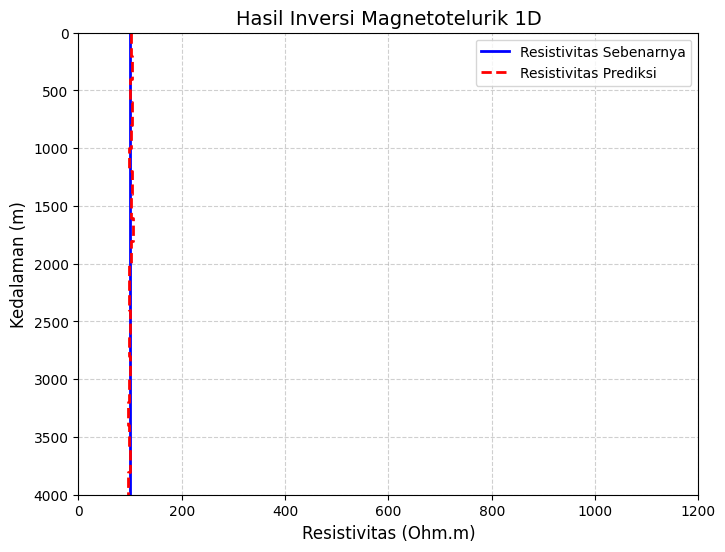

In [ ]:
plot_model_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, total_depth)

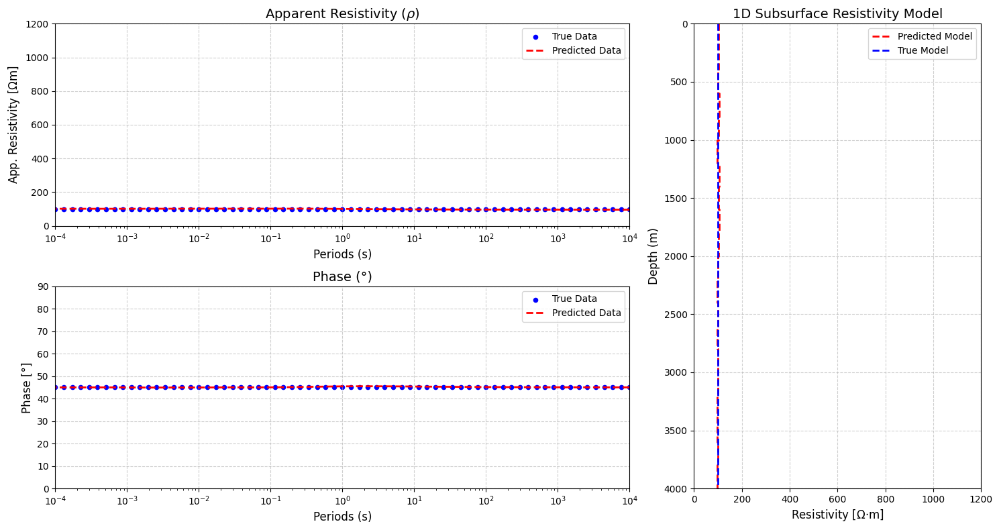

In [ ]:
plot_MT_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, 1/frequencies, fasa, resistivitas_semu, fasa_predict,resistivitas_semu_predict, total_depth)

### Error

In [ ]:
measure_MSE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)


MSE Resistivitas Semu: 6.70
MSE Fasa: 0.05


In [ ]:
measure_MAPE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)


MAPE resistivitas semu: 2.33%
MAPE fasa: 0.34%


In [ ]:
measure_RMSE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

RMSE Resistivitas Semu: 2.59
RMSE Fasa: 0.23


[Interpolated] MSE model resistivitas: 7.4117
[Interpolated] RMSE model resistivitas: 2.7224
[Interpolated] MAPE model resistivitas: 2.28%


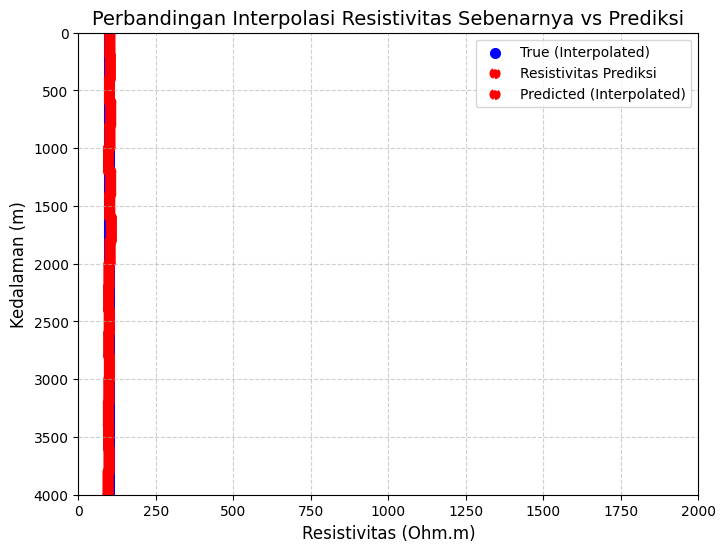

In [ ]:
measure_interpolated_resistivities(resis_true,ketebalan_true,resis_predict,ketebalan_predict,total_depth)

## Model Bumi Homogen II

### Prediksi

In [ ]:
# Forward modelling untuk data input
resis_true= np.array([50, 50])
ketebalan_true = np.array([2000])
resistivitas_semu, fasa = forward_modelling(resis_true, ketebalan_true, frequencies)

resistivitas_semu = np.array([resistivitas_semu])
fasa = np.array([fasa])

#Reshape sebelum normalisasi
resistivitas_semu = resistivitas_semu[0].reshape(1, X_input_res.shape[1]) # Corrected reshape syntax
fasa = fasa.reshape(1, X_input_phase.shape[1])

# Logaritma Dataset
resistivitas_semu_log = np.log10(resistivitas_semu)
fasa_log = np.log10(fasa)

# Normalisasi data input
resistivitas_semu_normalized = input_res_scaler.transform(resistivitas_semu_log)
fasa_normalized = input_phase_scaler.transform(fasa_log)

# Reshape jika perlu (misalnya, untuk input CNN)
resistivitas_semu_normalized = resistivitas_semu_normalized.reshape(1, X_input_res.shape[1], 1)
fasa_normalized = fasa_normalized.reshape(1, X_input_phase.shape[1], 1)

# Prediksi
predictions = model.predict([resistivitas_semu_normalized, fasa_normalized])

# Denormalisasi hasil prediksi, apply to the predictions, not hasil
predictions_denormalized = output_model_scaler.inverse_transform(predictions)
predictions_denormalized = np.power(10, predictions_denormalized)

# Accessing the values from predictions_denormalized
resis_predict = predictions_denormalized[0] #
ketebalan_predict = np.full(jumlah_layer-1,layer_thickness)

#Forward Modelling from prediction model
resistivitas_semu_predict, fasa_predict = forward_modelling(resis_predict,ketebalan_predict,frequencies)
resistivitas_semu_predict = np.array([resistivitas_semu_predict])
fasa_predict = np.array([fasa_predict])


#print(hasil) #No need to print hasil as it's not used

print("Nilai Resis_True", resis_true)
print("Nilai ketebalan_True",ketebalan_true)
print("Nilai resis_predict",resis_predict)
print("Nilai ketebalan_predict",ketebalan_predict)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
Nilai Resis_True [50 50]
Nilai ketebalan_True [2000]
Nilai resis_predict [49.874096 51.9134   48.28141  51.769703 50.1057   49.419376 51.555023
 49.216534 49.65082  48.1486   46.612198 46.05174  47.482956 47.153923
 47.51516  47.136337 47.781265 49.687836 48.844036 47.37069 ]
Nilai ketebalan_predict [200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200.
 200. 200. 200. 200. 200.]


### Grafik

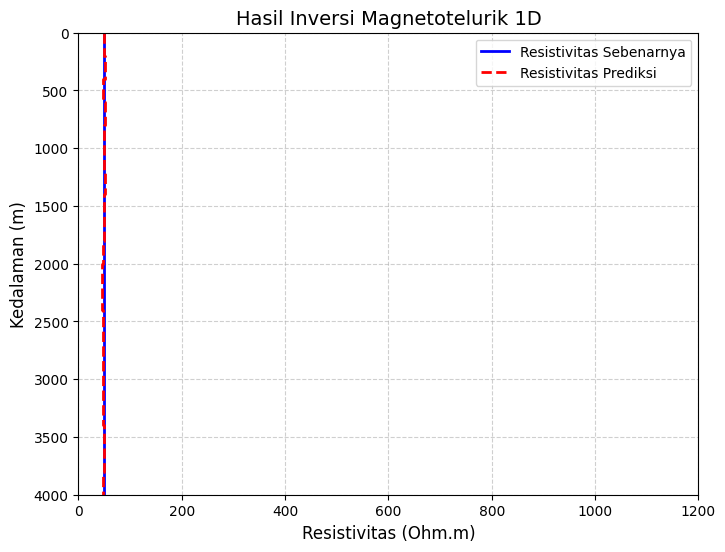

In [ ]:
plot_model_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, total_depth)

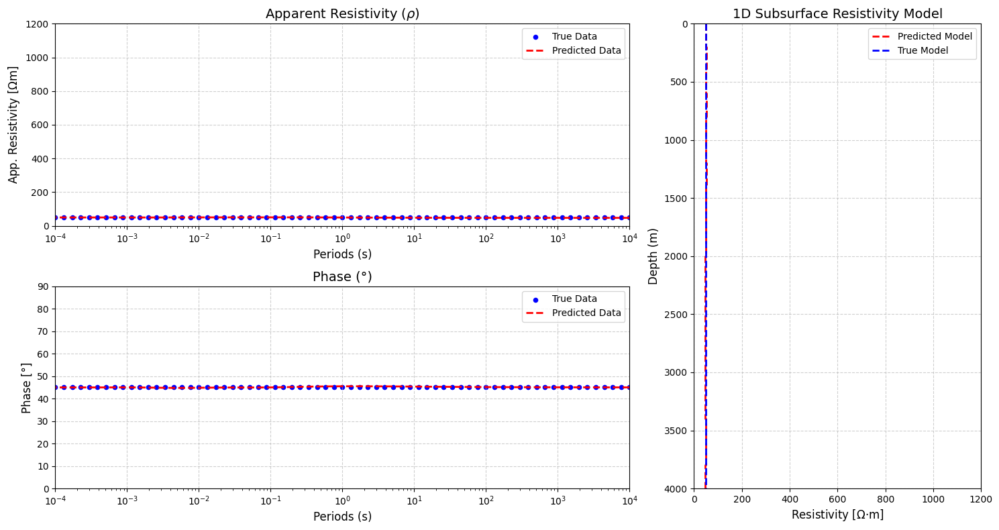

In [ ]:
plot_MT_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, 1/frequencies, fasa, resistivitas_semu, fasa_predict,resistivitas_semu_predict, total_depth)

### Error

In [ ]:
measure_MSE(resistivitas_semu[0], fasa[0], resistivitas_semu_predict[0], fasa_predict[0])

MSE Resistivitas Semu: 2.34
MSE Fasa: 0.06


In [ ]:
measure_MAPE(resistivitas_semu[0], fasa[0], resistivitas_semu_predict[0], fasa_predict[0])

MAPE resistivitas semu: 2.31%
MAPE fasa: 0.37%


In [ ]:
measure_RMSE(resistivitas_semu[0], fasa[0], resistivitas_semu_predict[0], fasa_predict[0])

RMSE Resistivitas Semu: 1.53
RMSE Fasa: 0.24


[Interpolated] MSE model resistivitas: 4.2919
[Interpolated] RMSE model resistivitas: 2.0717
[Interpolated] MAPE model resistivitas: 3.51%


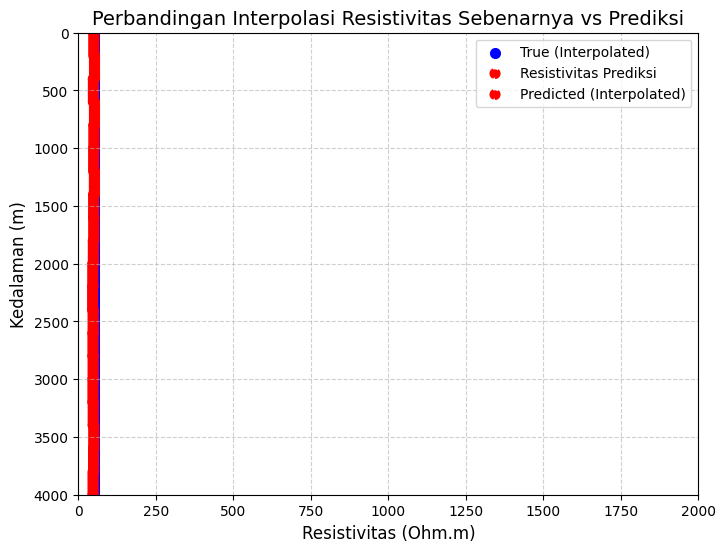

In [ ]:
measure_interpolated_resistivities(resis_true,ketebalan_true,resis_predict,ketebalan_predict,total_depth)

## Model Bumi Homogen III

### Prediksi

In [ ]:


# Forward modelling untuk data input
resis_true= np.array([500, 500])
ketebalan_true = np.array([2000])
resistivitas_semu, fasa = forward_modelling(resis_true, ketebalan_true, frequencies)
period = 1/frequencies

resistivitas_semu = np.array([resistivitas_semu])
fasa = np.array([fasa])

#Reshape sebelum normalisasi
resistivitas_semu = resistivitas_semu[0].reshape(1, X_input_res.shape[1]) # Corrected reshape syntax
fasa = fasa.reshape(1, X_input_phase.shape[1])

# Logaritma Dataset
resistivitas_semu_log = np.log10(resistivitas_semu)
fasa_log = np.log10(fasa)

# Normalisasi data input
resistivitas_semu_normalized = input_res_scaler.transform(resistivitas_semu_log)
fasa_normalized = input_phase_scaler.transform(fasa_log)

# Reshape jika perlu (misalnya, untuk input CNN)
resistivitas_semu_normalized = resistivitas_semu_normalized.reshape(1, X_input_res.shape[1], 1)
fasa_normalized = fasa_normalized.reshape(1, X_input_phase.shape[1], 1)

# Prediksi
predictions = model.predict([resistivitas_semu_normalized, fasa_normalized])

# Denormalisasi hasil prediksi, apply to the predictions, not hasil
predictions_denormalized = output_model_scaler.inverse_transform(predictions)
predictions_denormalized = np.power(10, predictions_denormalized)

# Accessing the values from predictions_denormalized
resis_predict = predictions_denormalized[0] #
ketebalan_predict = np.full(jumlah_layer-1,layer_thickness)

#Forward Modelling from prediction model
resistivitas_semu_predict, fasa_predict = forward_modelling(resis_predict,ketebalan_predict,frequencies)
resistivitas_semu_predict = np.array([resistivitas_semu_predict])
fasa_predict = np.array([fasa_predict])


#print(hasil) #No need to print hasil as it's not used

print("Nilai Resis_True", resis_true)
print("Nilai ketebalan_True",ketebalan_true)
print("Nilai resis_predict",resis_predict)
print("Nilai ketebalan_predict",ketebalan_predict)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
Nilai Resis_True [500 500]
Nilai ketebalan_True [2000]
Nilai resis_predict [499.3645  505.70694 500.71893 491.2594  512.5158  489.82407 502.4926
 500.3318  514.8366  503.73798 491.69406 486.92902 518.5593  502.97144
 502.8246  501.3378  504.10205 501.258   504.87003 488.12433]
Nilai ketebalan_predict [200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200.
 200. 200. 200. 200. 200.]


### Grafik

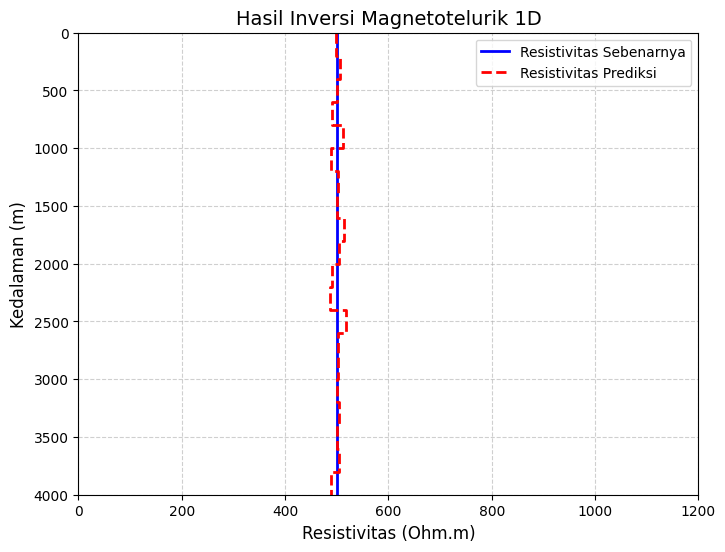

In [ ]:

plot_model_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, total_depth)

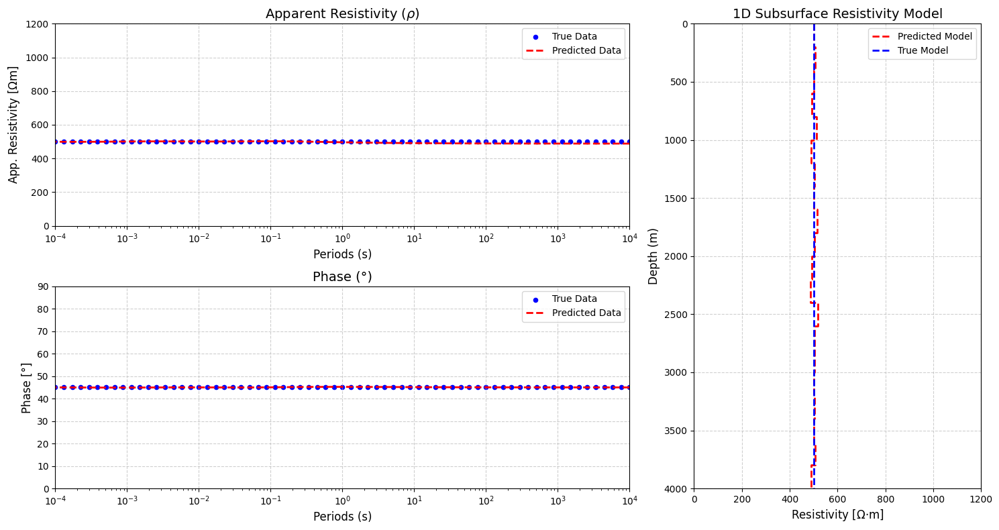

In [ ]:
plot_MT_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict,1/frequencies, fasa, resistivitas_semu, fasa_predict,resistivitas_semu_predict, total_depth)

### Error

In [ ]:
measure_MSE(resistivitas_semu[0], fasa[0], resistivitas_semu_predict[0], fasa_predict[0])

MSE Resistivitas Semu: 53.36
MSE Fasa: 0.01


In [ ]:
measure_MAPE(resistivitas_semu[0], fasa[0], resistivitas_semu_predict[0], fasa_predict[0])


MAPE resistivitas semu: 1.12%
MAPE fasa: 0.16%


In [ ]:
measure_RMSE(resistivitas_semu[0], fasa[0], resistivitas_semu_predict[0], fasa_predict[0])

RMSE Resistivitas Semu: 7.30
RMSE Fasa: 0.10


[Interpolated] MSE model resistivitas: 69.8274
[Interpolated] RMSE model resistivitas: 8.3563
[Interpolated] MAPE model resistivitas: 1.29%


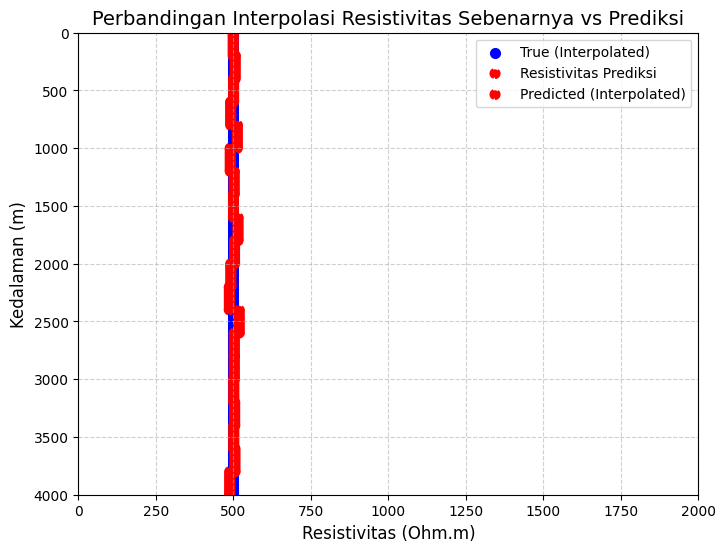

In [ ]:
measure_interpolated_resistivities(resis_true,ketebalan_true,resis_predict,ketebalan_predict,total_depth)

# Prediksi Bumi 2 Lapis

## Model Bumi 2 Lapis I

### Prediksi

In [ ]:


# Forward modelling untuk data input
resis_true= np.array([50, 200])
ketebalan_true = np.array([1000])
period = 1/frequencies
resistivitas_semu, fasa = forward_modelling(resis_true, ketebalan_true, frequencies)

resistivitas_semu = np.array([resistivitas_semu])
fasa = np.array([fasa])

#Reshape sebelum normalisasi
resistivitas_semu = resistivitas_semu[0].reshape(1, X_input_res.shape[1]) # Corrected reshape syntax
fasa = fasa.reshape(1, X_input_phase.shape[1])

# Logaritma Data Input
resistivitas_semu_log = np.log10(resistivitas_semu)
fasa_log = np.log10(fasa)

# Normalisasi data input
resistivitas_semu_normalized = input_res_scaler.transform(resistivitas_semu_log)
fasa_normalized = input_phase_scaler.transform(fasa_log)

# Reshape jika perlu (misalnya, untuk input CNN)
resistivitas_semu_normalized = resistivitas_semu_normalized.reshape(1, X_input_res.shape[1], 1)
fasa_normalized = fasa_normalized.reshape(1, X_input_phase.shape[1], 1)

# Prediksi
predictions = model.predict([resistivitas_semu_normalized, fasa_normalized])

# Denormalisasi hasil prediksi, apply to the predictions, not hasil
predictions_denormalized = output_model_scaler.inverse_transform(predictions)
predictions_denormalized = np.power(10, predictions_denormalized)

# Accessing the values from predictions_denormalized
resis_predict = predictions_denormalized[0] #
ketebalan_predict = np.full(jumlah_layer-1,layer_thickness)

#Forward Modelling from prediction model
resistivitas_semu_predict, fasa_predict = forward_modelling(resis_predict,ketebalan_predict,frequencies)
resistivitas_semu_predict = np.array([resistivitas_semu_predict])
fasa_predict = np.array([fasa_predict])


#print(hasil) #No need to print hasil as it's not used

print("Nilai Resis_True", resis_true)
print("Nilai ketebalan_True",ketebalan_true)
print("Nilai resis_predict",resis_predict)
print("Nilai ketebalan_predict",ketebalan_predict)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
Nilai Resis_True [ 50 200]
Nilai ketebalan_True [1000]
Nilai resis_predict [ 49.453354  50.343887  51.80015   55.13932   49.096096 299.5383
 166.93634  160.84216  215.0883   215.38336  229.30879  239.73512
 231.95827  194.03537  183.44724  184.34554  188.71097  185.42894
 188.05952  185.02545 ]
Nilai ketebalan_predict [200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200.
 200. 200. 200. 200. 200.]


### Grafik

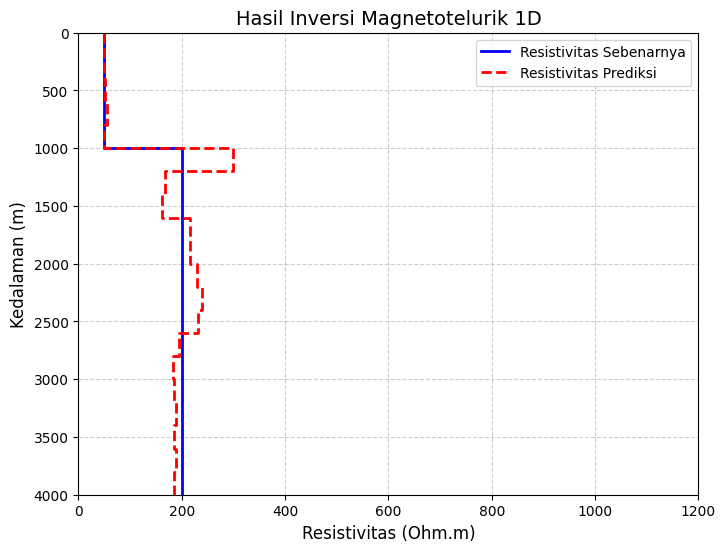

In [ ]:
plot_model_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, total_depth)

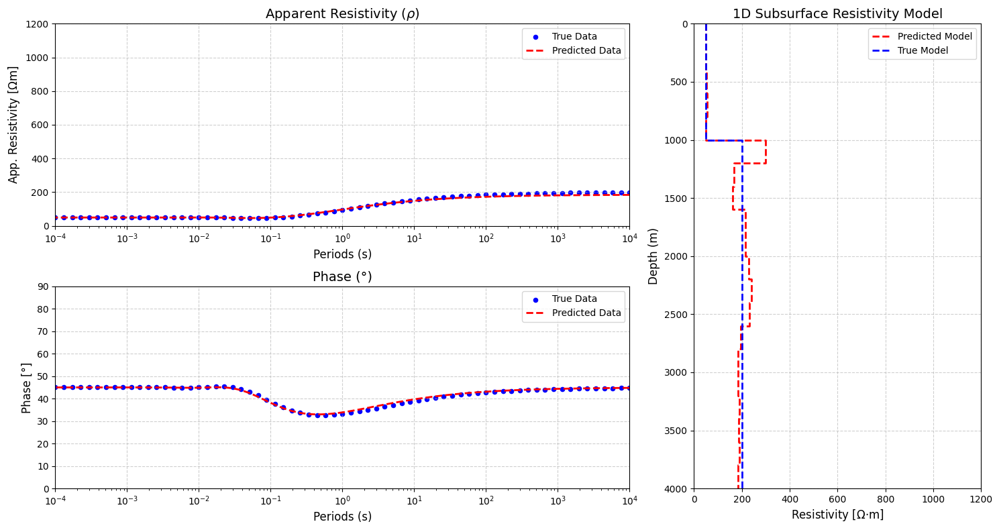

In [ ]:
plot_MT_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, period, fasa, resistivitas_semu, fasa_predict,resistivitas_semu_predict, total_depth)

### Error

In [ ]:
measure_MSE(resistivitas_semu[0], fasa[0], resistivitas_semu_predict[0], fasa_predict[0])

MSE Resistivitas Semu: 58.06
MSE Fasa: 0.20


In [ ]:
measure_MAPE(resistivitas_semu[0], fasa[0], resistivitas_semu_predict[0], fasa_predict[0])

MAPE resistivitas semu: 3.38%
MAPE fasa: 0.85%


In [ ]:
measure_RMSE(resistivitas_semu[0], fasa[0], resistivitas_semu_predict[0], fasa_predict[0])

RMSE Resistivitas Semu: 7.62
RMSE Fasa: 0.45


[Interpolated] MSE model resistivitas: 887.4994
[Interpolated] RMSE model resistivitas: 29.7909
[Interpolated] MAPE model resistivitas: 10.73%


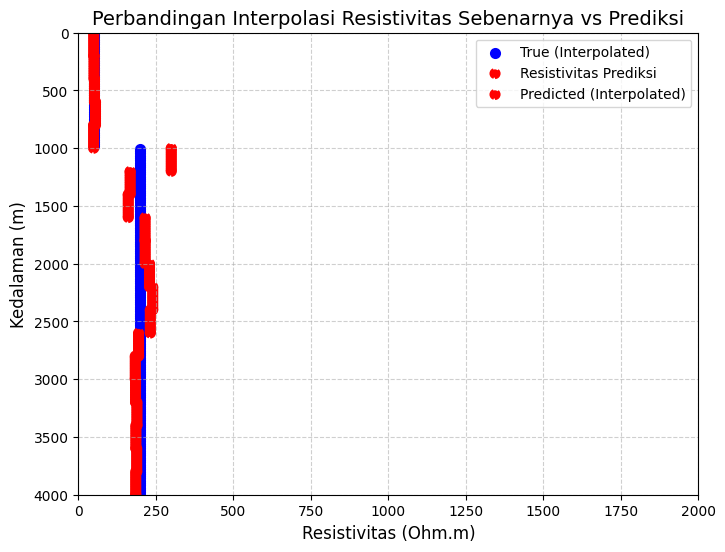

In [ ]:
measure_interpolated_resistivities(resis_true,ketebalan_true,resis_predict,ketebalan_predict,total_depth)

## Model Bumi 2 Lapis II

### Prediksi

In [ ]:


# Forward modelling untuk data input
resis_true= np.array([200, 50])
ketebalan_true = np.array([1000])
period = 1/frequencies
resistivitas_semu, fasa = forward_modelling(resis_true, ketebalan_true, frequencies)

resistivitas_semu = np.array([resistivitas_semu])
fasa = np.array([fasa])

#Reshape sebelum normalisasi
resistivitas_semu = resistivitas_semu[0].reshape(1, X_input_res.shape[1]) # Corrected reshape syntax
fasa = fasa.reshape(1, X_input_phase.shape[1])

# Logaritma Data Input
resistivitas_semu_log = np.log10(resistivitas_semu)
fasa_log = np.log10(fasa)

# Normalisasi data input
resistivitas_semu_normalized = input_res_scaler.transform(resistivitas_semu_log)
fasa_normalized = input_phase_scaler.transform(fasa_log)

# Reshape jika perlu (misalnya, untuk input CNN)
resistivitas_semu_normalized = resistivitas_semu_normalized.reshape(1, X_input_res.shape[1], 1)
fasa_normalized = fasa_normalized.reshape(1, X_input_phase.shape[1], 1)

# Prediksi
predictions = model.predict([resistivitas_semu_normalized, fasa_normalized])

# Denormalisasi hasil prediksi, apply to the predictions, not hasil
predictions_denormalized = output_model_scaler.inverse_transform(predictions)
predictions_denormalized = np.power(10, predictions_denormalized)

# Accessing the values from predictions_denormalized
resis_predict = predictions_denormalized[0] #
ketebalan_predict = np.full(jumlah_layer-1,layer_thickness)

#Forward Modelling from prediction model
resistivitas_semu_predict, fasa_predict = forward_modelling(resis_predict,ketebalan_predict,frequencies)
resistivitas_semu_predict = np.array([resistivitas_semu_predict])
fasa_predict = np.array([fasa_predict])


#print(hasil) #No need to print hasil as it's not used

print("Nilai Resis_True", resis_true)
print("Nilai ketebalan_True",ketebalan_true)
print("Nilai resis_predict",resis_predict)
print("Nilai ketebalan_predict",ketebalan_predict)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step
Nilai Resis_True [200  50]
Nilai ketebalan_True [1000]
Nilai resis_predict [201.99928  210.85188  204.87125  190.95561  208.0766    53.239807
  51.881046  49.620533  53.007675  49.385258  52.00566   48.122166
  48.165695  50.265926  51.10091   50.514534  49.555756  50.77418
  50.63292   45.935375]
Nilai ketebalan_predict [200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200.
 200. 200. 200. 200. 200.]


### Error

In [ ]:
measure_MSE(resistivitas_semu[0], fasa[0], resistivitas_semu_predict[0], fasa_predict[0])

MSE Resistivitas Semu: 9.72
MSE Fasa: 0.16


In [ ]:
measure_MAPE(resistivitas_semu[0], fasa[0], resistivitas_semu_predict[0], fasa_predict[0])

MAPE resistivitas semu: 3.56%
MAPE fasa: 0.58%


(np.float64(3.556032758382468), np.float64(0.5802613747208151))

In [ ]:
measure_RMSE(resistivitas_semu[0], fasa[0], resistivitas_semu_predict[0], fasa_predict[0])

RMSE Resistivitas Semu: 3.12
RMSE Fasa: 0.40


[Interpolated] MSE model resistivitas: 17.3152
[Interpolated] RMSE model resistivitas: 4.1612
[Interpolated] MAPE model resistivitas: 3.13%


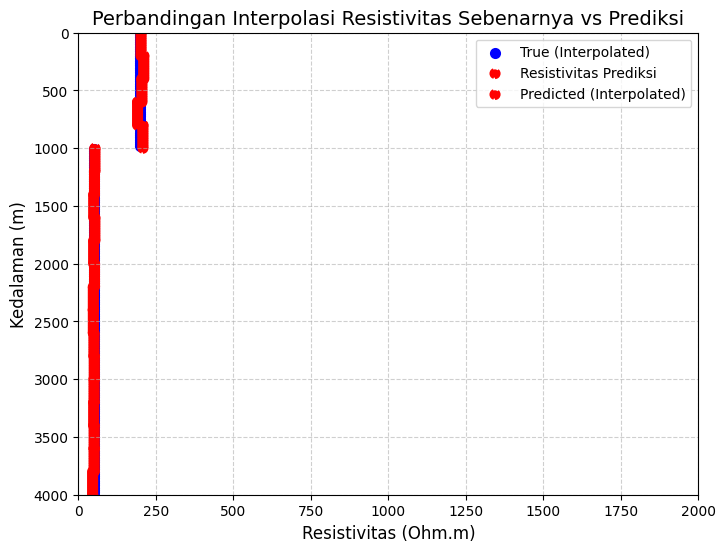

In [ ]:
measure_interpolated_resistivities(resis_true,ketebalan_true,resis_predict,ketebalan_predict,total_depth)

### Grafik

MAPE resistivitas semu: 3.56%
MAPE fasa: 0.58%


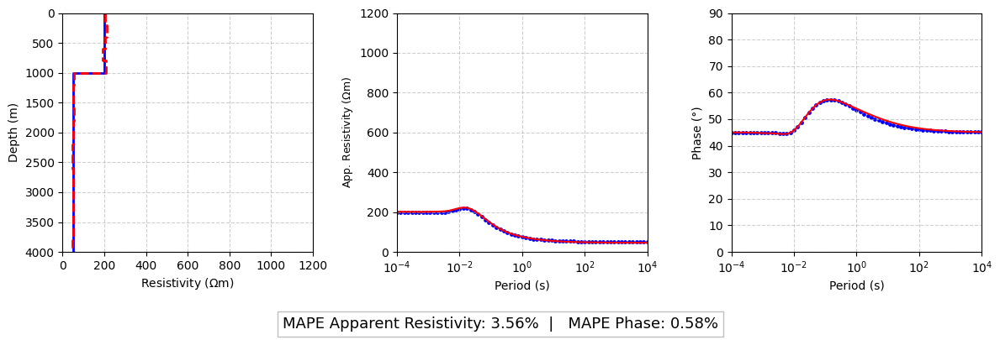

In [ ]:
plot_model_full(resis_true, ketebalan_true,
                    resis_predict, ketebalan_predict,
                    resistivitas_semu, resistivitas_semu_predict,
                    fasa, fasa_predict,
                    frequencies, total_depth)

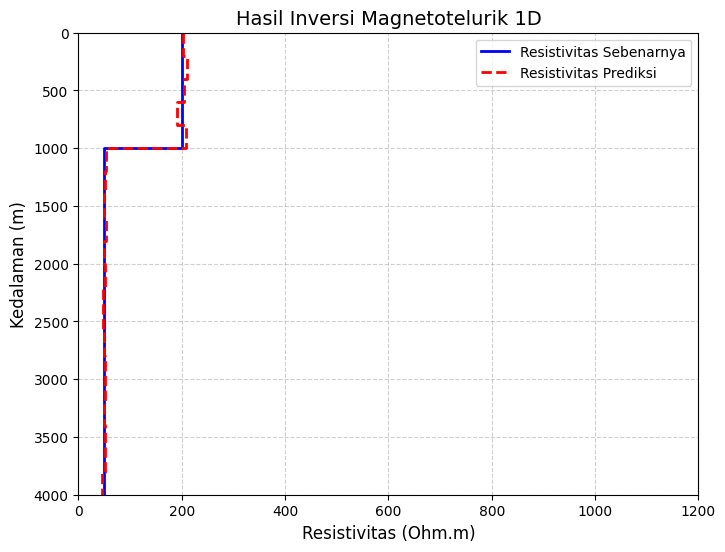

In [ ]:
plot_model_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, total_depth)

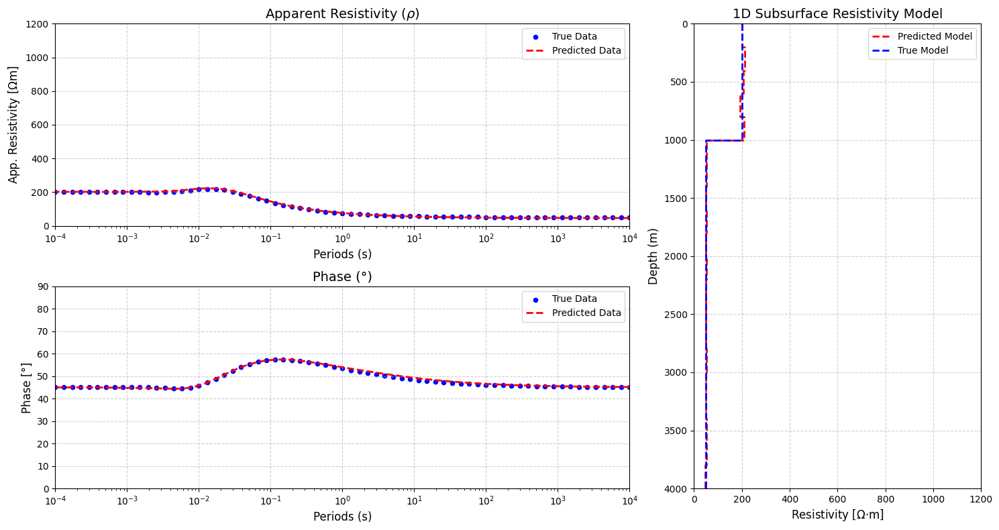

In [ ]:
plot_MT_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, period, fasa, resistivitas_semu, fasa_predict,resistivitas_semu_predict, total_depth)

## Model Bumi 2 Lapis III

### Prediksi

In [ ]:


# Forward modelling untuk data input
resis_true= np.array([50,800])
ketebalan_true = np.array([1000])
period = 1/frequencies
resistivitas_semu, fasa = forward_modelling(resis_true, ketebalan_true, frequencies)

resistivitas_semu = np.array([resistivitas_semu])
fasa = np.array([fasa])

#Reshape sebelum normalisasi
resistivitas_semu = resistivitas_semu[0].reshape(1, X_input_res.shape[1]) # Corrected reshape syntax
fasa = fasa.reshape(1, X_input_phase.shape[1])

# Logaritma Data Input
resistivitas_semu_log = np.log10(resistivitas_semu)
fasa_log = np.log10(fasa)

# Normalisasi data input
resistivitas_semu_normalized = input_res_scaler.transform(resistivitas_semu_log)
fasa_normalized = input_phase_scaler.transform(fasa_log)

# Reshape jika perlu (misalnya, untuk input CNN)
resistivitas_semu_normalized = resistivitas_semu_normalized.reshape(1, X_input_res.shape[1], 1)
fasa_normalized = fasa_normalized.reshape(1, X_input_phase.shape[1], 1)

# Prediksi
predictions = model.predict([resistivitas_semu_normalized, fasa_normalized])

# Denormalisasi hasil prediksi, apply to the predictions, not hasil
predictions_denormalized = output_model_scaler.inverse_transform(predictions)
predictions_denormalized = np.power(10, predictions_denormalized)

# Accessing the values from predictions_denormalized
resis_predict = predictions_denormalized[0] #
ketebalan_predict = np.full(jumlah_layer-1,layer_thickness)

#Forward Modelling from prediction model
resistivitas_semu_predict, fasa_predict = forward_modelling(resis_predict,ketebalan_predict,frequencies)
resistivitas_semu_predict = np.array([resistivitas_semu_predict])
fasa_predict = np.array([fasa_predict])


#print(hasil) #No need to print hasil as it's not used

print("Nilai Resis_True", resis_true)
print("Nilai ketebalan_True",ketebalan_true)
print("Nilai resis_predict",resis_predict)
print("Nilai ketebalan_predict",ketebalan_predict)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
Nilai Resis_True [ 50 800]
Nilai ketebalan_True [1000]
Nilai resis_predict [ 47.090893  46.03627   48.983025  50.96728   50.337543 794.9396
 850.91156  820.75165  797.54175  801.2967   778.7797   808.8596
 828.7188   782.485    772.2595   768.9568   752.97656  726.9644
 721.97107  789.1492  ]
Nilai ketebalan_predict [200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200.
 200. 200. 200. 200. 200.]


### Grafik

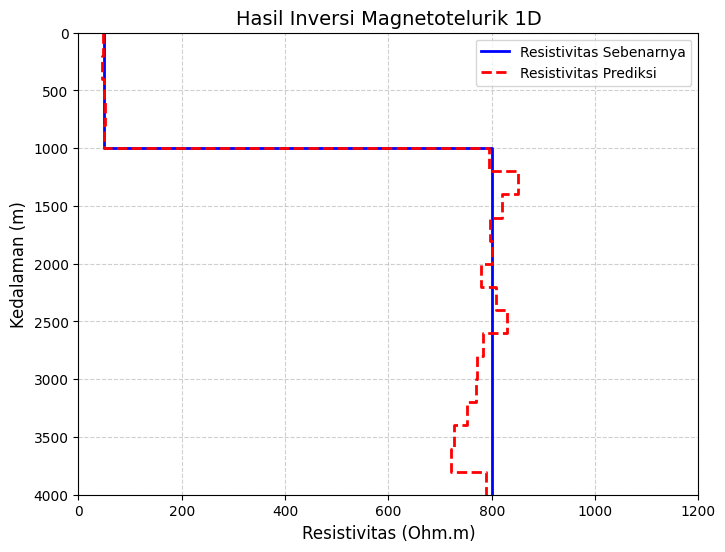

In [ ]:
plot_model_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, total_depth)

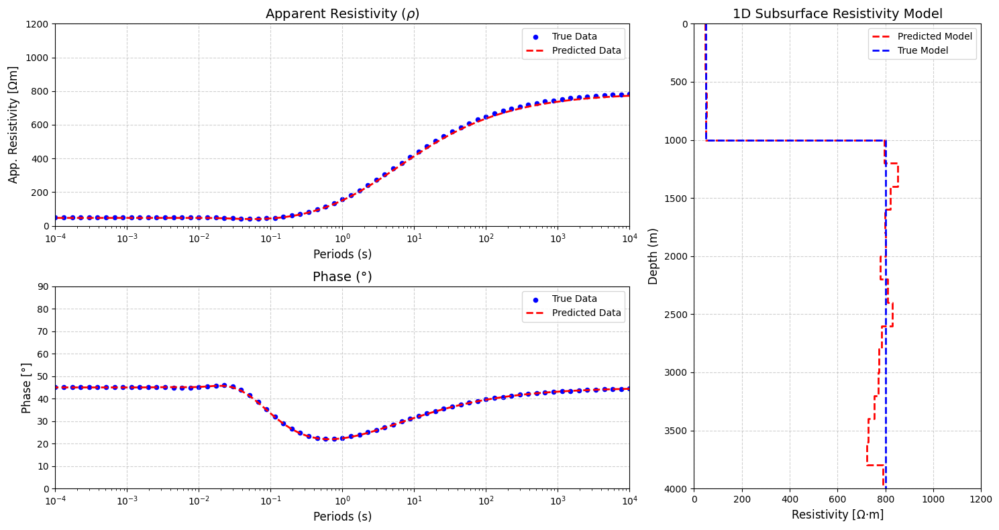

In [ ]:
plot_MT_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, period, fasa, resistivitas_semu, fasa_predict,resistivitas_semu_predict, total_depth)

### Error

In [ ]:
measure_MSE(resistivitas_semu[0], fasa[0], resistivitas_semu_predict[0], fasa_predict[0])

MSE Resistivitas Semu: 66.33
MSE Fasa: 0.03


In [ ]:
measure_MAPE(resistivitas_semu[0], fasa[0], resistivitas_semu_predict[0], fasa_predict[0])

MAPE resistivitas semu: 3.85%
MAPE fasa: 0.40%


In [ ]:
measure_RMSE(resistivitas_semu[0], fasa[0], resistivitas_semu_predict[0], fasa_predict[0])

RMSE Resistivitas Semu: 8.14
RMSE Fasa: 0.16


[Interpolated] MSE model resistivitas: 1011.3708
[Interpolated] RMSE model resistivitas: 31.8021
[Interpolated] MAPE model resistivitas: 3.57%


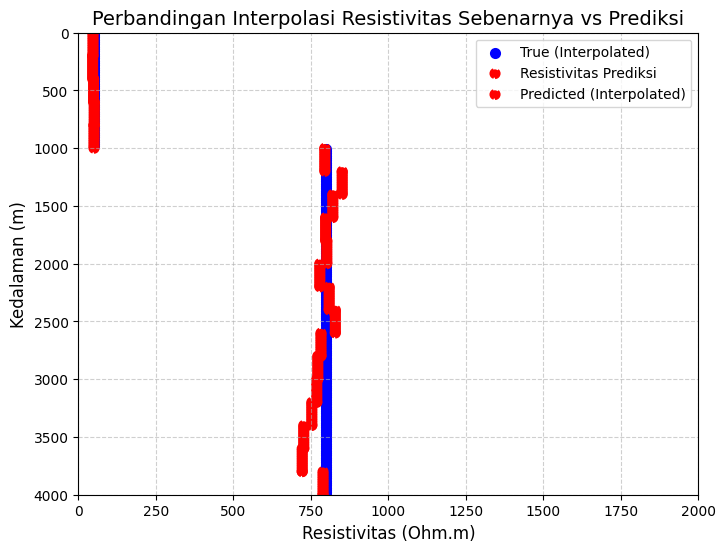

In [ ]:
measure_interpolated_resistivities(resis_true,ketebalan_true,resis_predict,ketebalan_predict,total_depth)

## Model Bumi 2 Lapis IV

### Prediksi

In [ ]:


# Forward modelling untuk data input
resis_true= np.array([800, 50])
ketebalan_true = np.array([1000])
period = 1/frequencies
resistivitas_semu, fasa = forward_modelling(resis_true, ketebalan_true, frequencies)

resistivitas_semu = np.array([resistivitas_semu])
fasa = np.array([fasa])

#Reshape sebelum normalisasi
resistivitas_semu = resistivitas_semu[0].reshape(1, X_input_res.shape[1]) # Corrected reshape syntax
fasa = fasa.reshape(1, X_input_phase.shape[1])

# Logaritma Data Input
resistivitas_semu_log = np.log10(resistivitas_semu)
fasa_log = np.log10(fasa)

# Normalisasi data input
resistivitas_semu_normalized = input_res_scaler.transform(resistivitas_semu_log)
fasa_normalized = input_phase_scaler.transform(fasa_log)

# Reshape jika perlu (misalnya, untuk input CNN)
resistivitas_semu_normalized = resistivitas_semu_normalized.reshape(1, X_input_res.shape[1], 1)
fasa_normalized = fasa_normalized.reshape(1, X_input_phase.shape[1], 1)

# Prediksi
predictions = model.predict([resistivitas_semu_normalized, fasa_normalized])

# Denormalisasi hasil prediksi, apply to the predictions, not hasil
predictions_denormalized = output_model_scaler.inverse_transform(predictions)
predictions_denormalized = np.power(10, predictions_denormalized)

# Accessing the values from predictions_denormalized
resis_predict = predictions_denormalized[0] #
ketebalan_predict = np.full(jumlah_layer-1,layer_thickness)

#Forward Modelling from prediction model
resistivitas_semu_predict, fasa_predict = forward_modelling(resis_predict,ketebalan_predict,frequencies)
resistivitas_semu_predict = np.array([resistivitas_semu_predict])
fasa_predict = np.array([fasa_predict])


#print(hasil) #No need to print hasil as it's not used

print("Nilai Resis_True", resis_true)
print("Nilai ketebalan_True",ketebalan_true)
print("Nilai resis_predict",resis_predict)
print("Nilai ketebalan_predict",ketebalan_predict)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
Nilai Resis_True [800  50]
Nilai ketebalan_True [1000]
Nilai resis_predict [819.91125  786.0227   767.5852   795.2552   777.54004   46.117455
  48.965576  48.425392  51.206947  49.946198  48.567482  48.03293
  50.538403  50.753433  51.532894  48.12886   48.669384  49.33476
  50.214653  47.625717]
Nilai ketebalan_predict [200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200.
 200. 200. 200. 200. 200.]


###Grafik

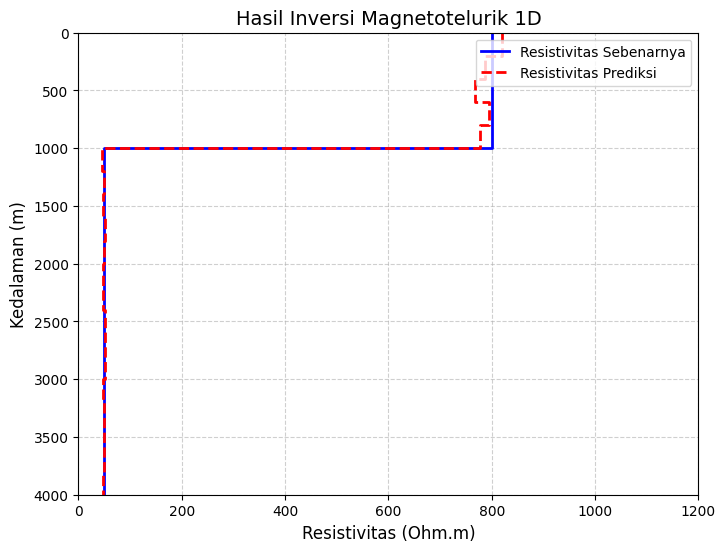

In [ ]:
plot_model_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, total_depth)

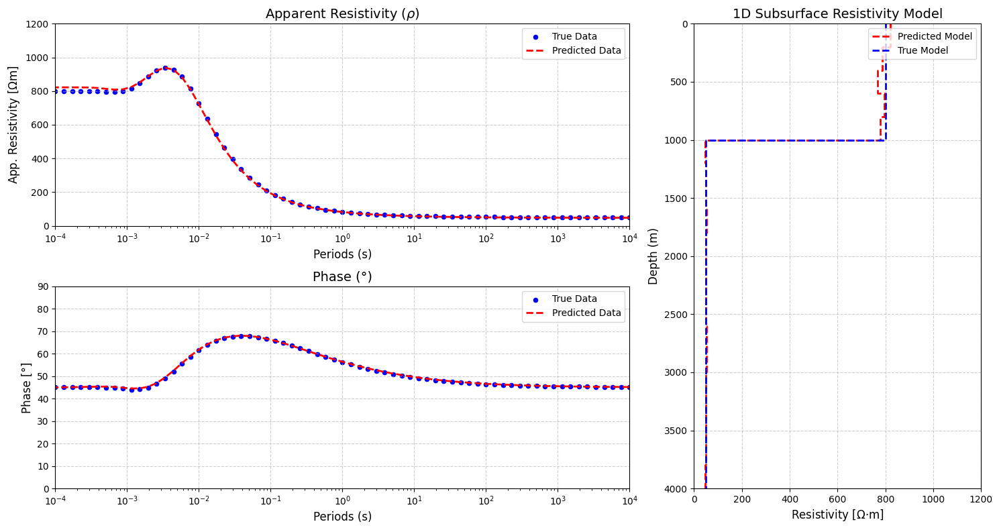

In [ ]:
plot_MT_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, period, fasa, resistivitas_semu, fasa_predict,resistivitas_semu_predict, total_depth)

### Error

In [ ]:
measure_MSE(resistivitas_semu[0], fasa[0], resistivitas_semu_predict[0], fasa_predict[0])


MSE Resistivitas Semu: 58.61
MSE Fasa: 0.05


In [ ]:
measure_MAPE(resistivitas_semu[0], fasa[0], resistivitas_semu_predict[0], fasa_predict[0])


MAPE resistivitas semu: 2.60%
MAPE fasa: 0.37%


In [ ]:
measure_RMSE(resistivitas_semu[0], fasa[0], resistivitas_semu_predict[0], fasa_predict[0])

RMSE Resistivitas Semu: 7.66
RMSE Fasa: 0.23


[Interpolated] MSE model resistivitas: 110.5057
[Interpolated] RMSE model resistivitas: 10.5122
[Interpolated] MAPE model resistivitas: 2.63%


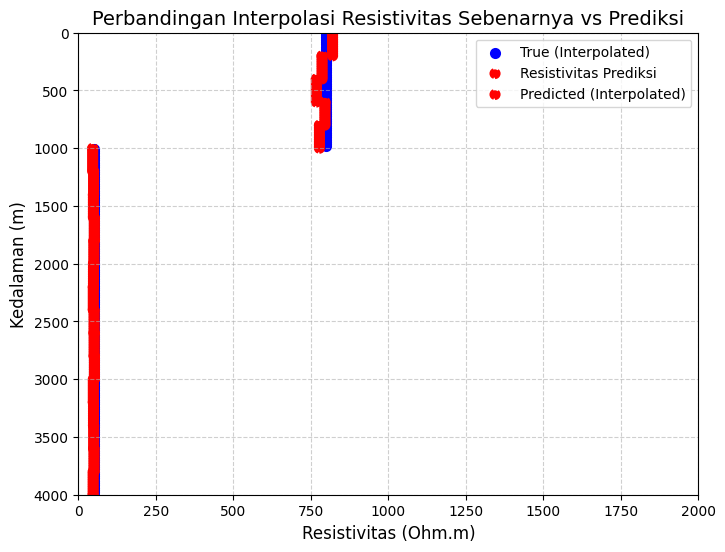

In [ ]:
measure_interpolated_resistivities(resis_true,ketebalan_true,resis_predict,ketebalan_predict,total_depth)

## Model Bumi 2 Lapis V

### Prediksi

In [ ]:


# Forward modelling untuk data input
resis_true= np.array([200, 800])
ketebalan_true = np.array([1000])
period = 1/frequencies
resistivitas_semu, fasa = forward_modelling(resis_true, ketebalan_true, frequencies)

resistivitas_semu = np.array([resistivitas_semu])
fasa = np.array([fasa])

#Reshape sebelum normalisasi
resistivitas_semu = resistivitas_semu[0].reshape(1, X_input_res.shape[1]) # Corrected reshape syntax
fasa = fasa.reshape(1, X_input_phase.shape[1])

# Logaritma Data Input
resistivitas_semu_log = np.log10(resistivitas_semu)
fasa_log = np.log10(fasa)

# Normalisasi data input
resistivitas_semu_normalized = input_res_scaler.transform(resistivitas_semu_log)
fasa_normalized = input_phase_scaler.transform(fasa_log)

# Reshape jika perlu (misalnya, untuk input CNN)
resistivitas_semu_normalized = resistivitas_semu_normalized.reshape(1, X_input_res.shape[1], 1)
fasa_normalized = fasa_normalized.reshape(1, X_input_phase.shape[1], 1)

# Prediksi
predictions = model.predict([resistivitas_semu_normalized, fasa_normalized])

# Denormalisasi hasil prediksi, apply to the predictions, not hasil
predictions_denormalized = output_model_scaler.inverse_transform(predictions)
predictions_denormalized = np.power(10, predictions_denormalized)

# Accessing the values from predictions_denormalized
resis_predict = predictions_denormalized[0] #
ketebalan_predict = np.full(jumlah_layer-1,layer_thickness)

#Forward Modelling from prediction model
resistivitas_semu_predict, fasa_predict = forward_modelling(resis_predict,ketebalan_predict,frequencies)
resistivitas_semu_predict = np.array([resistivitas_semu_predict])
fasa_predict = np.array([fasa_predict])


#print(hasil) #No need to print hasil as it's not used

print("Nilai Resis_True", resis_true)
print("Nilai ketebalan_True",ketebalan_true)
print("Nilai resis_predict",resis_predict)
print("Nilai ketebalan_predict",ketebalan_predict)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
Nilai Resis_True [200 800]
Nilai ketebalan_True [1000]
Nilai resis_predict [197.77208 203.59196 199.92126 190.58319 203.0301  813.10693 824.6724
 776.0368  793.8768  781.6791  773.07477 771.2016  812.7312  804.767
 818.1838  824.404   830.8247  814.67163 799.31213 784.361  ]
Nilai ketebalan_predict [200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200.
 200. 200. 200. 200. 200.]


### Grafik

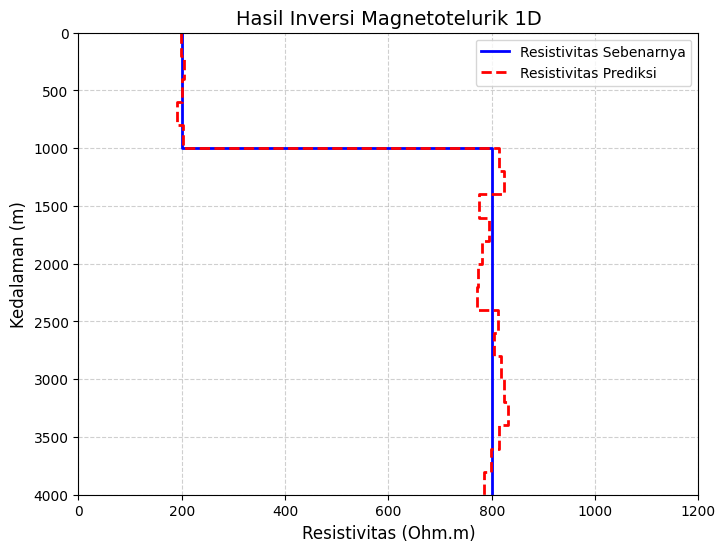

In [ ]:
plot_model_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, total_depth)


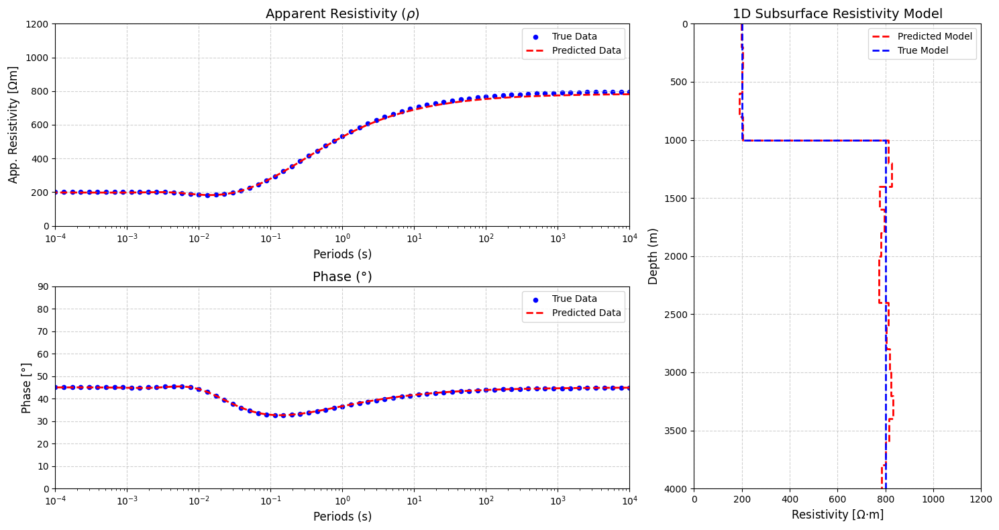

In [ ]:
plot_MT_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, period, fasa, resistivitas_semu, fasa_predict,resistivitas_semu_predict, total_depth)

In [ ]:
  # Buat plot
  plt.figure(figsize=(8, 6))

  # Plot Resistivitas Sebenarnya (True)
  plt.plot(resis_true_plot, depth_true_plot, label='Resistivitas Sebenarnya', color='blue', linewidth=2)

  # Plot Resistivitas Prediksi (Pred)
  plt.plot(resis_pred_plot, depth_pred_plot, label='Resistivitas Prediksi', color='red', linestyle='--', linewidth=2)

  # Pengaturan sumbu dan grafik
  plt.xlabel('Resistivitas (Ohm.m)', fontsize=12)
  plt.ylabel('Kedalaman (m)', fontsize=12)
  plt.title('Hasil Inversi Magnetotelurik 1D', fontsize=14)
  plt.legend(loc='upper right')
  plt.grid(True, linestyle='--', alpha=0.6)

  # Sesuaikan rentang sumbu
  plt.xlim(0, 1200)  # Rentang resistivitas dari 0 hingga 1200 Ohm.m
  plt.ylim(4000, 0)  # Rentang kedalaman dari 0 hingga 1000 m (dibalik agar makin dalam ke bawah)

  plt.show()

### Error

In [ ]:
measure_MSE(resistivitas_semu[0], fasa[0], resistivitas_semu_predict[0], fasa_predict[0])


MSE Resistivitas Semu: 88.21
MSE Fasa: 0.01


In [ ]:
measure_RMSE(resistivitas_semu[0], fasa[0], resistivitas_semu_predict[0], fasa_predict[0])

RMSE Resistivitas Semu: 9.39
RMSE Fasa: 0.08


In [ ]:
measure_MAPE(resistivitas_semu[0], fasa[0], resistivitas_semu_predict[0], fasa_predict[0])

MAPE resistivitas semu: 1.20%
MAPE fasa: 0.15%


[Interpolated] MSE model resistivitas: 295.9717
[Interpolated] RMSE model resistivitas: 17.2038
[Interpolated] MAPE model resistivitas: 2.11%


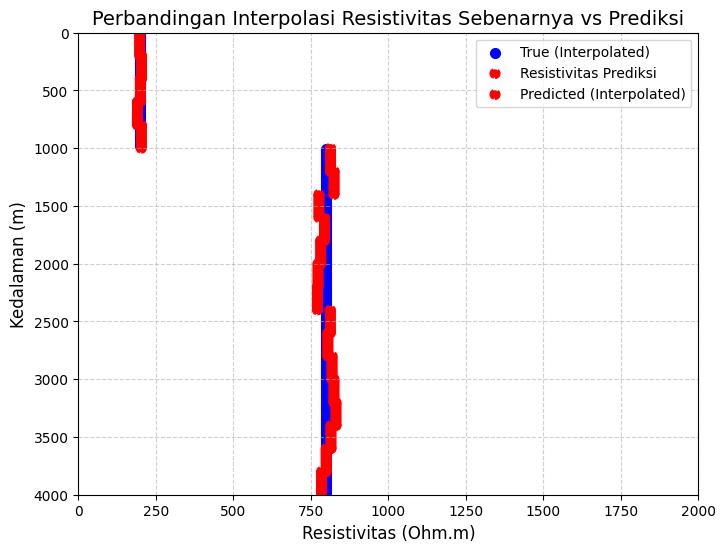

In [ ]:
measure_interpolated_resistivities(resis_true,ketebalan_true,resis_predict,ketebalan_predict,total_depth)

## Model Bumi 2 Lapis VI

### Prediksi

In [ ]:


# Forward modelling untuk data input
resis_true= np.array([800, 200])
ketebalan_true = np.array([1000])
period = 1/frequencies
resistivitas_semu, fasa = forward_modelling(resis_true, ketebalan_true, frequencies)

resistivitas_semu = np.array([resistivitas_semu])
fasa = np.array([fasa])

#Reshape sebelum normalisasi
resistivitas_semu = resistivitas_semu[0].reshape(1, X_input_res.shape[1]) # Corrected reshape syntax
fasa = fasa.reshape(1, X_input_phase.shape[1])

# Logaritma Data Input
resistivitas_semu_log = np.log10(resistivitas_semu)
fasa_log = np.log10(fasa)

# Normalisasi data input
resistivitas_semu_normalized = input_res_scaler.transform(resistivitas_semu_log)
fasa_normalized = input_phase_scaler.transform(fasa_log)

# Reshape jika perlu (misalnya, untuk input CNN)
resistivitas_semu_normalized = resistivitas_semu_normalized.reshape(1, X_input_res.shape[1], 1)
fasa_normalized = fasa_normalized.reshape(1, X_input_phase.shape[1], 1)

# Prediksi
predictions = model.predict([resistivitas_semu_normalized, fasa_normalized])

# Denormalisasi hasil prediksi, apply to the predictions, not hasil
predictions_denormalized = output_model_scaler.inverse_transform(predictions)
predictions_denormalized = np.power(10, predictions_denormalized)

# Accessing the values from predictions_denormalized
resis_predict = predictions_denormalized[0] #
ketebalan_predict = np.full(jumlah_layer-1,layer_thickness)

#Forward Modelling from prediction model
resistivitas_semu_predict, fasa_predict = forward_modelling(resis_predict,ketebalan_predict,frequencies)
resistivitas_semu_predict = np.array([resistivitas_semu_predict])
fasa_predict = np.array([fasa_predict])


#print(hasil) #No need to print hasil as it's not used

print("Nilai Resis_True", resis_true)
print("Nilai ketebalan_True",ketebalan_true)
print("Nilai resis_predict",resis_predict)
print("Nilai ketebalan_predict",ketebalan_predict)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
Nilai Resis_True [800 200]
Nilai ketebalan_True [1000]
Nilai resis_predict [814.263   814.7048  792.2546  807.1492  799.4877  189.93625 197.94978
 194.68987 193.16597 198.76595 202.84851 201.19403 203.83331 193.23938
 201.43927 200.3171  208.98326 204.5833  204.94998 202.335  ]
Nilai ketebalan_predict [200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200.
 200. 200. 200. 200. 200.]


### Grafik

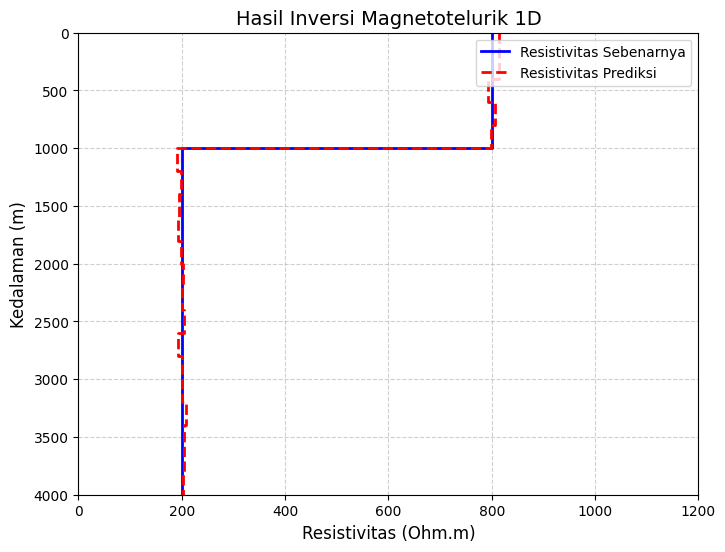

In [ ]:
plot_model_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, total_depth)

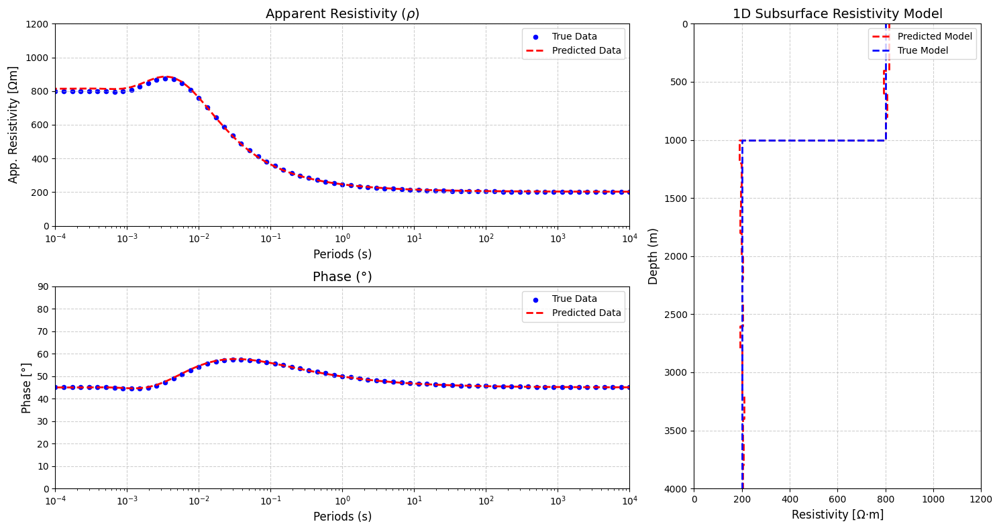

In [ ]:
plot_MT_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, period, fasa, resistivitas_semu, fasa_predict,resistivitas_semu_predict, total_depth)

### Error

In [ ]:
measure_MSE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MSE Resistivitas Semu: 51.71
MSE Fasa: 0.03


In [ ]:
measure_MAPE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MAPE resistivitas semu: 1.04%
MAPE fasa: 0.22%


In [ ]:
measure_RMSE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

RMSE Resistivitas Semu: 7.19
RMSE Fasa: 0.16


[Interpolated] MSE model resistivitas: 45.8354
[Interpolated] RMSE model resistivitas: 6.7702
[Interpolated] MAPE model resistivitas: 1.85%


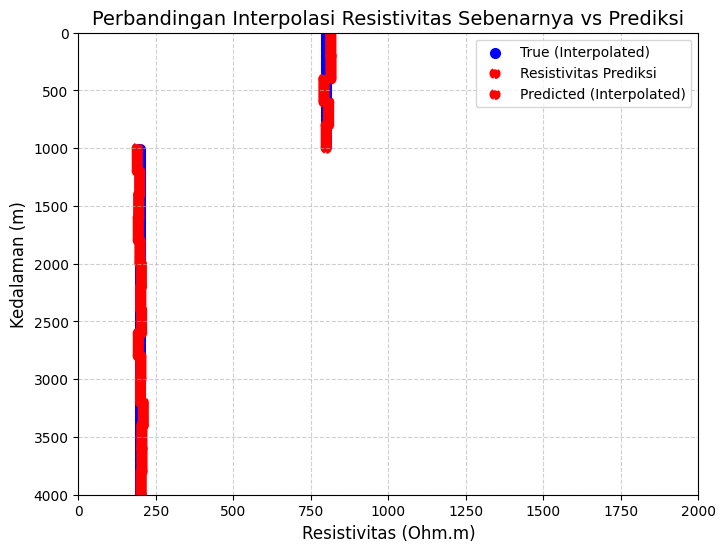

In [ ]:
measure_interpolated_resistivities(resis_true,ketebalan_true,resis_predict,ketebalan_predict,total_depth)

# Prediksi Bumi 3 Lapis

## Model Bumi 3 Lapis I

### Prediksi

In [ ]:


# Forward modelling untuk data input
resis_true= np.array([100, 200, 800])
ketebalan_true = np.array([300,1000])
period = 1/frequencies
resistivitas_semu, fasa = forward_modelling(resis_true, ketebalan_true, frequencies)

resistivitas_semu = np.array([resistivitas_semu])
fasa = np.array([fasa])

#Reshape sebelum normalisasi
resistivitas_semu = resistivitas_semu[0].reshape(1, X_input_res.shape[1]) # Corrected reshape syntax
fasa = fasa.reshape(1, X_input_phase.shape[1])

# Logaritma Data Input
resistivitas_semu_log = np.log10(resistivitas_semu)
fasa_log = np.log10(fasa)

# Normalisasi data input
resistivitas_semu_normalized = input_res_scaler.transform(resistivitas_semu_log)
fasa_normalized = input_phase_scaler.transform(fasa_log)

# Reshape jika perlu (misalnya, untuk input CNN)
resistivitas_semu_normalized = resistivitas_semu_normalized.reshape(1, X_input_res.shape[1], 1)
fasa_normalized = fasa_normalized.reshape(1, X_input_phase.shape[1], 1)

# Prediksi
predictions = model.predict([resistivitas_semu_normalized, fasa_normalized])

# Denormalisasi hasil prediksi, apply to the predictions, not hasil
predictions_denormalized = output_model_scaler.inverse_transform(predictions)
predictions_denormalized = np.power(10, predictions_denormalized)

# Accessing the values from predictions_denormalized
resis_predict = predictions_denormalized[0] #
ketebalan_predict = np.full(jumlah_layer-1,layer_thickness)

#Forward Modelling from prediction model
resistivitas_semu_predict, fasa_predict = forward_modelling(resis_predict,ketebalan_predict,frequencies)
resistivitas_semu_predict = np.array([resistivitas_semu_predict])
fasa_predict = np.array([fasa_predict])


#print(hasil) #No need to print hasil as it's not used

print("Nilai Resis_True", resis_true)
print("Nilai ketebalan_True",ketebalan_true)
print("Nilai resis_predict",resis_predict)
print("Nilai ketebalan_predict",ketebalan_predict)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step
Nilai Resis_True [100 200 800]
Nilai ketebalan_True [ 300 1000]
Nilai resis_predict [100.11667 120.92463 296.7307  173.53937 189.19612 166.44109 544.5042
 667.8188  718.9537  770.4044  783.2801  807.9938  841.1812  824.2248
 848.46173 833.23785 831.4197  798.63226 798.32806 801.72345]
Nilai ketebalan_predict [200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200.
 200. 200. 200. 200. 200.]


### Grafik

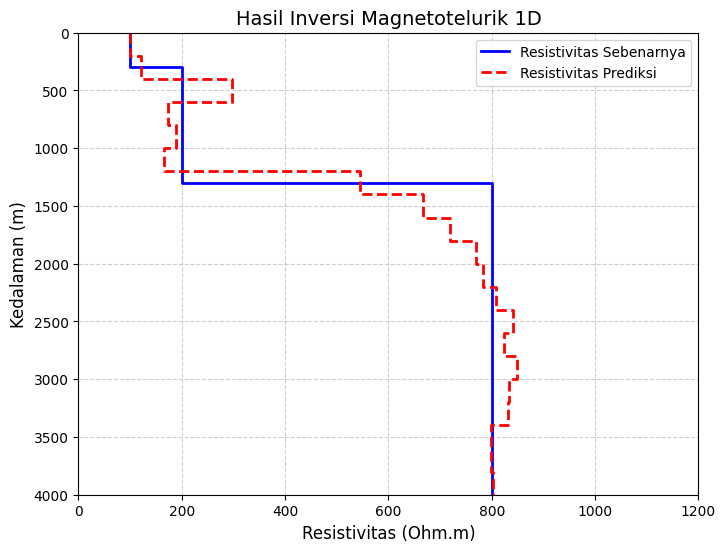

In [ ]:
plot_model_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, total_depth)

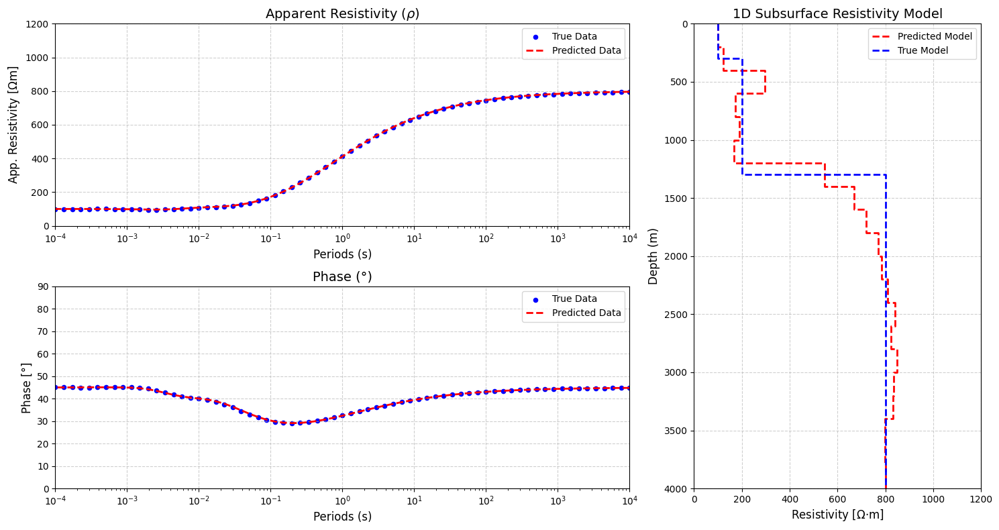

In [ ]:
plot_MT_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, period, fasa, resistivitas_semu, fasa_predict,resistivitas_semu_predict, total_depth)


### Error

In [ ]:
measure_MSE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MSE Resistivitas Semu: 1.19
MSE Fasa: 0.02


In [ ]:
measure_MAPE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MAPE resistivitas semu: 0.38%
MAPE fasa: 0.19%


In [ ]:
measure_RMSE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

RMSE Resistivitas Semu: 1.09
RMSE Fasa: 0.12


[Interpolated] MSE model resistivitas: 6930.8487
[Interpolated] RMSE model resistivitas: 83.2517
[Interpolated] MAPE model resistivitas: 13.63%


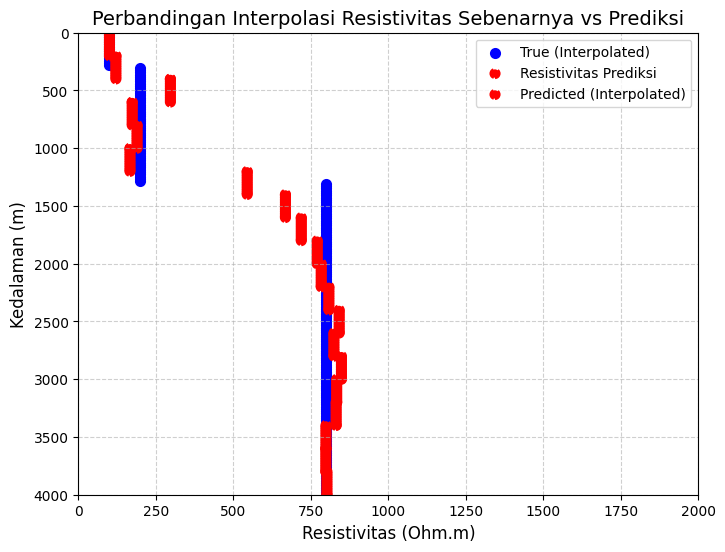

In [ ]:
measure_interpolated_resistivities(resis_true,ketebalan_true,resis_predict,ketebalan_predict,total_depth)

## Model Bumi 3 Lapis II

### Prediksi

In [ ]:


# Forward modelling untuk data input
resis_true= np.array([100, 800, 200])
ketebalan_true = np.array([300,1000])
period = 1/frequencies
resistivitas_semu, fasa = forward_modelling(resis_true, ketebalan_true, frequencies)

resistivitas_semu = np.array([resistivitas_semu])
fasa = np.array([fasa])

#Reshape sebelum normalisasi
resistivitas_semu = resistivitas_semu[0].reshape(1, X_input_res.shape[1]) # Corrected reshape syntax
fasa = fasa.reshape(1, X_input_phase.shape[1])

# Logaritma Data Input
resistivitas_semu_log = np.log10(resistivitas_semu)
fasa_log = np.log10(fasa)

# Normalisasi data input
resistivitas_semu_normalized = input_res_scaler.transform(resistivitas_semu_log)
fasa_normalized = input_phase_scaler.transform(fasa_log)
# Reshape jika perlu (misalnya, untuk input CNN)
resistivitas_semu_normalized = resistivitas_semu_normalized.reshape(1, X_input_res.shape[1], 1)
fasa_normalized = fasa_normalized.reshape(1, X_input_phase.shape[1], 1)

# Prediksi
predictions = model.predict([resistivitas_semu_normalized, fasa_normalized])

# Denormalisasi hasil prediksi, apply to the predictions, not hasil
predictions_denormalized = output_model_scaler.inverse_transform(predictions)
predictions_denormalized = np.power(10, predictions_denormalized)

# Accessing the values from predictions_denormalized
resis_predict = predictions_denormalized[0] #
ketebalan_predict = np.full(jumlah_layer-1,layer_thickness)

#Forward Modelling from prediction model
resistivitas_semu_predict, fasa_predict = forward_modelling(resis_predict,ketebalan_predict,frequencies)
resistivitas_semu_predict = np.array([resistivitas_semu_predict])
fasa_predict = np.array([fasa_predict])


#print(hasil) #No need to print hasil as it's not used

print("Nilai Resis_True", resis_true)
print("Nilai ketebalan_True",ketebalan_true)
print("Nilai resis_predict",resis_predict)
print("Nilai ketebalan_predict",ketebalan_predict)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
Nilai Resis_True [100 800 200]
Nilai ketebalan_True [ 300 1000]
Nilai resis_predict [ 104.473465  192.95316  1110.3948    607.3748    856.44257   859.557
  430.52808   167.13641   205.55373   197.22476   188.0238    193.36406
  218.2852    216.24171   210.40797   211.0842    198.95482   195.14346
  201.48251   197.9624  ]
Nilai ketebalan_predict [200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200.
 200. 200. 200. 200. 200.]


### Grafik

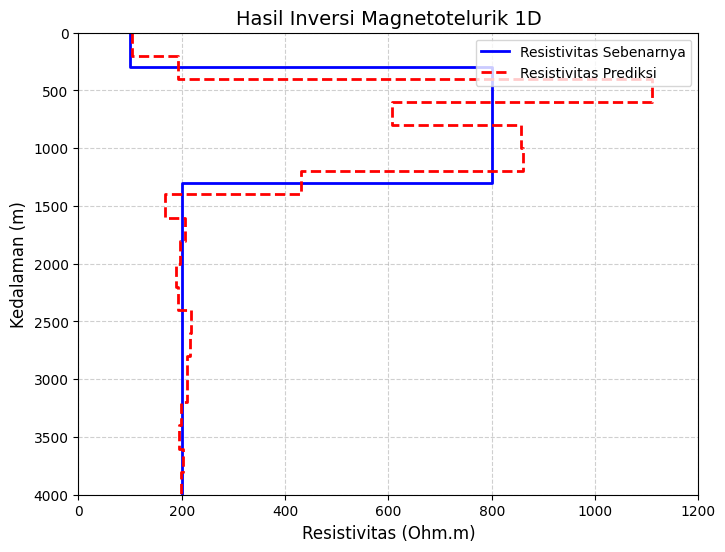

In [ ]:
plot_model_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, total_depth)

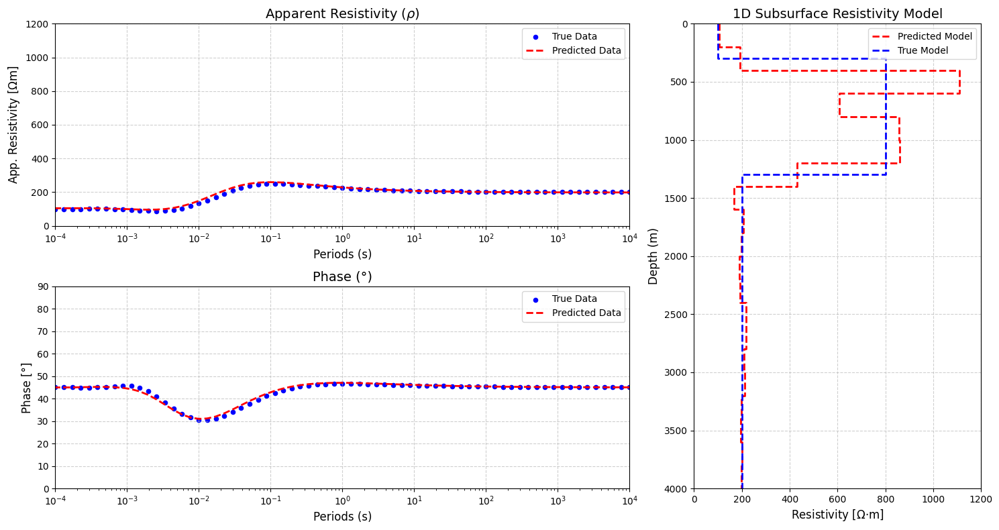

In [ ]:
plot_MT_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, period, fasa, resistivitas_semu, fasa_predict,resistivitas_semu_predict, total_depth)

### Error

In [ ]:
measure_MSE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MSE Resistivitas Semu: 55.14
MSE Fasa: 0.38


In [ ]:
measure_MAPE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MAPE resistivitas semu: 3.39%
MAPE fasa: 1.02%


In [ ]:
measure_RMSE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

RMSE Resistivitas Semu: 7.43
RMSE Fasa: 0.61


[Interpolated] MSE model resistivitas: 21288.4000
[Interpolated] RMSE model resistivitas: 145.9054
[Interpolated] MAPE model resistivitas: 15.48%


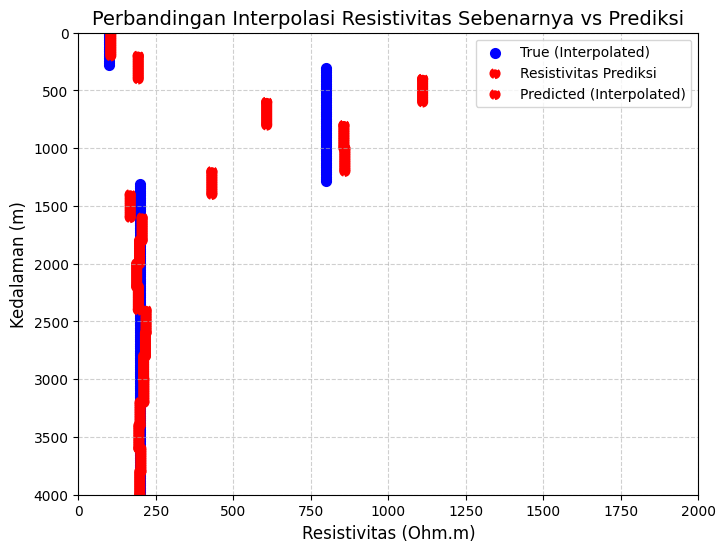

In [ ]:
measure_interpolated_resistivities(resis_true,ketebalan_true,resis_predict,ketebalan_predict,total_depth)

## Model Bumi 3 Lapis III

### Prediksi

In [ ]:


# Forward modelling untuk data input
resis_true= np.array([200, 100, 800])
ketebalan_true = np.array([300,1000])
period = 1/frequencies
resistivitas_semu, fasa = forward_modelling(resis_true, ketebalan_true, frequencies)

resistivitas_semu = np.array([resistivitas_semu])
fasa = np.array([fasa])

#Reshape sebelum normalisasi
resistivitas_semu = resistivitas_semu[0].reshape(1, X_input_res.shape[1]) # Corrected reshape syntax
fasa = fasa.reshape(1, X_input_phase.shape[1])

# Logaritma Data Input
resistivitas_semu_log = np.log10(resistivitas_semu)
fasa_log = np.log10(fasa)

# Normalisasi data input
resistivitas_semu_normalized = input_res_scaler.transform(resistivitas_semu_log)
fasa_normalized = input_phase_scaler.transform(fasa_log)

# Reshape jika perlu (misalnya, untuk input CNN)
resistivitas_semu_normalized = resistivitas_semu_normalized.reshape(1, X_input_res.shape[1], 1)
fasa_normalized = fasa_normalized.reshape(1, X_input_phase.shape[1], 1)

# Prediksi
predictions = model.predict([resistivitas_semu_normalized, fasa_normalized])

# Denormalisasi hasil prediksi, apply to the predictions, not hasil
predictions_denormalized = output_model_scaler.inverse_transform(predictions)
predictions_denormalized = np.power(10, predictions_denormalized)

# Accessing the values from predictions_denormalized
resis_predict = predictions_denormalized[0] #
ketebalan_predict = np.full(jumlah_layer-1,layer_thickness)

#Forward Modelling from prediction model
resistivitas_semu_predict, fasa_predict = forward_modelling(resis_predict,ketebalan_predict,frequencies)
resistivitas_semu_predict = np.array([resistivitas_semu_predict])
fasa_predict = np.array([fasa_predict])


#print(hasil) #No need to print hasil as it's not used

print("Nilai Resis_True", resis_true)
print("Nilai ketebalan_True",ketebalan_true)
print("Nilai resis_predict",resis_predict)
print("Nilai ketebalan_predict",ketebalan_predict)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
Nilai Resis_True [200 100 800]
Nilai ketebalan_True [ 300 1000]
Nilai resis_predict [194.96046 153.4684   82.62941 108.30379 108.54688  89.06888 247.78848
 704.9598  797.4336  841.04456 848.0133  872.9814  885.9645  805.736
 772.8405  754.3908  773.4738  783.0423  769.25995 807.4195 ]
Nilai ketebalan_predict [200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200.
 200. 200. 200. 200. 200.]


### Grafik

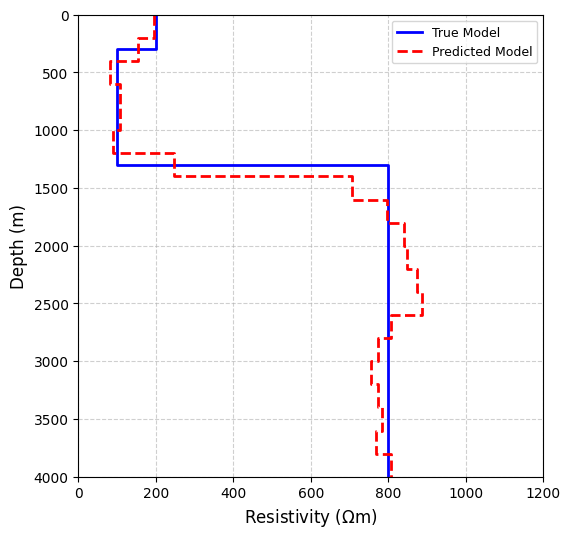

In [ ]:
plot_model_compare_2(resis_true, ketebalan_true, resis_predict, ketebalan_predict, total_depth)

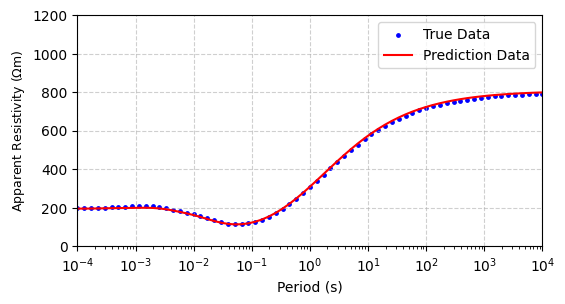

In [ ]:
plot_appres(resistivitas_semu, resistivitas_semu_predict, frequencies)

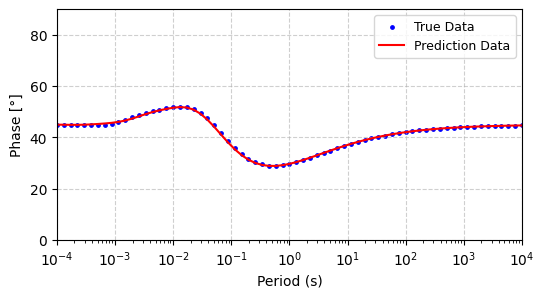

In [ ]:
plot_phase(fasa, fasa_predict, frequencies)

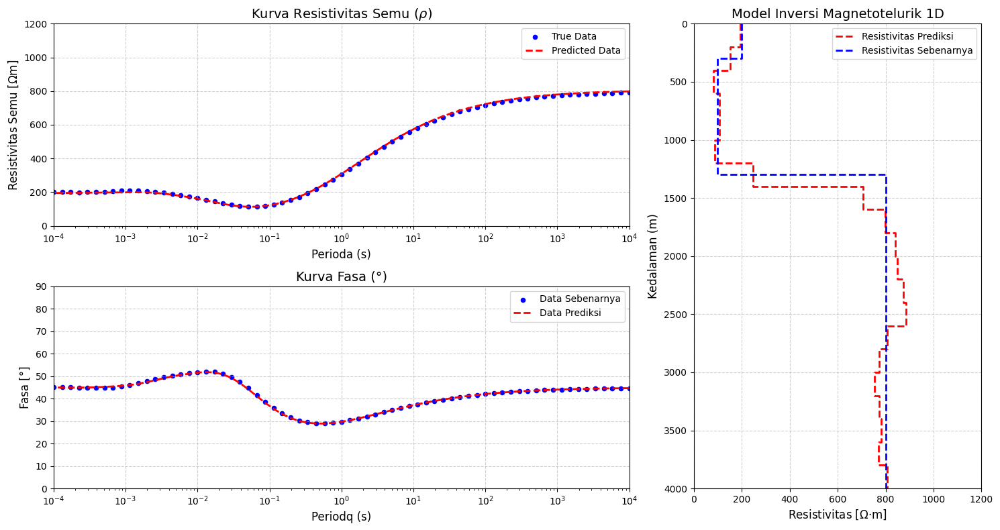

In [ ]:
plot_MT_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, period, fasa, resistivitas_semu, fasa_predict,resistivitas_semu_predict, total_depth)

### Error

In [ ]:
measure_MSE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MSE Resistivitas Semu: 32.40
MSE Fasa: 0.06


In [ ]:
measure_MAPE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MAPE resistivitas semu: 1.52%
MAPE fasa: 0.35%


(np.float64(1.5242671305165911), np.float64(0.34522230822507133))

In [ ]:
measure_RMSE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

RMSE Resistivitas Semu: 5.69
RMSE Fasa: 0.24


[Interpolated] MSE model resistivitas: 9853.8715
[Interpolated] RMSE model resistivitas: 99.2667
[Interpolated] MAPE model resistivitas: 12.88%


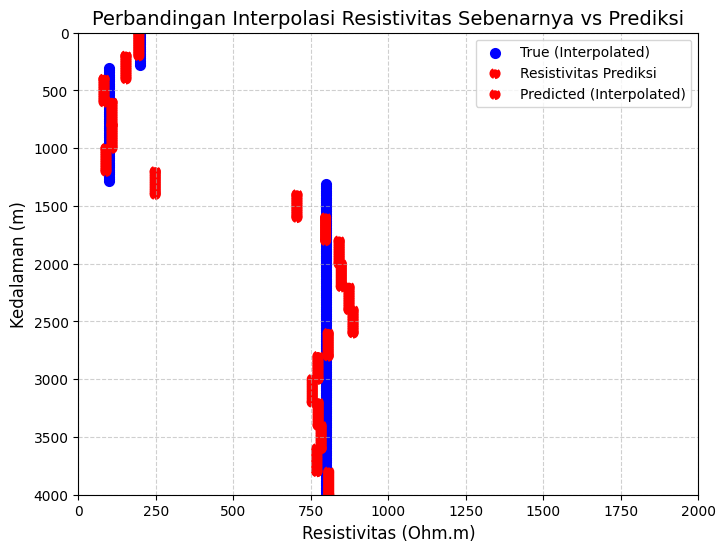

In [ ]:
measure_interpolated_resistivities(resis_true,ketebalan_true,resis_predict,ketebalan_predict,total_depth)

MAPE resistivitas semu: 1.52%
MAPE fasa: 0.35%


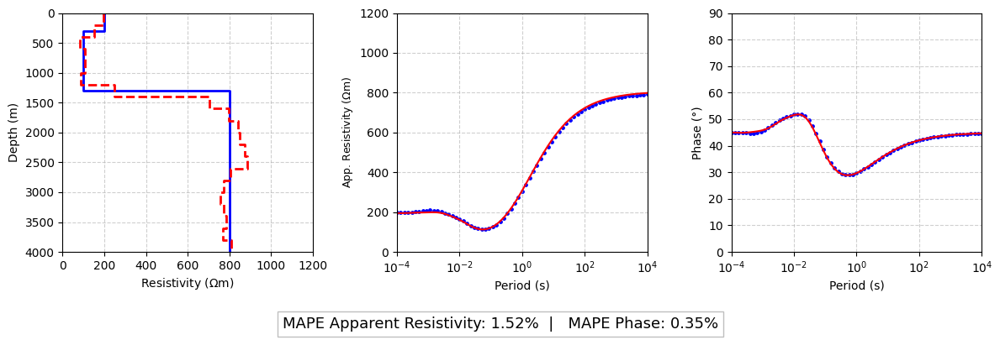

In [ ]:
plot_model_full(resis_true, ketebalan_true,
                    resis_predict, ketebalan_predict,
                    resistivitas_semu, resistivitas_semu_predict,
                    fasa, fasa_predict,
                    frequencies, total_depth)

## Model Bumi 3 Lapis IV

### Prediksi

In [ ]:


# Forward modelling untuk data input
resis_true= np.array([200, 800, 100])
ketebalan_true = np.array([300,1000])
period = 1/frequencies
resistivitas_semu, fasa = forward_modelling(resis_true, ketebalan_true, frequencies)

resistivitas_semu = np.array([resistivitas_semu])
fasa = np.array([fasa])

#Reshape sebelum normalisasi
resistivitas_semu = resistivitas_semu[0].reshape(1, X_input_res.shape[1]) # Corrected reshape syntax
fasa = fasa.reshape(1, X_input_phase.shape[1])

# Logaritma Data Input
resistivitas_semu_log = np.log10(resistivitas_semu)
fasa_log = np.log10(fasa)

# Normalisasi data input
resistivitas_semu_normalized = input_res_scaler.transform(resistivitas_semu_log)
fasa_normalized = input_phase_scaler.transform(fasa_log)

# Reshape jika perlu (misalnya, untuk input CNN)
resistivitas_semu_normalized = resistivitas_semu_normalized.reshape(1, X_input_res.shape[1], 1)
fasa_normalized = fasa_normalized.reshape(1, X_input_phase.shape[1], 1)

# Prediksi
predictions = model.predict([resistivitas_semu_normalized, fasa_normalized])

# Denormalisasi hasil prediksi, apply to the predictions, not hasil
predictions_denormalized = output_model_scaler.inverse_transform(predictions)
predictions_denormalized = np.power(10, predictions_denormalized)

# Accessing the values from predictions_denormalized
resis_predict = predictions_denormalized[0] #
ketebalan_predict = np.full(jumlah_layer-1,layer_thickness)

#Forward Modelling from prediction model
resistivitas_semu_predict, fasa_predict = forward_modelling(resis_predict,ketebalan_predict,frequencies)
resistivitas_semu_predict = np.array([resistivitas_semu_predict])
fasa_predict = np.array([fasa_predict])


#print(hasil) #No need to print hasil as it's not used

print("Nilai Resis_True", resis_true)
print("Nilai ketebalan_True",ketebalan_true)
print("Nilai resis_predict",resis_predict)
print("Nilai ketebalan_predict",ketebalan_predict)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
Nilai Resis_True [200 800 100]
Nilai ketebalan_True [ 300 1000]
Nilai resis_predict [ 220.24582   302.0665   1048.029     651.1094    774.6752    823.3791
  323.1163     88.64626    94.842026   96.964455   99.27508    99.94951
  104.80377   101.105064  102.25703    98.9835     97.41742    96.8425
  102.60927   109.763985]
Nilai ketebalan_predict [200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200.
 200. 200. 200. 200. 200.]


###Grafik

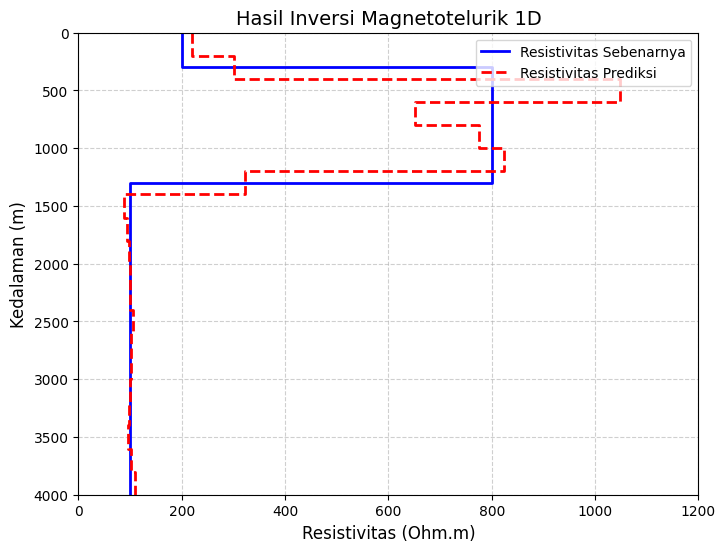

In [ ]:
plot_model_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, total_depth)

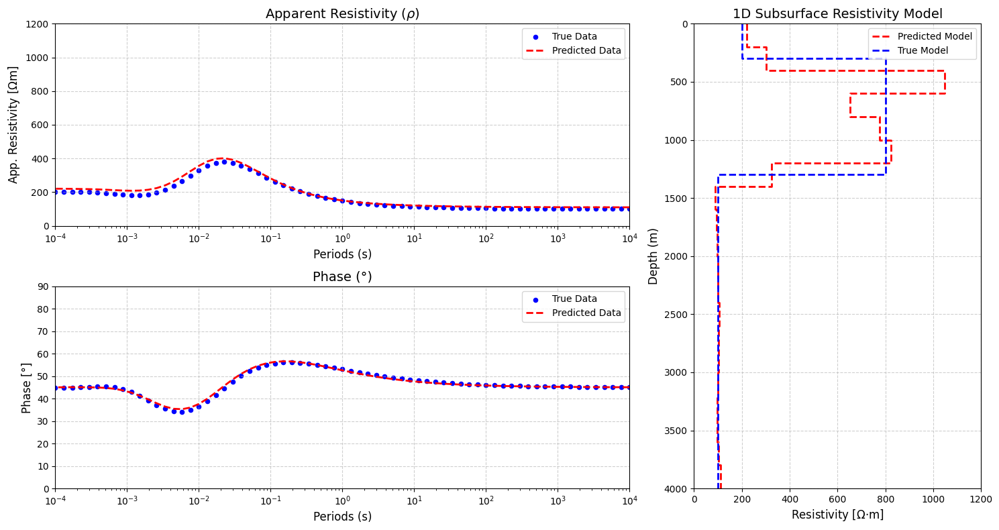

In [ ]:
plot_MT_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, period, fasa, resistivitas_semu, fasa_predict,resistivitas_semu_predict, total_depth)

### Error

In [ ]:
measure_MSE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MSE Resistivitas Semu: 217.26
MSE Fasa: 0.35


In [ ]:
measure_MAPE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MAPE resistivitas semu: 7.34%
MAPE fasa: 1.05%


In [ ]:
measure_RMSE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

RMSE Resistivitas Semu: 14.74
RMSE Fasa: 0.59


[Interpolated] MSE model resistivitas: 17668.8129
[Interpolated] RMSE model resistivitas: 132.9241
[Interpolated] MAPE model resistivitas: 15.57%


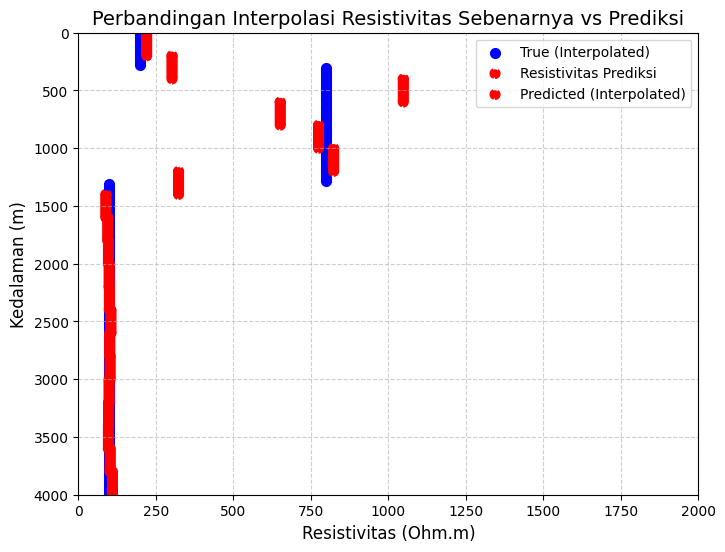

In [ ]:
measure_interpolated_resistivities(resis_true,ketebalan_true,resis_predict,ketebalan_predict,total_depth)

## Model Bumi 3 Lapis V

### Prediksi

In [ ]:


# Forward modelling untuk data input
resis_true= np.array([800, 100, 200])
ketebalan_true = np.array([300,1000])
period = 1/frequencies
resistivitas_semu, fasa = forward_modelling(resis_true, ketebalan_true, frequencies)

resistivitas_semu = np.array([resistivitas_semu])
fasa = np.array([fasa])

#Reshape sebelum normalisasi
resistivitas_semu = resistivitas_semu[0].reshape(1, X_input_res.shape[1]) # Corrected reshape syntax
fasa = fasa.reshape(1, X_input_phase.shape[1])

# Logaritma Data Input
resistivitas_semu_log = np.log10(resistivitas_semu)
fasa_log = np.log10(fasa)

# Normalisasi data input
resistivitas_semu_normalized = input_res_scaler.transform(resistivitas_semu_log)
fasa_normalized = input_phase_scaler.transform(fasa_log)

# Reshape jika perlu (misalnya, untuk input CNN)
resistivitas_semu_normalized = resistivitas_semu_normalized.reshape(1, X_input_res.shape[1], 1)
fasa_normalized = fasa_normalized.reshape(1, X_input_phase.shape[1], 1)

# Prediksi
predictions = model.predict([resistivitas_semu_normalized, fasa_normalized])

# Denormalisasi hasil prediksi, apply to the predictions, not hasil
predictions_denormalized = output_model_scaler.inverse_transform(predictions)
predictions_denormalized = np.power(10, predictions_denormalized)

# Accessing the values from predictions_denormalized
resis_predict = predictions_denormalized[0] #
ketebalan_predict = np.full(jumlah_layer-1,layer_thickness)

#Forward Modelling from prediction model
resistivitas_semu_predict, fasa_predict = forward_modelling(resis_predict,ketebalan_predict,frequencies)
resistivitas_semu_predict = np.array([resistivitas_semu_predict])
fasa_predict = np.array([fasa_predict])


#print(hasil) #No need to print hasil as it's not used

print("Nilai Resis_True", resis_true)
print("Nilai ketebalan_True",ketebalan_true)
print("Nilai resis_predict",resis_predict)
print("Nilai ketebalan_predict",ketebalan_predict)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
Nilai Resis_True [800 100 200]
Nilai ketebalan_True [ 300 1000]
Nilai resis_predict [886.3498   427.21896   75.570435 106.53377  103.39276   95.063545
 194.04176  151.58307  199.91972  199.96506  208.48366  211.81319
 217.70073  196.43985  193.3922   190.63196  190.6776   181.83168
 195.17924  190.6124  ]
Nilai ketebalan_predict [200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200.
 200. 200. 200. 200. 200.]


### Grafik

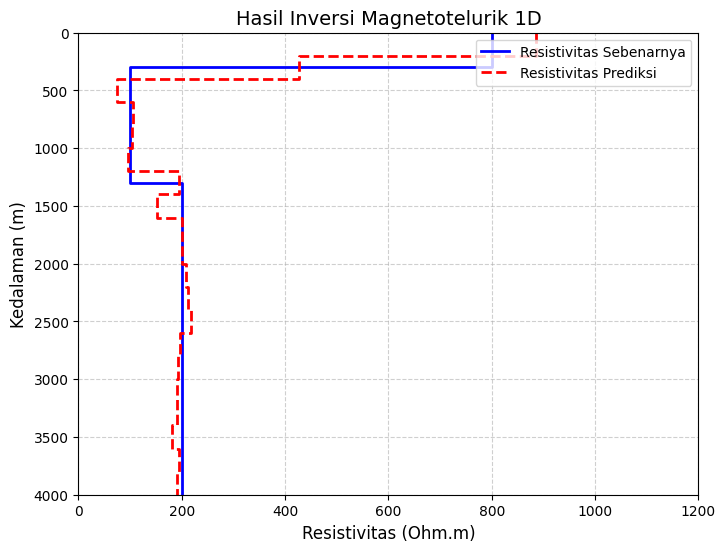

In [ ]:
plot_model_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, total_depth)


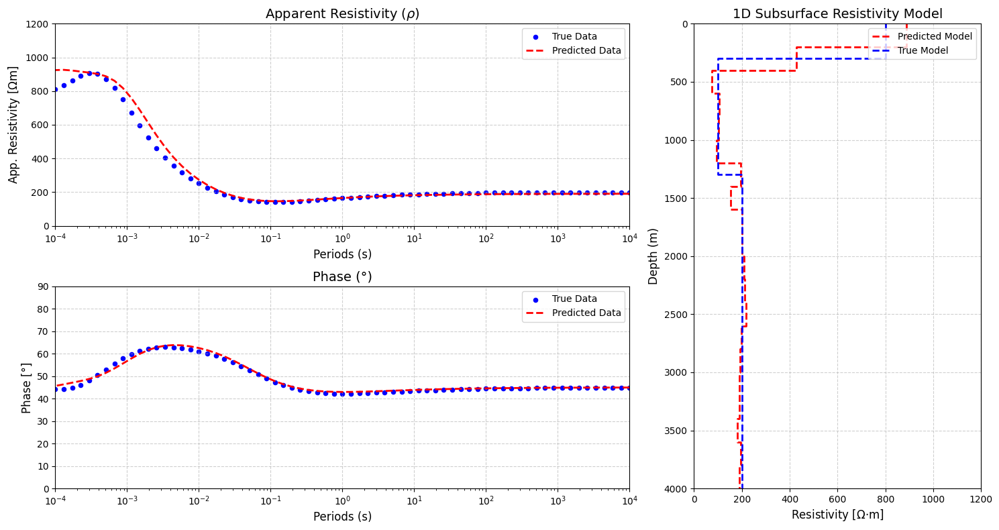

In [ ]:
plot_MT_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, period, fasa, resistivitas_semu, fasa_predict,resistivitas_semu_predict, total_depth)

### Error

In [ ]:
measure_MSE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MSE Resistivitas Semu: 1063.97
MSE Fasa: 0.82


In [ ]:
measure_MAPE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MAPE resistivitas semu: 5.16%
MAPE fasa: 1.33%


In [ ]:
measure_RMSE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

RMSE Resistivitas Semu: 32.62
RMSE Fasa: 0.90


[Interpolated] MSE model resistivitas: 6956.5909
[Interpolated] RMSE model resistivitas: 83.4062
[Interpolated] MAPE model resistivitas: 17.97%


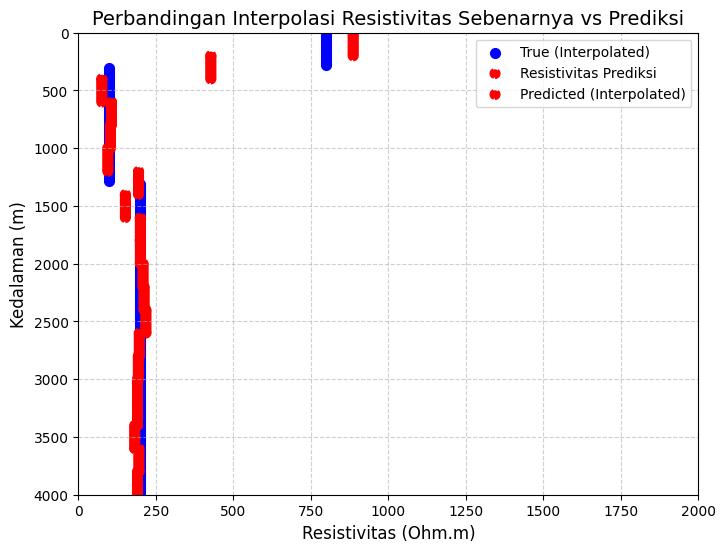

In [ ]:
measure_interpolated_resistivities(resis_true,ketebalan_true,resis_predict,ketebalan_predict,total_depth)

## Model Bumi 3 Lapis VI

### Prediksi

In [ ]:

start = time.time()
# Forward modelling untuk data input
resis_true= np.array([ 800, 200, 50])
ketebalan_true = np.array([300,1000])

period = 1/frequencies
resistivitas_semu, fasa = forward_modelling(resis_true, ketebalan_true, frequencies)

resistivitas_semu = np.array([resistivitas_semu])
fasa = np.array([fasa])

#Reshape sebelum normalisasi
resistivitas_semu = resistivitas_semu[0].reshape(1, X_input_res.shape[1]) # Corrected reshape syntax
fasa = fasa.reshape(1, X_input_phase.shape[1])

# Logaritma Data Input
resistivitas_semu_log = np.log10(resistivitas_semu)
fasa_log = np.log10(fasa)

# Normalisasi data input
resistivitas_semu_normalized = input_res_scaler.transform(resistivitas_semu_log)
fasa_normalized = input_phase_scaler.transform(fasa_log)

# Reshape jika perlu (misalnya, untuk input CNN)
resistivitas_semu_normalized = resistivitas_semu_normalized.reshape(1, X_input_res.shape[1], 1)
fasa_normalized = fasa_normalized.reshape(1, X_input_phase.shape[1], 1)

# Prediksi
predictions = model.predict([resistivitas_semu_normalized, fasa_normalized])

# Denormalisasi hasil prediksi, apply to the predictions, not hasil
predictions_denormalized = output_model_scaler.inverse_transform(predictions)
predictions_denormalized = np.power(10, predictions_denormalized)

# Accessing the values from predictions_denormalized
resis_predict = predictions_denormalized[0] #
ketebalan_predict = np.full(jumlah_layer-1,layer_thickness)

#Forward Modelling from prediction model
resistivitas_semu_predict, fasa_predict = forward_modelling(resis_predict,ketebalan_predict,frequencies)
resistivitas_semu_predict = np.array([resistivitas_semu_predict])
fasa_predict = np.array([fasa_predict])


#print(hasil) #No need to print hasil as it's not used

print("Nilai Resis_True", resis_true)
print("Nilai ketebalan_True",ketebalan_true)
print("Nilai resis_predict",resis_predict)
print("Nilai ketebalan_predict",ketebalan_predict)
end = time.time()
print(end-start)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
Nilai Resis_True [800 200  50]
Nilai ketebalan_True [ 300 1000]
Nilai resis_predict [831.8936   509.52695  157.89662  225.8076   212.2116   306.49457
  75.93313   55.83834   48.803577  52.125168  51.94714   49.160824
  51.09154   52.537365  54.11079   52.922207  52.27408   51.1538
  52.82217   47.65403 ]
Nilai ketebalan_predict [200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200.
 200. 200. 200. 200. 200.]
0.10279035568237305


### Grafik

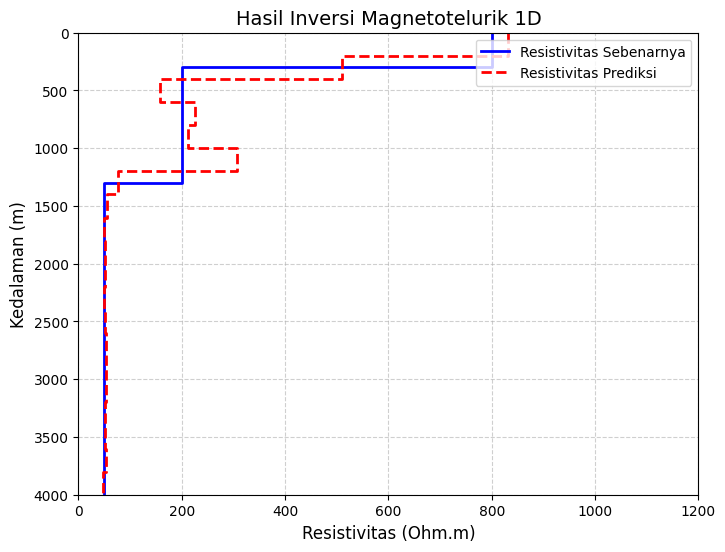

In [ ]:
plot_model_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, total_depth)

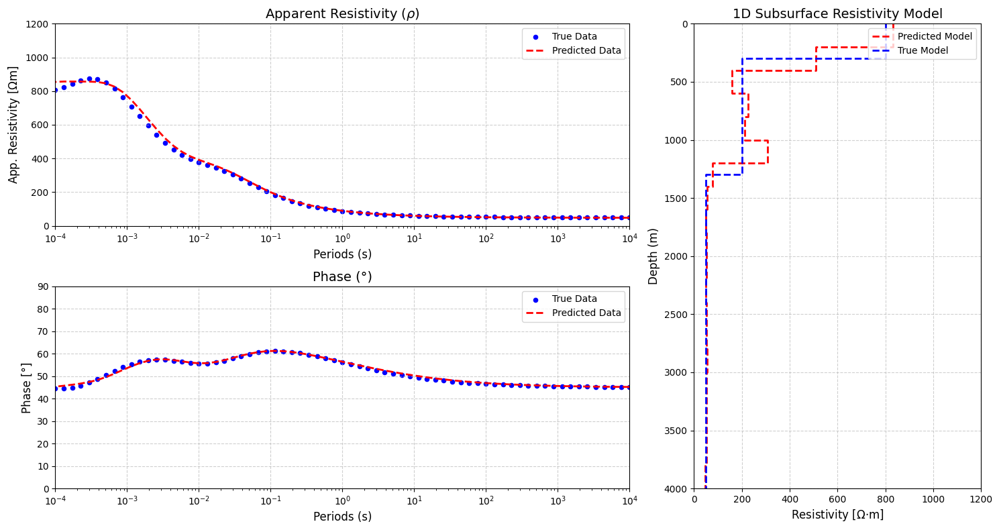

In [ ]:
plot_MT_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, period, fasa, resistivitas_semu, fasa_predict,resistivitas_semu_predict, total_depth)

### Error

In [ ]:
measure_MSE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MSE Resistivitas Semu: 204.90
MSE Fasa: 0.26


In [ ]:
measure_MAPE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MAPE resistivitas semu: 3.29%
MAPE fasa: 0.75%


In [ ]:
measure_RMSE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

RMSE Resistivitas Semu: 14.31
RMSE Fasa: 0.51


[Interpolated] MSE model resistivitas: 5658.3517
[Interpolated] RMSE model resistivitas: 75.2220
[Interpolated] MAPE model resistivitas: 15.61%


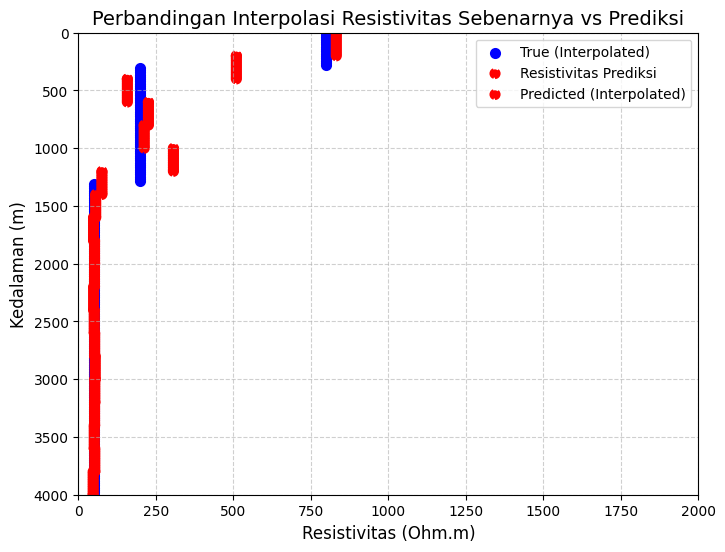

In [ ]:
measure_interpolated_resistivities(resis_true,ketebalan_true,resis_predict,ketebalan_predict,total_depth)

# Prediksi Bumi 4 Lapis

## Model Bumi 4 Lapis I

### Prediksi

In [ ]:


# Forward modelling untuk data input
resis_true= np.array([ 50, 200, 800, 1000])
ketebalan_true = np.array([200,500, 1000])
period = 1/frequencies
resistivitas_semu, fasa = forward_modelling(resis_true, ketebalan_true, frequencies)

resistivitas_semu = np.array([resistivitas_semu])
fasa = np.array([fasa])

#Reshape sebelum normalisasi
resistivitas_semu = resistivitas_semu[0].reshape(1, X_input_res.shape[1]) # Corrected reshape syntax
fasa = fasa.reshape(1, X_input_phase.shape[1])

# Logaritma Data Input
resistivitas_semu_log = np.log10(resistivitas_semu)
fasa_log = np.log10(fasa)

# Normalisasi data input
resistivitas_semu_normalized = input_res_scaler.transform(resistivitas_semu_log)
fasa_normalized = input_phase_scaler.transform(fasa_log)

# Reshape jika perlu (misalnya, untuk input CNN)
resistivitas_semu_normalized = resistivitas_semu_normalized.reshape(1, X_input_res.shape[1], 1)
fasa_normalized = fasa_normalized.reshape(1, X_input_phase.shape[1], 1)

# Prediksi
predictions = model.predict([resistivitas_semu_normalized, fasa_normalized])

# Denormalisasi hasil prediksi, apply to the predictions, not hasil
predictions_denormalized = output_model_scaler.inverse_transform(predictions)
predictions_denormalized = np.power(10, predictions_denormalized)

# Accessing the values from predictions_denormalized
resis_predict = predictions_denormalized[0] #
ketebalan_predict = np.full(jumlah_layer-1,layer_thickness)

#Forward Modelling from prediction model
resistivitas_semu_predict, fasa_predict = forward_modelling(resis_predict,ketebalan_predict,frequencies)
resistivitas_semu_predict = np.array([resistivitas_semu_predict])
fasa_predict = np.array([fasa_predict])


#print(hasil) #No need to print hasil as it's not used

print("Nilai Resis_True", resis_true)
print("Nilai ketebalan_True",ketebalan_true)
print("Nilai resis_predict",resis_predict)
print("Nilai ketebalan_predict",ketebalan_predict)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
Nilai Resis_True [  50  200  800 1000]
Nilai ketebalan_True [ 200  500 1000]
Nilai resis_predict [ 44.744293 198.36142  196.23032  395.83105  870.4064   807.22986
 832.0119   846.71216  887.1798   929.7489   941.2641   959.8892
 971.19214  930.16754  921.7117   898.0647   919.6374   915.4882
 957.0437   983.699   ]
Nilai ketebalan_predict [200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200.
 200. 200. 200. 200. 200.]


### Grafik

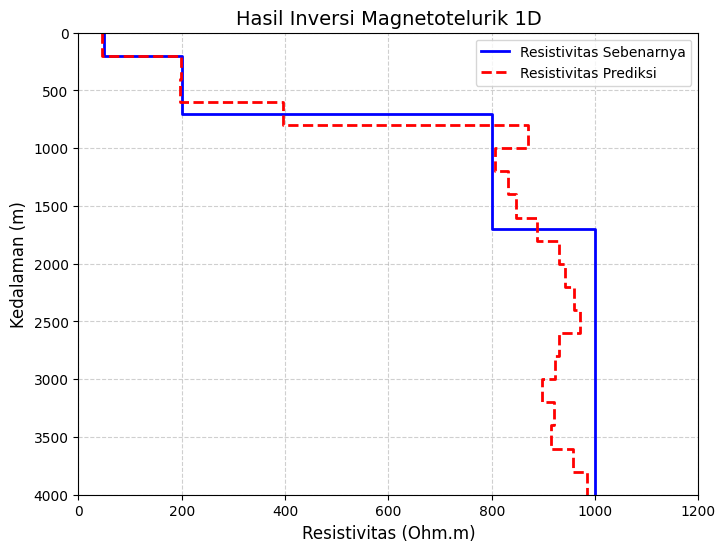

In [ ]:
plot_model_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, total_depth)

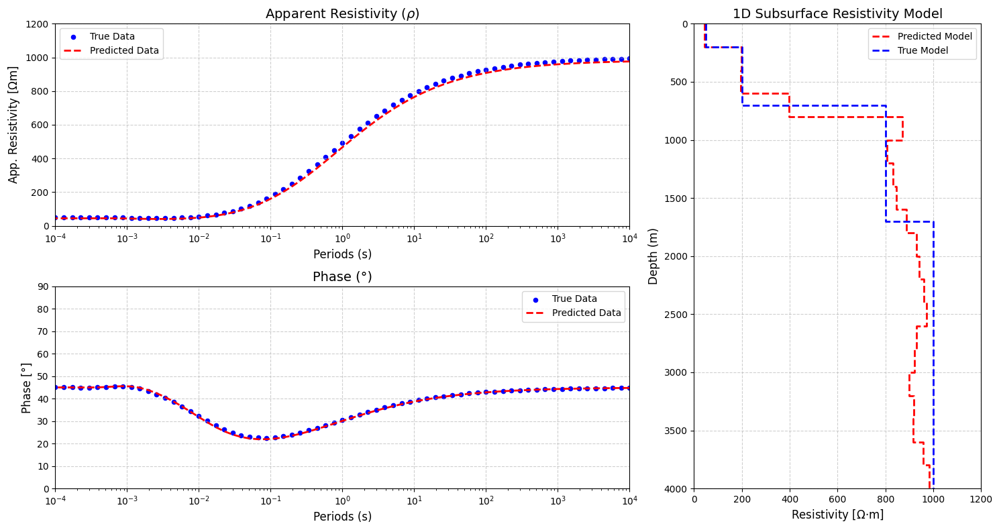

In [ ]:
plot_MT_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, period, fasa, resistivitas_semu, fasa_predict,resistivitas_semu_predict, total_depth)

### Error

In [ ]:
measure_MSE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MSE Resistivitas Semu: 281.19
MSE Fasa: 0.16


In [ ]:
measure_MAPE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MAPE resistivitas semu: 6.04%
MAPE fasa: 0.99%


In [ ]:
measure_RMSE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

RMSE Resistivitas Semu: 16.77
RMSE Fasa: 0.40


[Interpolated] MSE model resistivitas: 8360.3924
[Interpolated] RMSE model resistivitas: 91.4352
[Interpolated] MAPE model resistivitas: 9.26%


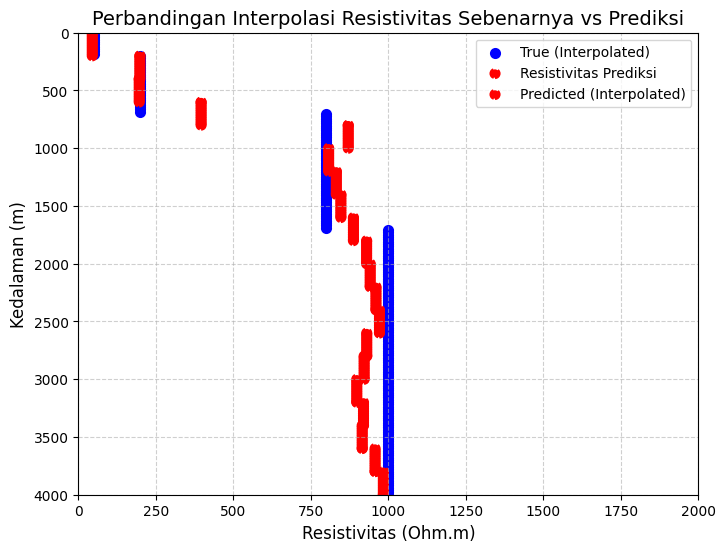

In [ ]:
measure_interpolated_resistivities(resis_true,ketebalan_true,resis_predict,ketebalan_predict,total_depth)

## Model Bumi 4 Lapis II

### Prediksi

In [ ]:


# Forward modelling untuk data input
resis_true= np.array([50, 800, 200, 1000])
ketebalan_true = np.array([200, 500, 1000])
period = 1/frequencies
resistivitas_semu, fasa = forward_modelling(resis_true, ketebalan_true, frequencies)

resistivitas_semu = np.array([resistivitas_semu])
fasa = np.array([fasa])

#Reshape sebelum normalisasi
resistivitas_semu = resistivitas_semu[0].reshape(1, X_input_res.shape[1]) # Corrected reshape syntax
fasa = fasa.reshape(1, X_input_phase.shape[1])

# Logaritma Data Input
resistivitas_semu_log = np.log10(resistivitas_semu)
fasa_log = np.log10(fasa)

# Normalisasi data input
resistivitas_semu_normalized = input_res_scaler.transform(resistivitas_semu_log)
fasa_normalized = input_phase_scaler.transform(fasa_log)

# Reshape jika perlu (misalnya, untuk input CNN)
resistivitas_semu_normalized = resistivitas_semu_normalized.reshape(1, X_input_res.shape[1], 1)
fasa_normalized = fasa_normalized.reshape(1, X_input_phase.shape[1], 1)

# Prediksi
predictions = model.predict([resistivitas_semu_normalized, fasa_normalized])

# Denormalisasi hasil prediksi, apply to the predictions, not hasil
predictions_denormalized = output_model_scaler.inverse_transform(predictions)
predictions_denormalized = np.power(10, predictions_denormalized)

# Accessing the values from predictions_denormalized
resis_predict = predictions_denormalized[0] #
ketebalan_predict = np.full(jumlah_layer-1,layer_thickness)

#Forward Modelling from prediction model
resistivitas_semu_predict, fasa_predict = forward_modelling(resis_predict,ketebalan_predict,frequencies)
resistivitas_semu_predict = np.array([resistivitas_semu_predict])
fasa_predict = np.array([fasa_predict])


#print(hasil) #No need to print hasil as it's not used

print("Nilai Resis_True", resis_true)
print("Nilai ketebalan_True",ketebalan_true)
print("Nilai resis_predict",resis_predict)
print("Nilai ketebalan_predict",ketebalan_predict)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
Nilai Resis_True [  50  800  200 1000]
Nilai ketebalan_True [ 200  500 1000]
Nilai resis_predict [ 43.41533 821.6104  957.4525  352.79315 175.47751 247.03331 170.24423
 171.84032 744.4217  907.4004  937.465   967.42896 984.75696 953.14636
 917.88916 940.9681  981.10486 970.2676  980.45123 979.4108 ]
Nilai ketebalan_predict [200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200.
 200. 200. 200. 200. 200.]


### Error

In [ ]:
measure_MSE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MSE Resistivitas Semu: 362.33
MSE Fasa: 0.49


In [ ]:
measure_MAPE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MAPE resistivitas semu: 7.77%
MAPE fasa: 1.53%


(np.float64(7.7681272247245605), np.float64(1.5277563990952858))

In [ ]:
measure_RMSE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

RMSE Resistivitas Semu: 19.04
RMSE Fasa: 0.70


[Interpolated] MSE model resistivitas: 17528.4434
[Interpolated] RMSE model resistivitas: 132.3950
[Interpolated] MAPE model resistivitas: 18.16%


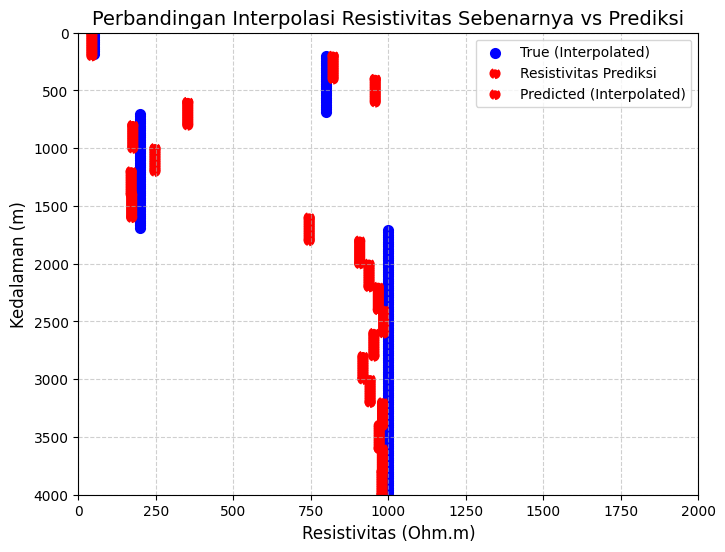

In [ ]:
measure_interpolated_resistivities(resis_true,ketebalan_true,resis_predict,ketebalan_predict,total_depth)

### Grafik

In [42]:
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec

def plot_model_full_2(res_true, ketebalan_true,
                    res_predict, ketebalan_predict,
                    resistivitas_semu, resistivitas_semu_predict,
                    fasa, fasa_predict,
                    frequencies, total_depth):

    # --- Format data untuk model ---
    depth_true_plot, resis_true_plot = formating_result(res_true, ketebalan_true, total_depth)
    depth_pred_plot, resis_pred_plot = formating_result(res_predict, ketebalan_predict, total_depth)
    mape_appres, mape_phase = measure_MAPE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)
    periods = 1/frequencies

    # --- Figure dengan GridSpec ---
    fig = plt.figure(figsize=(12, 6))
    gs = GridSpec(2, 1, height_ratios=[10, 1], figure=fig)

    # Subplot 3 kolom di row pertama
    axs = [fig.add_subplot(gs[0, 0], position=[0.07,0.25,0.25,0.65]),
           fig.add_subplot(gs[0, 0], position=[0.38,0.25,0.25,0.65]),
           fig.add_subplot(gs[0, 0], position=[0.69,0.25,0.25,0.65])]

    # ========== 1. Resistivity Model ==========
    axs[0].plot(resis_true_plot, depth_true_plot, color='blue', label='True Model', linewidth=2)
    axs[0].plot(resis_pred_plot, depth_pred_plot, color='red', linestyle='--', label='Predicted Model', linewidth=2)
    axs[0].set_xlabel('Resistivity ($\Omega$m)')
    axs[0].set_ylabel('Depth (m)')
    axs[0].set_xlim(0, 1200)
    axs[0].set_ylim(total_depth, 0)
    axs[0].grid(True, linestyle='--', alpha=0.6)

    # ========== 2. Apparent Resistivity ==========
    axs[1].scatter(periods, resistivitas_semu[0], color='blue', s=6, label='True Data')
    axs[1].plot(periods, resistivitas_semu_predict[0], color='red', linestyle='-', label='Prediction Data')
    axs[1].set_xscale('log')
    axs[1].set_xlim(1e-4, 1e4)
    axs[1].set_ylim(0, 1200)
    axs[1].set_xlabel('Period (s)')
    axs[1].set_ylabel('App. Resistivity ($\Omega$m)')
    axs[1].grid(True, linestyle='--', alpha=0.6)

    # ========== 3. Phase ==========
    axs[2].scatter(periods, fasa[0], color='blue', s=6, label='True Data')
    axs[2].plot(periods, fasa_predict[0], color='red', linestyle='-', label='Prediction Data')
    axs[2].set_xscale('log')
    axs[2].set_xlim(1e-4, 1e4)
    axs[2].set_ylim(0, 90)
    axs[2].set_xlabel('Period (s)')
    axs[2].set_ylabel('Phase (°)')
    axs[2].grid(True, linestyle='--', alpha=0.6)

    # Gabungkan legend
    lines, labels = [], []
    for ax in axs:
        line, label = ax.get_legend_handles_labels()
        lines.extend(line)
        labels.extend(label)
    by_label = dict(zip(labels, lines))

    legend_ax = fig.add_subplot(gs[1])
    legend_ax.axis('off')
    legend_ax.legend(by_label.values(), by_label.keys(),
                     loc='center', ncol=3, frameon=False, fontsize=10)

    fig.text(0.5, 0.03,
             f"MAPE Apparent Resistivity: {mape_appres:.2f}%  |  MAPE Phase: {mape_phase:.2f}%",
             ha='center', fontsize=11,
             bbox=dict(facecolor='white', edgecolor='gray', alpha=0.5))

    plt.show()

<>:28: SyntaxWarning: invalid escape sequence '\O'
<>:41: SyntaxWarning: invalid escape sequence '\O'
<>:28: SyntaxWarning: invalid escape sequence '\O'
<>:41: SyntaxWarning: invalid escape sequence '\O'
/tmp/ipython-input-3015988228.py:28: SyntaxWarning: invalid escape sequence '\O'
  axs[0].set_xlabel('Resistivity ($\Omega$m)')
/tmp/ipython-input-3015988228.py:41: SyntaxWarning: invalid escape sequence '\O'
  axs[1].set_ylabel('App. Resistivity ($\Omega$m)')


MAPE resistivitas semu: 1.97%
MAPE fasa: 0.41%


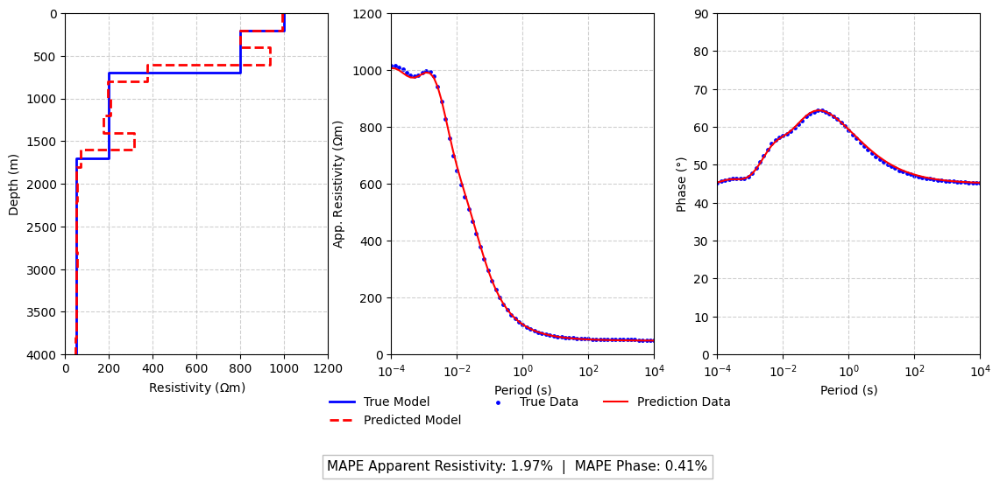

In [43]:
plot_model_full_2(resis_true, ketebalan_true,
                    resis_predict, ketebalan_predict,
                    resistivitas_semu, resistivitas_semu_predict,
                    fasa, fasa_predict,
                    frequencies, total_depth)

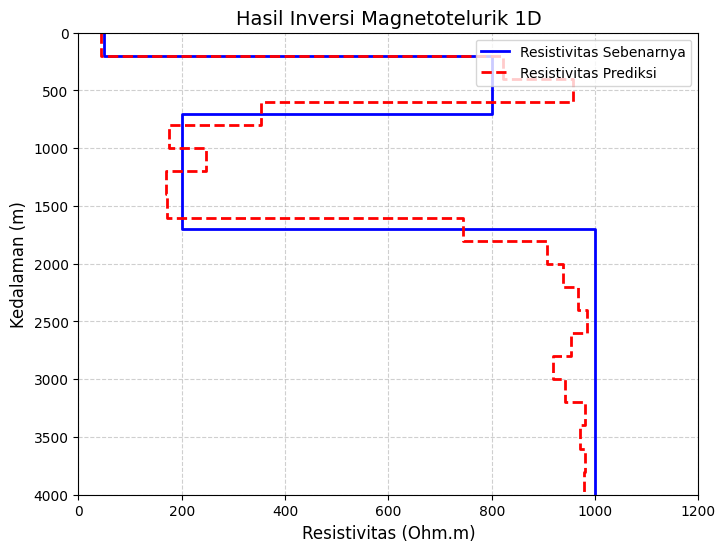

In [ ]:
plot_model_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, total_depth)

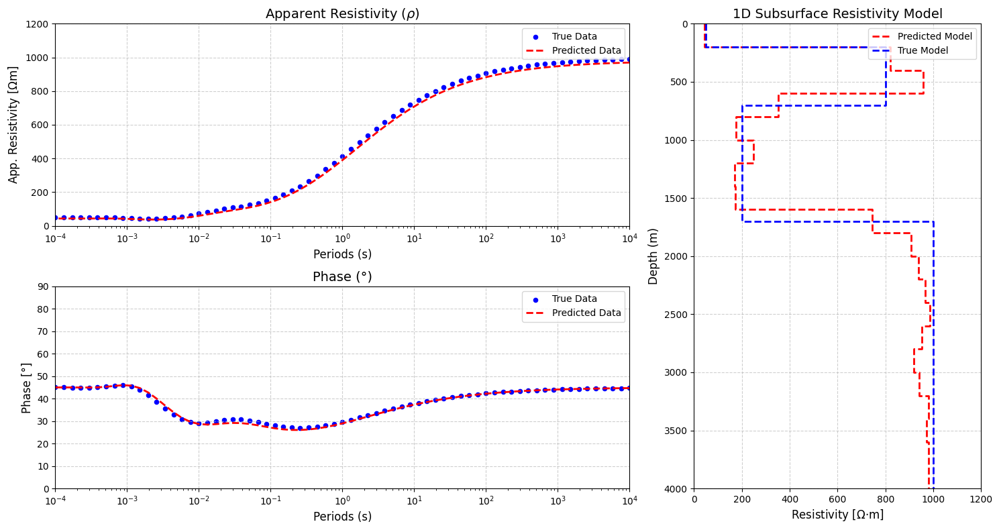

In [ ]:
plot_MT_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, period, fasa, resistivitas_semu, fasa_predict,resistivitas_semu_predict, total_depth)

## Model Bumi 4 Lapis III

### Prediksi

In [ ]:

start = time.time()
# Forward modelling untuk data input
resis_true= np.array([50, 1000, 200, 800])
ketebalan_true = np.array([200, 500, 1000])
period = 1/frequencies
resistivitas_semu, fasa = forward_modelling(resis_true, ketebalan_true, frequencies)

resistivitas_semu = np.array([resistivitas_semu])
fasa = np.array([fasa])

#Reshape sebelum normalisasi
resistivitas_semu = resistivitas_semu[0].reshape(1, X_input_res.shape[1]) # Corrected reshape syntax
fasa = fasa.reshape(1, X_input_phase.shape[1])

# Logaritma Data Input
resistivitas_semu_log = np.log10(resistivitas_semu)
fasa_log = np.log10(fasa)

# Normalisasi data input
resistivitas_semu_normalized = input_res_scaler.transform(resistivitas_semu_log)
fasa_normalized = input_phase_scaler.transform(fasa_log)

# Reshape jika perlu (misalnya, untuk input CNN)
resistivitas_semu_normalized = resistivitas_semu_normalized.reshape(1, X_input_res.shape[1], 1)
fasa_normalized = fasa_normalized.reshape(1, X_input_phase.shape[1], 1)

# Prediksi
predictions = model.predict([resistivitas_semu_normalized, fasa_normalized])

# Denormalisasi hasil prediksi, apply to the predictions, not hasil
predictions_denormalized = output_model_scaler.inverse_transform(predictions)
predictions_denormalized = np.power(10, predictions_denormalized)

# Accessing the values from predictions_denormalized
resis_predict = predictions_denormalized[0] #
ketebalan_predict = np.full(jumlah_layer-1,layer_thickness)

#Forward Modelling from prediction model
resistivitas_semu_predict, fasa_predict = forward_modelling(resis_predict,ketebalan_predict,frequencies)
resistivitas_semu_predict = np.array([resistivitas_semu_predict])
fasa_predict = np.array([fasa_predict])


#print(hasil) #No need to print hasil as it's not used

print("Nilai Resis_True", resis_true)
print("Nilai ketebalan_True",ketebalan_true)
print("Nilai resis_predict",resis_predict)
print("Nilai ketebalan_predict",ketebalan_predict)

end = time.time()
print(end - start)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
Nilai Resis_True [  50 1000  200  800]
Nilai ketebalan_True [ 200  500 1000]
Nilai resis_predict [  43.247433  956.5053   1014.5284    439.09268   184.9832    266.148
  165.0658    160.60605   548.98456   784.22064   821.09955   831.13495
  850.72894   807.8359    776.27075   769.2553    787.14374   771.426
  789.6159    830.07434 ]
Nilai ketebalan_predict [200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200.
 200. 200. 200. 200. 200.]
0.10004472732543945


### Grafik

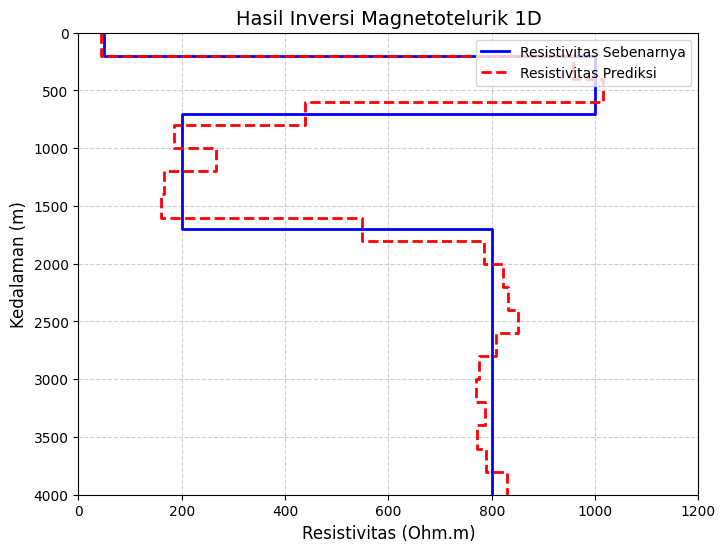

In [ ]:
plot_model_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, total_depth)

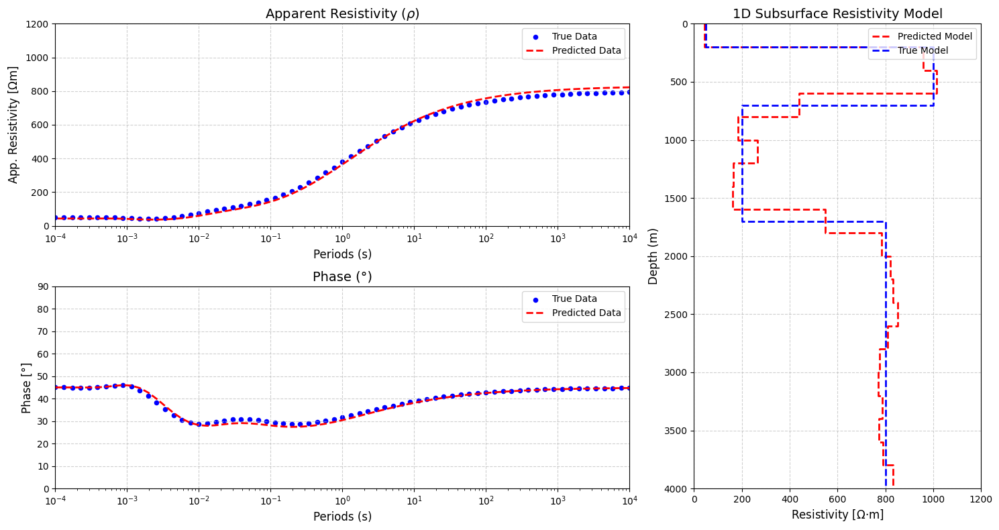

In [ ]:
plot_MT_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, period, fasa, resistivitas_semu, fasa_predict,resistivitas_semu_predict, total_depth)

### Error

In [ ]:
measure_MSE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MSE Resistivitas Semu: 290.78
MSE Fasa: 0.79


In [ ]:
measure_MAPE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MAPE resistivitas semu: 7.64%
MAPE fasa: 2.01%


In [ ]:
measure_RMSE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

RMSE Resistivitas Semu: 17.05
RMSE Fasa: 0.89


[Interpolated] MSE model resistivitas: 14780.6606
[Interpolated] RMSE model resistivitas: 121.5757
[Interpolated] MAPE model resistivitas: 16.03%


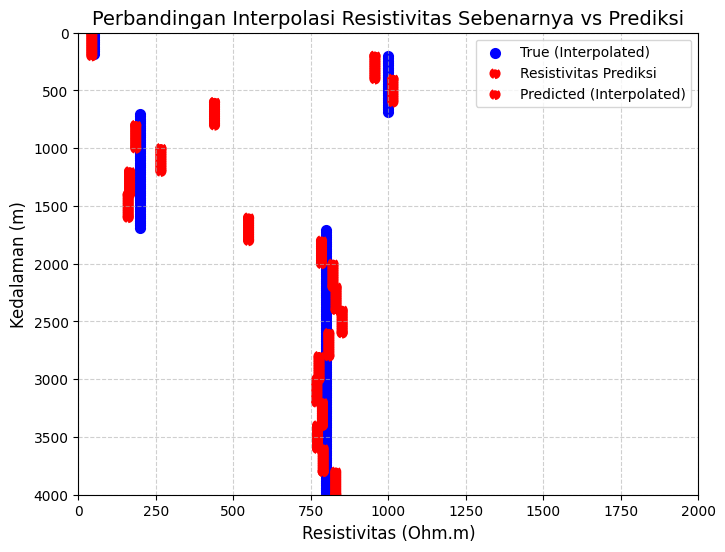

In [ ]:
measure_interpolated_resistivities(resis_true,ketebalan_true,resis_predict,ketebalan_predict,total_depth)

## Model Bumi 4 Lapis IV

### Prediksi

In [ ]:


# Forward modelling untuk data input
resis_true= np.array([ 200, 50, 800, 1000])
ketebalan_true = np.array([200, 500, 1000])
period = 1/frequencies
resistivitas_semu, fasa = forward_modelling(resis_true, ketebalan_true, frequencies)

resistivitas_semu = np.array([resistivitas_semu])
fasa = np.array([fasa])

#Reshape sebelum normalisasi
resistivitas_semu = resistivitas_semu[0].reshape(1, X_input_res.shape[1]) # Corrected reshape syntax
fasa = fasa.reshape(1, X_input_phase.shape[1])

# Logaritma Data Input
resistivitas_semu_log = np.log10(resistivitas_semu)
fasa_log = np.log10(fasa)

# Normalisasi data input
resistivitas_semu_normalized = input_res_scaler.transform(resistivitas_semu_log)
fasa_normalized = input_phase_scaler.transform(fasa_log)

# Reshape jika perlu (misalnya, untuk input CNN)
resistivitas_semu_normalized = resistivitas_semu_normalized.reshape(1, X_input_res.shape[1], 1)
fasa_normalized = fasa_normalized.reshape(1, X_input_phase.shape[1], 1)

# Prediksi
predictions = model.predict([resistivitas_semu_normalized, fasa_normalized])

# Denormalisasi hasil prediksi, apply to the predictions, not hasil
predictions_denormalized = output_model_scaler.inverse_transform(predictions)
predictions_denormalized = np.power(10, predictions_denormalized)

# Accessing the values from predictions_denormalized
resis_predict = predictions_denormalized[0] #
ketebalan_predict = np.full(jumlah_layer-1,layer_thickness)

#Forward Modelling from prediction model
resistivitas_semu_predict, fasa_predict = forward_modelling(resis_predict,ketebalan_predict,frequencies)
resistivitas_semu_predict = np.array([resistivitas_semu_predict])
fasa_predict = np.array([fasa_predict])


#print(hasil) #No need to print hasil as it's not used

print("Nilai Resis_True", resis_true)
print("Nilai ketebalan_True",ketebalan_true)
print("Nilai resis_predict",resis_predict)
print("Nilai ketebalan_predict",ketebalan_predict)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
Nilai Resis_True [ 200   50  800 1000]
Nilai ketebalan_True [ 200  500 1000]
Nilai resis_predict [ 193.12123    51.04982    51.920753   98.557846  966.8502    921.0753
  896.1145    898.7917    884.00604   936.3247    946.18695   971.7383
 1009.06055   978.1642    965.8131    975.32764  1002.14825  1008.3827
  976.4924    972.29645 ]
Nilai ketebalan_predict [200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200.
 200. 200. 200. 200. 200.]


### Grafik

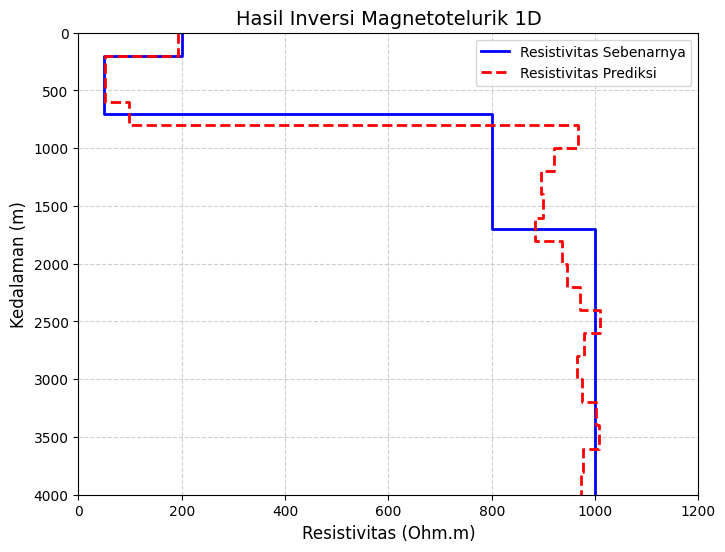

In [ ]:
plot_model_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, total_depth)

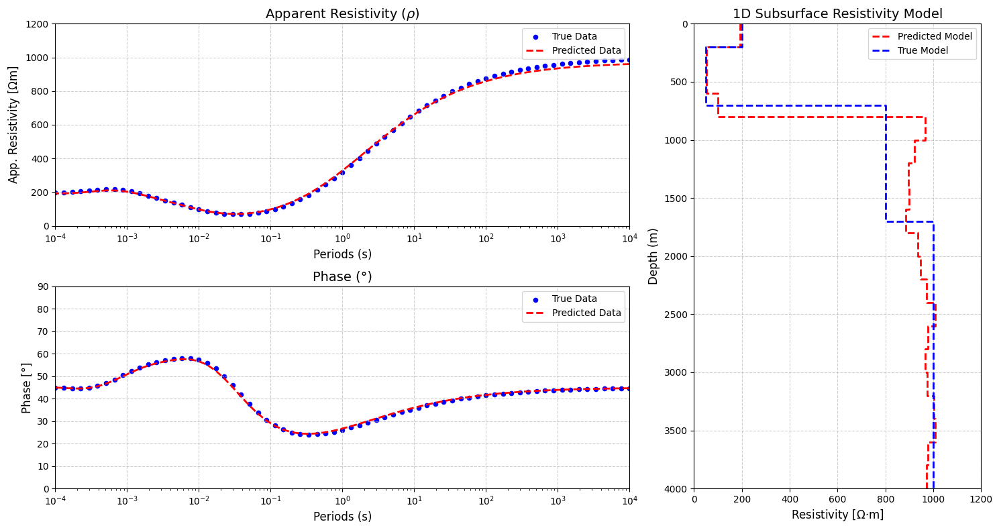

In [ ]:
plot_MT_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, period, fasa, resistivitas_semu, fasa_predict,resistivitas_semu_predict, total_depth)

### Error

In [ ]:
measure_MSE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MSE Resistivitas Semu: 181.94
MSE Fasa: 0.20


In [ ]:
measure_MAPE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MAPE resistivitas semu: 2.51%
MAPE fasa: 0.91%


In [ ]:
measure_RMSE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

RMSE Resistivitas Semu: 13.49
RMSE Fasa: 0.44


[Interpolated] MSE model resistivitas: 16523.6938
[Interpolated] RMSE model resistivitas: 128.5445
[Interpolated] MAPE model resistivitas: 10.15%


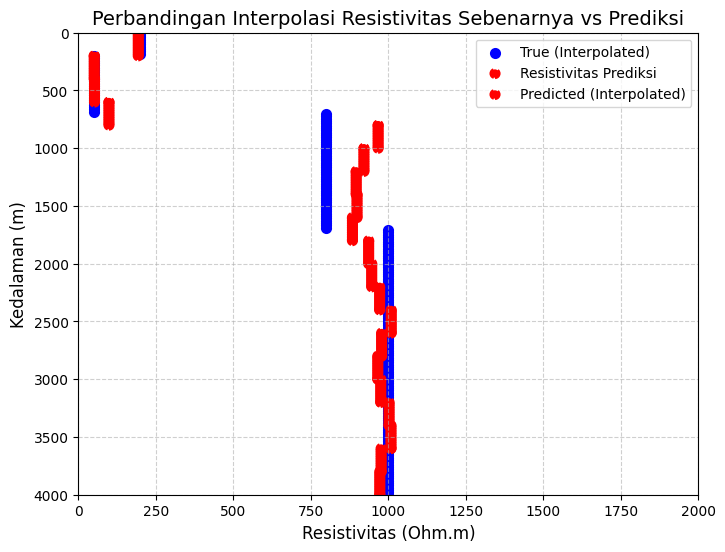

In [ ]:





measure_interpolated_resistivities(resis_true,ketebalan_true,resis_predict,ketebalan_predict,total_depth)

## Model Bumi 4 Lapis V

### Prediksi

In [ ]:


# Forward modelling untuk data input
resis_true= np.array([ 800, 50, 200, 1000])
ketebalan_true = np.array([200, 500, 1000])
period = 1/frequencies
resistivitas_semu, fasa = forward_modelling(resis_true, ketebalan_true, frequencies)

resistivitas_semu = np.array([resistivitas_semu])
fasa = np.array([fasa])

#Reshape sebelum normalisasi
resistivitas_semu = resistivitas_semu[0].reshape(1, X_input_res.shape[1]) # Corrected reshape syntax
fasa = fasa.reshape(1, X_input_phase.shape[1])

# Logaritma Data Input
resistivitas_semu_log = np.log10(resistivitas_semu)
fasa_log = np.log10(fasa)

# Normalisasi data input
resistivitas_semu_normalized = input_res_scaler.transform(resistivitas_semu_log)
fasa_normalized = input_phase_scaler.transform(fasa_log)

# Reshape jika perlu (misalnya, untuk input CNN)
resistivitas_semu_normalized = resistivitas_semu_normalized.reshape(1, X_input_res.shape[1], 1)
fasa_normalized = fasa_normalized.reshape(1, X_input_phase.shape[1], 1)

# Prediksi
predictions = model.predict([resistivitas_semu_normalized, fasa_normalized])

# Denormalisasi hasil prediksi, apply to the predictions, not hasil
predictions_denormalized = output_model_scaler.inverse_transform(predictions)
predictions_denormalized = np.power(10, predictions_denormalized)

# Accessing the values from predictions_denormalized
resis_predict = predictions_denormalized[0] #
ketebalan_predict = np.full(jumlah_layer-1,layer_thickness)

#Forward Modelling from prediction model
resistivitas_semu_predict, fasa_predict = forward_modelling(resis_predict,ketebalan_predict,frequencies)
resistivitas_semu_predict = np.array([resistivitas_semu_predict])
fasa_predict = np.array([fasa_predict])


#print(hasil) #No need to print hasil as it's not used

print("Nilai Resis_True", resis_true)
print("Nilai ketebalan_True",ketebalan_true)
print("Nilai resis_predict",resis_predict)
print("Nilai ketebalan_predict",ketebalan_predict)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
Nilai Resis_True [ 800   50  200 1000]
Nilai ketebalan_True [ 200  500 1000]
Nilai resis_predict [797.11847   55.632572  47.055668  58.258545 404.20724  221.79929
 191.54588  238.15459  515.8452   716.1151   893.9942   914.9898
 979.15436  955.8654   968.8932   943.6948   963.62476  955.1452
 946.32825  964.936   ]
Nilai ketebalan_predict [200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200.
 200. 200. 200. 200. 200.]


### Grafik

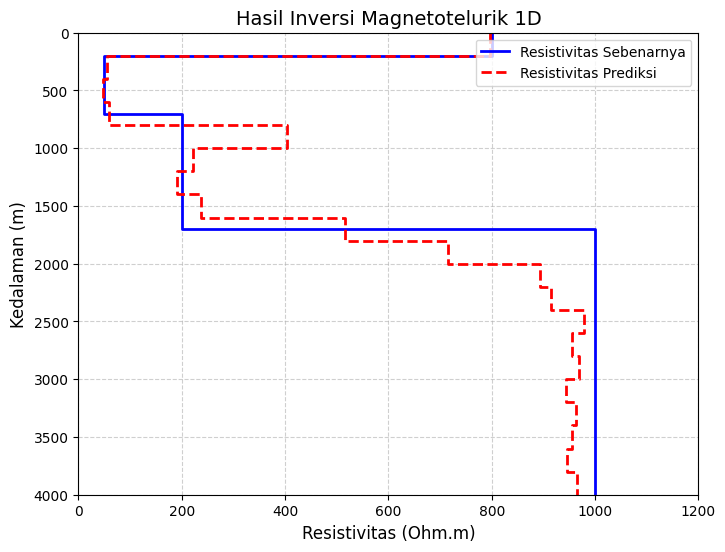

In [ ]:
plot_model_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, total_depth)

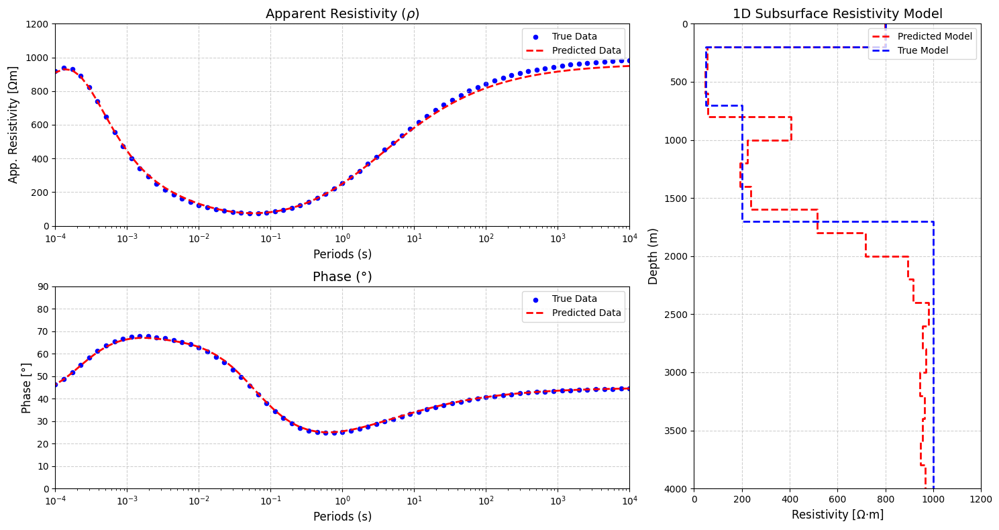

In [ ]:
plot_MT_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, period, fasa, resistivitas_semu, fasa_predict,resistivitas_semu_predict, total_depth)

### Error

In [ ]:
measure_MSE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MSE Resistivitas Semu: 328.23
MSE Fasa: 0.16


In [ ]:
measure_MAPE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MAPE resistivitas semu: 2.34%
MAPE fasa: 0.67%


In [ ]:
measure_RMSE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

RMSE Resistivitas Semu: 18.12
RMSE Fasa: 0.39


[Interpolated] MSE model resistivitas: 16696.6677
[Interpolated] RMSE model resistivitas: 129.2156
[Interpolated] MAPE model resistivitas: 19.02%


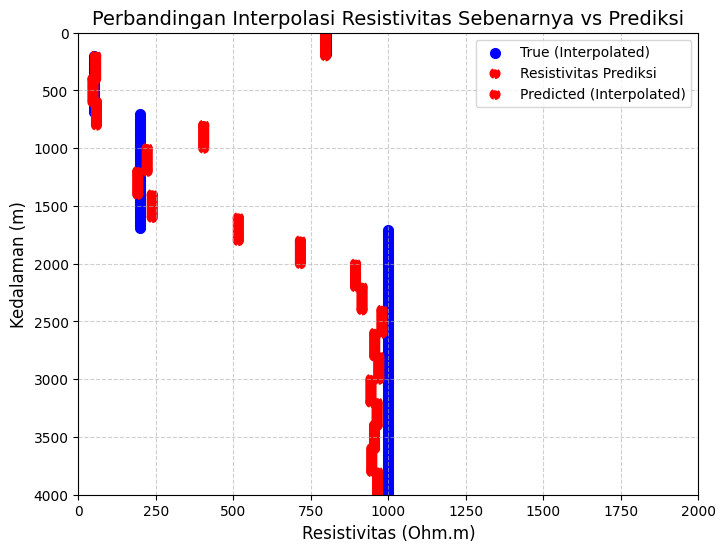

In [ ]:
measure_interpolated_resistivities(resis_true,ketebalan_true,resis_predict,ketebalan_predict,total_depth)

## Model Bumi 4 Lapis VI

### Prediksi

In [ ]:


# Forward modelling untuk data input
resis_true= np.array([1000, 50, 200, 800])
ketebalan_true = np.array([200, 500, 1000])
period = 1/frequencies
resistivitas_semu, fasa = forward_modelling(resis_true, ketebalan_true, frequencies)

resistivitas_semu = np.array([resistivitas_semu])
fasa = np.array([fasa])

#Reshape sebelum normalisasi
resistivitas_semu = resistivitas_semu[0].reshape(1, X_input_res.shape[1]) # Corrected reshape syntax
fasa = fasa.reshape(1, X_input_phase.shape[1])

# Logaritma Data Input
resistivitas_semu_log = np.log10(resistivitas_semu)
fasa_log = np.log10(fasa)

# Normalisasi data input
resistivitas_semu_normalized = input_res_scaler.transform(resistivitas_semu_log)
fasa_normalized = input_phase_scaler.transform(fasa_log)

# Reshape jika perlu (misalnya, untuk input CNN)
resistivitas_semu_normalized = resistivitas_semu_normalized.reshape(1, X_input_res.shape[1], 1)
fasa_normalized = fasa_normalized.reshape(1, X_input_phase.shape[1], 1)

# Prediksi
predictions = model.predict([resistivitas_semu_normalized, fasa_normalized])

# Denormalisasi hasil prediksi, apply to the predictions, not hasil
predictions_denormalized = output_model_scaler.inverse_transform(predictions)
predictions_denormalized = np.power(10, predictions_denormalized)

# Accessing the values from predictions_denormalized
resis_predict = predictions_denormalized[0] #
ketebalan_predict = np.full(jumlah_layer-1,layer_thickness)

#Forward Modelling from prediction model
resistivitas_semu_predict, fasa_predict = forward_modelling(resis_predict,ketebalan_predict,frequencies)
resistivitas_semu_predict = np.array([resistivitas_semu_predict])
fasa_predict = np.array([fasa_predict])


#print(hasil) #No need to print hasil as it's not used

print("Nilai Resis_True", resis_true)
print("Nilai ketebalan_True",ketebalan_true)
print("Nilai resis_predict",resis_predict)
print("Nilai ketebalan_predict",ketebalan_predict)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
Nilai Resis_True [1000   50  200  800]
Nilai ketebalan_True [ 200  500 1000]
Nilai resis_predict [949.92487   56.819485  47.760742  60.163105 393.9885   226.66718
 196.88011  230.5782   405.08472  579.0026   833.69495  869.28894
 922.232    890.17334  889.8391   835.769    816.1758   764.6176
 768.261    795.53723 ]
Nilai ketebalan_predict [200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200.
 200. 200. 200. 200. 200.]


### Grafik

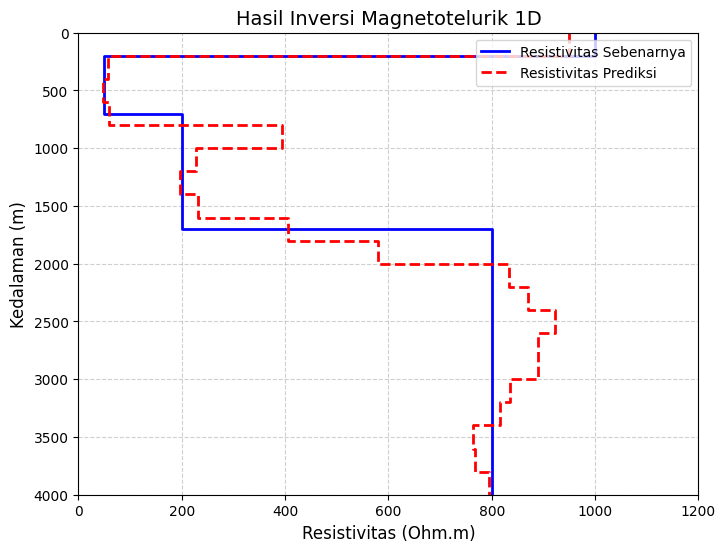

In [ ]:
plot_model_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, total_depth)

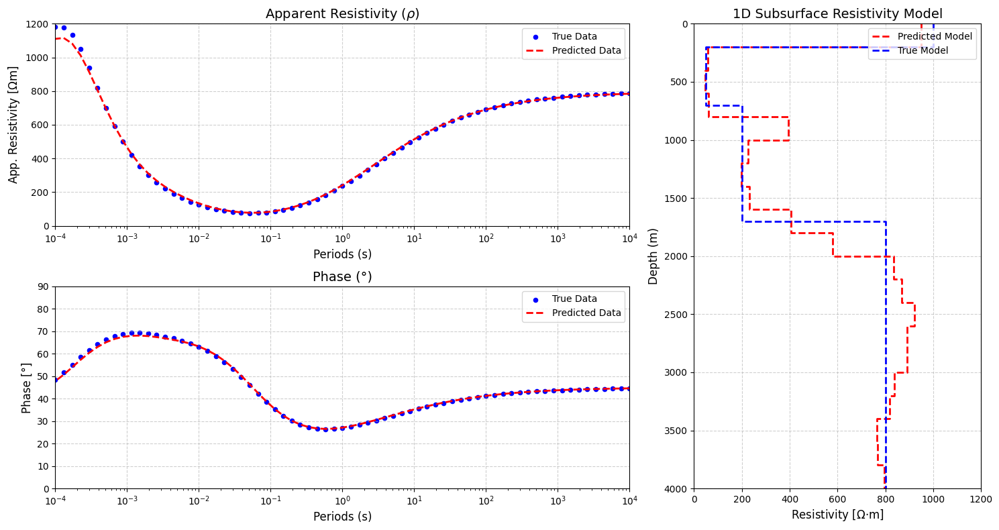

In [ ]:
plot_MT_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, period, fasa, resistivitas_semu, fasa_predict,resistivitas_semu_predict, total_depth)

### Error

In [ ]:
measure_MSE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MSE Resistivitas Semu: 225.74
MSE Fasa: 0.30


In [ ]:
measure_MAPE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MAPE resistivitas semu: 2.01%
MAPE fasa: 0.71%


In [ ]:
measure_RMSE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

RMSE Resistivitas Semu: 15.02
RMSE Fasa: 0.55


[Interpolated] MSE model resistivitas: 12021.1791
[Interpolated] RMSE model resistivitas: 109.6411
[Interpolated] MAPE model resistivitas: 18.25%


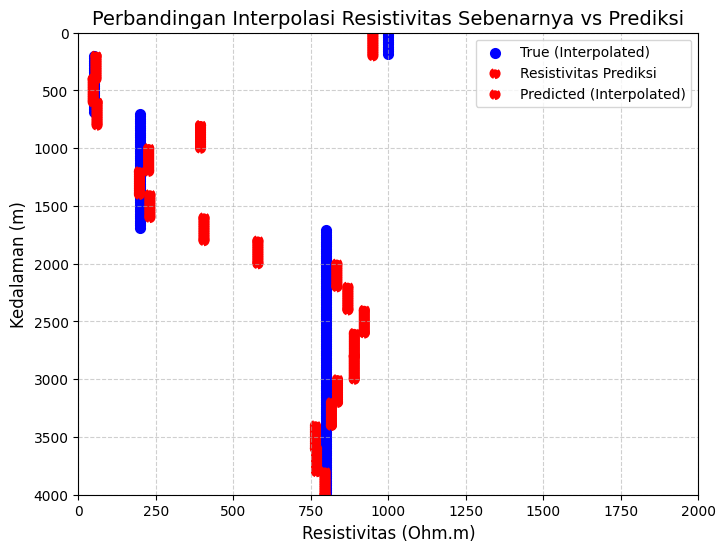

In [ ]:
measure_interpolated_resistivities(resis_true,ketebalan_true,resis_predict,ketebalan_predict,total_depth)

#Uji Coba Data Lapangan

##Aceh01

In [ ]:
frequency = np.loadtxt("/content/drive/MyDrive/Tugas Akhir/Data Lapangan/Aceh 01/Frequency_Aceh01.txt")
RHOXY = np.loadtxt("/content/drive/MyDrive/Tugas Akhir/Data Lapangan/Aceh 01/RhoXY_Aceh01.txt")
RHOYX = np.loadtxt("/content/drive/MyDrive/Tugas Akhir/Data Lapangan/Aceh 01/RhoYX_Aceh01.txt")
phaseXY = np.loadtxt("/content/drive/MyDrive/Tugas Akhir/Data Lapangan/Aceh 01/PHSXY_Aceh01.txt")
phaseYX = np.loadtxt("/content/drive/MyDrive/Tugas Akhir/Data Lapangan/Aceh 01/PHSYX_Aceh01.txt")

In [ ]:
frequency = frequency.flatten()
RHOXY = RHOXY.flatten()
RHOYX = RHOYX.flatten()
phaseXY = phaseXY.flatten()
phaseYX = phaseYX.flatten()+180

In [ ]:
frequency.shape, RHOXY.shape, RHOYX.shape, phaseXY.shape, phaseYX.shape

((48,), (48,), (48,), (48,), (48,))

In [ ]:

def hitung_rho_phi_avg(rhoxy, phixy_deg, rhoyx, phiyx_deg):
    # Ubah derajat ke radian (np.deg2rad juga bisa digunakan)
    phixy = np.radians(phixy_deg)
    phiyx = np.radians(phiyx_deg)

    # Hitung rho_avg (sesuai persamaan 3a)
    rho_avg = 0.25 * (rhoxy + rhoyx + 2 * np.sqrt(rhoxy * rhoyx) * np.cos(phixy - phiyx))

    # Hitung phi_avg (sesuai persamaan 3b)
    sqrt_rhoxy = np.sqrt(rhoxy)
    sqrt_rhoyx = np.sqrt(rhoyx)

    num = sqrt_rhoxy * np.sin(phixy) + sqrt_rhoyx * np.sin(phiyx)
    den = sqrt_rhoxy * np.cos(phixy) + sqrt_rhoyx * np.cos(phiyx)

    phi_avg = np.degrees(np.arctan2(num, den))  # np.arctan2 lebih baik untuk array

    return rho_avg, phi_avg

In [ ]:
rho_avg, phi_avg = hitung_rho_phi_avg(RHOXY, phaseXY, RHOYX, phaseYX)

In [ ]:
import numpy as np
from scipy.interpolate import interp1d


rho = rho_avg.flatten()
phi = phi_avg.flatten()

# Buat sumbu index lama dan baru
rho_old = np.linspace(0, 1, len(rho))     # 48 titik
rho_new = np.linspace(0, 1, 69)           # 69 titik target
phi_old = np.linspace(0, 1, len(phi))
phi_new = np.linspace(0, 1, 69)

# Interpolasi (coba linear atau cubic)
interp_func = interp1d(rho_old, rho, kind='cubic')
rho_interp = interp_func(rho_new)

interp_func = interp1d(phi_old, phi, kind='cubic')
phase_interp = interp_func(phi_new)

In [ ]:


resistivitas_semu = np.array([rho_interp])
fasa = np.array([phase_interp])

#Reshape sebelum Logaritma
resistivitas_semu = resistivitas_semu[0].reshape(1, X_input_res.shape[1]) # Corrected reshape syntax
fasa = fasa.reshape(1, X_input_phase.shape[1])

#Logaritma data input
resistivitas_semu_log = np.log10(resistivitas_semu)
fasa_log = np.log10(fasa)

# Normalisasi data input
resistivitas_semu_normalized = input_res_scaler.transform(resistivitas_semu_log)
fasa_normalized = input_phase_scaler.transform(fasa_log)

# Reshape jika perlu (misalnya, untuk input CNN)
resistivitas_semu_normalized = resistivitas_semu_normalized.reshape(1, X_input_res.shape[1], 1)
fasa_normalized = fasa_normalized.reshape(1, X_input_phase.shape[1], 1)

# Prediksi
predictions = model.predict([resistivitas_semu_normalized, fasa_normalized])

# Denormalisasi hasil prediksi, apply to the predictions, not hasil
predictions_denormalized = output_model_scaler.inverse_transform(predictions)

# Delogaritmik hasil prediksi
predictions_denormalized = np.power(10, predictions_denormalized)

# Accessing the values from predictions_denormalized
resis_predict = predictions_denormalized[0] #
ketebalan_predict = np.full(jumlah_layer-1,layer_thickness)

#Forward Modelling from prediction model
resistivitas_semu_predict, fasa_predict = forward_modelling(resis_predict,ketebalan_predict,frequencies)
resistivitas_semu_predict = np.array([resistivitas_semu_predict])
fasa_predict = np.array([fasa_predict])


#print(hasil) #No need to print hasil as it's not used


print("Nilai resis_predict",resis_predict)
print("Nilai ketebalan_predict",ketebalan_predict)

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 692ms/step
Nilai resis_predict [  79.38613  1141.182       7.780364 6668.71      360.64886   506.73184
 1540.6698    102.924866  289.85266   517.7535    517.8285    357.31186
  139.70201   162.56682   281.67206   549.8206    480.86356     9.275697
  402.04553   936.2877  ]
Nilai ketebalan_predict [200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200.
 200. 200. 200. 200. 200.]


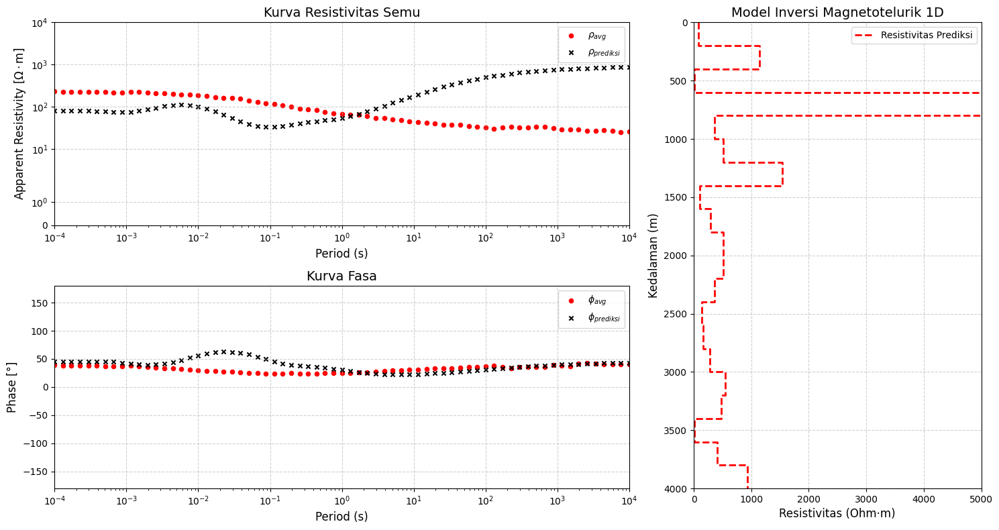

In [ ]:
def formating_result(resis, ketebalan, total_depth):
  depth = np.concatenate(([0], np.cumsum(ketebalan), [total_depth]))
  depth_plot = np.repeat(depth, 2)[1:-1]
  resis_plot = np.repeat(resis, 2)
  return depth_plot, resis_plot

depth_pred_plot, resis_pred_plot = formating_result(resis_predict, ketebalan_predict, total_depth)
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

# Buat figure dan GridSpec
fig = plt.figure(figsize=(15, 8))
gs = gridspec.GridSpec(2, 2, width_ratios=[2, 1])  # 2 baris, 2 kolom, kolom kanan lebih kecil

# Subplot 1: Resistivitas Semu
ax1 = fig.add_subplot(gs[0, 0])
ax1.scatter(1/frequencies, rho_interp, color='red', label=r'$\rho_{avg}$', s=20)
ax1.scatter(1/frequencies, resistivitas_semu_predict[0], color='black',marker ='x', label=r'$\rho_{prediksi}$', s=20)
ax1.set_ylabel(r'Apparent Resistivity [$\Omega\cdot$m]', fontsize=12)
ax1.set_xlabel('Period (s)', fontsize=12)
ax1.set_xscale('log')
ax1.set_yscale('symlog')
ax1.set_ylim([0, 10000])
ax1.set_xlim([1e-4, 1e4])
ax1.grid(True, linestyle='--', alpha=0.6)
ax1.set_title('Kurva Resistivitas Semu', fontsize=14)
ax1.legend()

# Subplot 2: Phase
ax2 = fig.add_subplot(gs[1, 0])
ax2.scatter(1/frequencies, phase_interp, color='red', label=r'$\phi_{avg}$', s=20)
ax2.scatter(1/frequencies, fasa_predict[0], color='black', marker = 'x', label=r'$\phi_{prediksi}$', s=20)
ax2.set_ylabel('Phase [°]', fontsize=12)
ax2.set_xlabel('Period (s)', fontsize=12)
ax2.set_xscale('log')
ax2.set_ylim([-180, 180])
ax2.set_xlim([1e-4, 1e4])
ax2.grid(True, linestyle='--', alpha=0.6)
ax2.set_title('Kurva Fasa', fontsize=14)
ax2.legend()

#Jika ingin mengaktifkan subplot 3, tinggal uncomment
ax3 = fig.add_subplot(gs[:, 1])
ax3.plot(resis_pred_plot, depth_pred_plot, label='Resistivitas Prediksi', color='red', linestyle='--', linewidth=2)
ax3.set_xlabel('Resistivitas (Ohm·m)', fontsize=12)
ax3.set_ylabel('Kedalaman (m)', fontsize=12)
ax3.set_title('Model Inversi Magnetotelurik 1D', fontsize=14)
ax3.legend(loc='upper right')
ax3.grid(True, linestyle='--', alpha=0.6)
ax3.set_xlim(0, 5000)
ax3.set_ylim(4000, 0)  # Dari permukaan ke bawah

plt.tight_layout()
plt.show()


##Aceh02

In [ ]:
frequency = np.loadtxt("/content/drive/MyDrive/Tugas Akhir/Data Lapangan/Aceh 02/Frequency_Aceh02.txt")
RHOXY = np.loadtxt("/content/drive/MyDrive/Tugas Akhir/Data Lapangan/Aceh 02/RhoXY_Aceh02.txt")
RHOYX = np.loadtxt("/content/drive/MyDrive/Tugas Akhir/Data Lapangan/Aceh 02/RhoYX_Aceh02.txt")
phaseXY = np.loadtxt("/content/drive/MyDrive/Tugas Akhir/Data Lapangan/Aceh 02/PHSXY_Aceh02.txt")
phaseYX = np.loadtxt("/content/drive/MyDrive/Tugas Akhir/Data Lapangan/Aceh 02/PHSYX_Aceh02.txt")

In [ ]:
frequency = frequency.flatten()
RHOXY = RHOXY.flatten()
RHOYX = RHOYX.flatten()
phaseXY = phaseXY.flatten()
phaseYX = phaseYX.flatten()+180

In [ ]:
rho_avg, phi_avg = hitung_rho_phi_avg(RHOXY, phaseXY, RHOYX, phaseYX)

In [ ]:
import numpy as np
from scipy.interpolate import interp1d


rho = rho_avg.flatten()
phi = phi_avg.flatten()

# Buat sumbu index lama dan baru
rho_old = np.linspace(0, 1, len(rho))     # 48 titik
rho_new = np.linspace(0, 1, 69)           # 69 titik target
phi_old = np.linspace(0, 1, len(phi))
phi_new = np.linspace(0, 1, 69)

# Interpolasi (coba linear atau cubic)
interp_func = interp1d(rho_old, rho, kind='cubic')
rho_interp = interp_func(rho_new)

interp_func = interp1d(phi_old, phi, kind='cubic')
phase_interp = interp_func(phi_new)

In [ ]:


resistivitas_semu = np.array([rho_interp])
fasa = np.array([phase_interp])

#Reshape sebelum Logaritma
resistivitas_semu = resistivitas_semu[0].reshape(1, X_input_res.shape[1]) # Corrected reshape syntax
fasa = fasa.reshape(1, X_input_phase.shape[1])

#Logaritma data input
resistivitas_semu_log = np.log10(resistivitas_semu)
fasa_log = np.log10(fasa)

# Normalisasi data input
resistivitas_semu_normalized = input_res_scaler.transform(resistivitas_semu_log)
fasa_normalized = input_phase_scaler.transform(fasa_log)

# Reshape jika perlu (misalnya, untuk input CNN)
resistivitas_semu_normalized = resistivitas_semu_normalized.reshape(1, X_input_res.shape[1], 1)
fasa_normalized = fasa_normalized.reshape(1, X_input_phase.shape[1], 1)

# Prediksi
predictions = model.predict([resistivitas_semu_normalized, fasa_normalized])

# Denormalisasi hasil prediksi, apply to the predictions, not hasil
predictions_denormalized = output_model_scaler.inverse_transform(predictions)

# Delogaritmik hasil prediksi
predictions_denormalized = np.power(10, predictions_denormalized)

# Accessing the values from predictions_denormalized
resis_predict = predictions_denormalized[0] #
ketebalan_predict = np.full(jumlah_layer-1,layer_thickness)

#Forward Modelling from prediction model
resistivitas_semu_predict, fasa_predict = forward_modelling(resis_predict,ketebalan_predict,frequencies)
resistivitas_semu_predict = np.array([resistivitas_semu_predict])
fasa_predict = np.array([fasa_predict])


#print(hasil) #No need to print hasil as it's not used


print("Nilai resis_predict",resis_predict)
print("Nilai ketebalan_predict",ketebalan_predict)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
Nilai resis_predict [8.6236313e+01 2.3207877e+02 3.2524230e+00 1.0221134e+03 1.0243828e+03
 9.1678979e+02 2.3143879e+03 3.1397363e+02 2.3229546e+02 4.6764767e+02
 2.1967960e+02 2.6267273e+02 3.3293787e+02 5.7135126e+02 4.8101456e+02
 5.1909393e+02 3.5218710e+02 3.8887125e+02 3.3146495e-01 1.3703313e+03]
Nilai ketebalan_predict [200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200.
 200. 200. 200. 200. 200.]


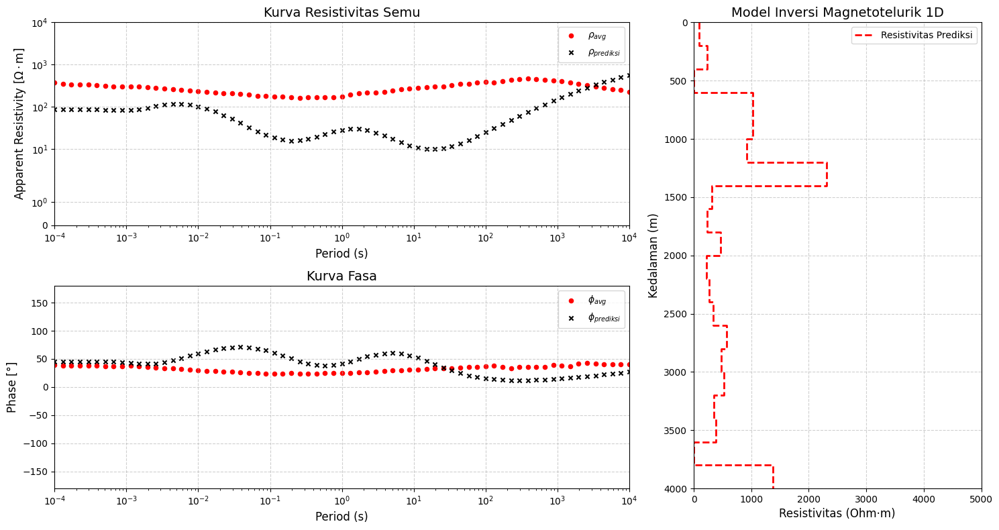

In [ ]:
def formating_result(resis, ketebalan, total_depth):
  depth = np.concatenate(([0], np.cumsum(ketebalan), [total_depth]))
  depth_plot = np.repeat(depth, 2)[1:-1]
  resis_plot = np.repeat(resis, 2)
  return depth_plot, resis_plot

depth_pred_plot, resis_pred_plot = formating_result(resis_predict, ketebalan_predict, total_depth)
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

# Buat figure dan GridSpec
fig = plt.figure(figsize=(15, 8))
gs = gridspec.GridSpec(2, 2, width_ratios=[2, 1])  # 2 baris, 2 kolom, kolom kanan lebih kecil

# Subplot 1: Resistivitas Semu
ax1 = fig.add_subplot(gs[0, 0])
ax1.scatter(1/frequencies, rho_interp, color='red', label=r'$\rho_{avg}$', s=20)
ax1.scatter(1/frequencies, resistivitas_semu_predict[0], color='black',marker ='x', label=r'$\rho_{prediksi}$', s=20)
ax1.set_ylabel(r'Apparent Resistivity [$\Omega\cdot$m]', fontsize=12)
ax1.set_xlabel('Period (s)', fontsize=12)
ax1.set_xscale('log')
ax1.set_yscale('symlog')
ax1.set_ylim([0, 10000])
ax1.set_xlim([1e-4, 1e4])
ax1.grid(True, linestyle='--', alpha=0.6)
ax1.set_title('Kurva Resistivitas Semu', fontsize=14)
ax1.legend()

# Subplot 2: Phase
ax2 = fig.add_subplot(gs[1, 0])
ax2.scatter(1/frequencies, phi_interp, color='red', label=r'$\phi_{avg}$', s=20)
ax2.scatter(1/frequencies, fasa_predict[0], color='black', marker = 'x', label=r'$\phi_{prediksi}$', s=20)
ax2.set_ylabel('Phase [°]', fontsize=12)
ax2.set_xlabel('Period (s)', fontsize=12)
ax2.set_xscale('log')
ax2.set_ylim([-180, 180])
ax2.set_xlim([1e-4, 1e4])
ax2.grid(True, linestyle='--', alpha=0.6)
ax2.set_title('Kurva Fasa', fontsize=14)
ax2.legend()

#Jika ingin mengaktifkan subplot 3, tinggal uncomment
ax3 = fig.add_subplot(gs[:, 1])
ax3.plot(resis_pred_plot, depth_pred_plot, label='Resistivitas Prediksi', color='red', linestyle='--', linewidth=2)
ax3.set_xlabel('Resistivitas (Ohm·m)', fontsize=12)
ax3.set_ylabel('Kedalaman (m)', fontsize=12)
ax3.set_title('Model Inversi Magnetotelurik 1D', fontsize=14)
ax3.legend(loc='upper right')
ax3.grid(True, linestyle='--', alpha=0.6)
ax3.set_xlim(0, 5000)
ax3.set_ylim(4000, 0)  # Dari permukaan ke bawah

plt.tight_layout()
plt.show()


##Aceh04

In [ ]:
frequency = np.loadtxt("/content/drive/MyDrive/Tugas Akhir/Data Lapangan/Aceh 04/Frequency_Aceh04.txt")
RHOXY = np.loadtxt("/content/drive/MyDrive/Tugas Akhir/Data Lapangan/Aceh 04/RhoXY_Aceh04.txt")
RHOYX = np.loadtxt("/content/drive/MyDrive/Tugas Akhir/Data Lapangan/Aceh 04/RhoYX_Aceh04.txt")
phaseXY = np.loadtxt("/content/drive/MyDrive/Tugas Akhir/Data Lapangan/Aceh 04/PHSXY_Aceh04.txt")
phaseYX = np.loadtxt("/content/drive/MyDrive/Tugas Akhir/Data Lapangan/Aceh 04/PHSYX_Aceh04.txt")

In [ ]:
frequency = frequency.flatten()
RHOXY = RHOXY.flatten()
RHOYX = RHOYX.flatten()
phaseXY = phaseXY.flatten()
phaseYX = phaseYX.flatten()+180

In [ ]:
rho_avg, phi_avg = hitung_rho_phi_avg(RHOXY, phaseXY, RHOYX, phaseYX)

In [ ]:
import numpy as np
from scipy import interpolate

# Misalkan data asli Anda (48 titik)
frequency_original = frequency  # Array dengan shape (48,)
rho_xy_original = rho_avg.flatten()  # Array dengan shape (48,)
phase_xy_original = phi_avg.flatten()  # Array dengan shape (48,)

# Pastikan frekuensi dalam skala log (karena biasanya MT menggunakan log-freq)
log_freq_original = np.log10(frequency_original)

# Buat frekuensi target (69 titik, dalam skala log)
log_freq_target = np.linspace(log_freq_original.min(), log_freq_original.max(), 69)
frequency_target = 10**log_freq_target  # Kembalikan ke skala linier jika diperlukan

# Interpolasi resistivitas dan fasa dalam skala log (karena ρ dan φ biasanya di-log)
log_rho_xy_original = np.log10(rho_xy_original)
log_phase_xy_original = np.log10(phase_xy_original)

# Buat fungsi interpolasi (bisa linear, spline, dll)
interp_rho = interpolate.interp1d(log_freq_original, log_rho_xy_original, kind='cubic', fill_value='extrapolate')
interp_phase = interpolate.interp1d(log_freq_original, log_phase_xy_original, kind='cubic', fill_value='extrapolate')

# Hitung nilai interpolasi (dalam log)
log_rho_interp = interp_rho(log_freq_target)
log_phase_interp = interp_phase(log_freq_target)

# Kembalikan ke nilai normal (jika diperlukan)
rho_interp = 10**log_rho_interp
phase_interp = 10**log_phase_interp

rho_interp = rho_interp[::-1]
phase_interp = phase_interp[::-1]



In [ ]:


resistivitas_semu = np.array([rho_interp])
fasa = np.array([phase_interp])

#Reshape sebelum Logaritma
resistivitas_semu = resistivitas_semu[0].reshape(1, X_input_res.shape[1]) # Corrected reshape syntax
fasa = fasa.reshape(1, X_input_phase.shape[1])

#Logaritma data input
resistivitas_semu_log = np.log10(resistivitas_semu)
fasa_log = np.log10(fasa)

# Normalisasi data input
resistivitas_semu_normalized = input_res_scaler.transform(resistivitas_semu_log)
fasa_normalized = input_phase_scaler.transform(fasa_log)

# Reshape jika perlu (misalnya, untuk input CNN)
resistivitas_semu_normalized = resistivitas_semu_normalized.reshape(1, X_input_res.shape[1], 1)
fasa_normalized = fasa_normalized.reshape(1, X_input_phase.shape[1], 1)

# Prediksi
predictions = model.predict([resistivitas_semu_normalized, fasa_normalized])

# Denormalisasi hasil prediksi, apply to the predictions, not hasil
predictions_denormalized = output_model_scaler.inverse_transform(predictions)

# Delogaritmik hasil prediksi
predictions_denormalized = np.power(10, predictions_denormalized)

# Accessing the values from predictions_denormalized
resis_predict = predictions_denormalized[0] #
ketebalan_predict = np.full(jumlah_layer-1,layer_thickness)

#Forward Modelling from prediction model
resistivitas_semu_predict, fasa_predict = forward_modelling(resis_predict,ketebalan_predict,frequency)
resistivitas_semu_predict = np.array([resistivitas_semu_predict])
fasa_predict = np.array([fasa_predict])


#print(hasil) #No need to print hasil as it's not used


print("Nilai resis_predict",resis_predict)
print("Nilai ketebalan_predict",ketebalan_predict)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
Nilai resis_predict [ 914.27026  1616.0848     23.472906 5500.289      87.58116  1141.2484
 1693.875    2747.616    2303.3376     97.12455    89.30073   949.4713
 1603.099    1532.7507   1448.6829   1501.1399   1466.0432   1627.5676
 2009.8782    804.18933 ]
Nilai ketebalan_predict [200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200.
 200. 200. 200. 200. 200.]


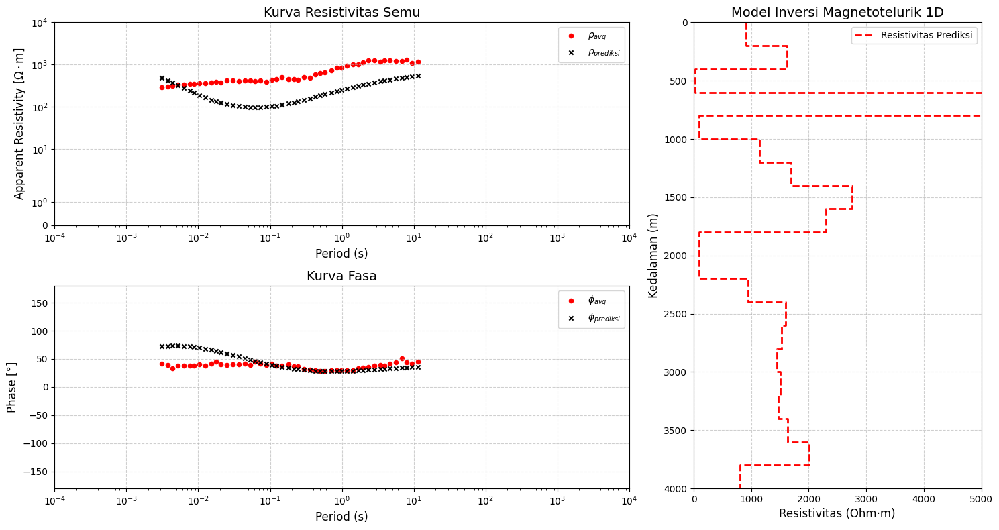

In [ ]:
def formating_result(resis, ketebalan, total_depth):
  depth = np.concatenate(([0], np.cumsum(ketebalan), [total_depth]))
  depth_plot = np.repeat(depth, 2)[1:-1]
  resis_plot = np.repeat(resis, 2)
  return depth_plot, resis_plot

depth_pred_plot, resis_pred_plot = formating_result(resis_predict, ketebalan_predict, total_depth)
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

# Buat figure dan GridSpec
fig = plt.figure(figsize=(15, 8))
gs = gridspec.GridSpec(2, 2, width_ratios=[2, 1])  # 2 baris, 2 kolom, kolom kanan lebih kecil

# Subplot 1: Resistivitas Semu
ax1 = fig.add_subplot(gs[0, 0])
ax1.scatter(1/frequency, rho_avg, color='red', label=r'$\rho_{avg}$', s=20)
ax1.scatter(1/frequency, resistivitas_semu_predict[0], color='black',marker ='x', label=r'$\rho_{prediksi}$', s=20)
ax1.set_ylabel(r'Apparent Resistivity [$\Omega\cdot$m]', fontsize=12)
ax1.set_xlabel('Period (s)', fontsize=12)
ax1.set_xscale('log')
ax1.set_yscale('symlog')
ax1.set_ylim([0, 10000])
ax1.set_xlim([1e-4, 1e4])
ax1.grid(True, linestyle='--', alpha=0.6)
ax1.set_title('Kurva Resistivitas Semu', fontsize=14)
ax1.legend()

# Subplot 2: Phase
ax2 = fig.add_subplot(gs[1, 0])
ax2.scatter(1/frequency, phi_avg, color='red', label=r'$\phi_{avg}$', s=20)
ax2.scatter(1/frequency, fasa_predict[0], color='black', marker = 'x', label=r'$\phi_{prediksi}$', s=20)
ax2.set_ylabel('Phase [°]', fontsize=12)
ax2.set_xlabel('Period (s)', fontsize=12)
ax2.set_xscale('log')
ax2.set_ylim([-180, 180])
ax2.set_xlim([1e-4, 1e4])
ax2.grid(True, linestyle='--', alpha=0.6)
ax2.set_title('Kurva Fasa', fontsize=14)
ax2.legend()

#Jika ingin mengaktifkan subplot 3, tinggal uncomment
ax3 = fig.add_subplot(gs[:, 1])
ax3.plot(resis_pred_plot, depth_pred_plot, label='Resistivitas Prediksi', color='red', linestyle='--', linewidth=2)
ax3.set_xlabel('Resistivitas (Ohm·m)', fontsize=12)
ax3.set_ylabel('Kedalaman (m)', fontsize=12)
ax3.set_title('Model Inversi Magnetotelurik 1D', fontsize=14)
ax3.legend(loc='upper right')
ax3.grid(True, linestyle='--', alpha=0.6)
ax3.set_xlim(0, 5000)
ax3.set_ylim(4000, 0)  # Dari permukaan ke bawah

plt.tight_layout()
plt.show()


##Aceh 05

In [ ]:
frequency = np.loadtxt("/content/drive/MyDrive/Tugas Akhir/Data Lapangan/Aceh 05/Frequency_Aceh05.txt")
RHOXY = np.loadtxt("/content/drive/MyDrive/Tugas Akhir/Data Lapangan/Aceh 05/RhoXY_Aceh05.txt")
RHOYX = np.loadtxt("/content/drive/MyDrive/Tugas Akhir/Data Lapangan/Aceh 05/RhoYX_Aceh05.txt")
phaseXY = np.loadtxt("/content/drive/MyDrive/Tugas Akhir/Data Lapangan/Aceh 05/PHSXY_Aceh05.txt")
phaseYX = np.loadtxt("/content/drive/MyDrive/Tugas Akhir/Data Lapangan/Aceh 05/PHSYX_Aceh05.txt")

In [ ]:
frequency = frequency.flatten()
RHOXY = RHOXY.flatten()
RHOYX = RHOYX.flatten()
phaseXY = phaseXY.flatten()
phaseYX = phaseYX.flatten()+180

In [ ]:
rho_avg, phi_avg = hitung_rho_phi_avg(RHOXY, phaseXY, RHOYX, phaseYX+180)

In [ ]:
import numpy as np
from scipy import interpolate

# Misalkan data asli Anda (48 titik)
frequency_original = frequency  # Array dengan shape (48,)
rho_xy_original = rho_avg.flatten()  # Array dengan shape (48,)
phase_xy_original = phi_avg.flatten()  # Array dengan shape (48,)

# Pastikan frekuensi dalam skala log (karena biasanya MT menggunakan log-freq)
log_freq_original = np.log10(frequency_original)

# Buat frekuensi target (69 titik, dalam skala log)
log_freq_target = np.linspace(log_freq_original.min(), log_freq_original.max(), 69)
frequency_target = 10**log_freq_target  # Kembalikan ke skala linier jika diperlukan

# Interpolasi resistivitas dan fasa dalam skala log (karena ρ dan φ biasanya di-log)
log_rho_xy_original = np.log10(rho_xy_original)
log_phase_xy_original = np.log10(phase_xy_original)

# Buat fungsi interpolasi (bisa linear, spline, dll)
interp_rho = interpolate.interp1d(log_freq_original, log_rho_xy_original, kind='cubic', fill_value='extrapolate')
interp_phase = interpolate.interp1d(log_freq_original, log_phase_xy_original, kind='cubic', fill_value='extrapolate')

# Hitung nilai interpolasi (dalam log)
log_rho_interp = interp_rho(log_freq_target)
log_phase_interp = interp_phase(log_freq_target)

# Kembalikan ke nilai normal (jika diperlukan)
rho_interp = 10**log_rho_interp
phase_interp = 10**log_phase_interp

rho_interp = rho_interp[::-1]
phase_interp = phase_interp[::-1]



/tmp/ipython-input-171-1675638364.py:18: RuntimeWarning: invalid value encountered in log10
  log_phase_xy_original = np.log10(phase_xy_original)


In [ ]:


resistivitas_semu = np.array([rho_interp])
fasa = np.array([phase_interp])

#Reshape sebelum Logaritma
resistivitas_semu = resistivitas_semu[0].reshape(1, X_input_res.shape[1]) # Corrected reshape syntax
fasa = fasa.reshape(1, X_input_phase.shape[1])

#Logaritma data input
resistivitas_semu_log = np.log10(resistivitas_semu)
fasa_log = np.log10(fasa)

# Normalisasi data input
resistivitas_semu_normalized = input_res_scaler.transform(resistivitas_semu_log)
fasa_normalized = input_phase_scaler.transform(fasa_log)

# Reshape jika perlu (misalnya, untuk input CNN)
resistivitas_semu_normalized = resistivitas_semu_normalized.reshape(1, X_input_res.shape[1], 1)
fasa_normalized = fasa_normalized.reshape(1, X_input_phase.shape[1], 1)

# Prediksi
predictions = model.predict([resistivitas_semu_normalized, fasa_normalized])

# Denormalisasi hasil prediksi, apply to the predictions, not hasil
predictions_denormalized = output_model_scaler.inverse_transform(predictions)

# Delogaritmik hasil prediksi
predictions_denormalized = np.power(10, predictions_denormalized)

# Accessing the values from predictions_denormalized
resis_predict = predictions_denormalized[0] #
ketebalan_predict = np.full(jumlah_layer-1,layer_thickness)

#Forward Modelling from prediction model
resistivitas_semu_predict, fasa_predict = forward_modelling(resis_predict,ketebalan_predict,frequency)
resistivitas_semu_predict = np.array([resistivitas_semu_predict])
fasa_predict = np.array([fasa_predict])


#print(hasil) #No need to print hasil as it's not used


print("Nilai resis_predict",resis_predict)
print("Nilai ketebalan_predict",ketebalan_predict)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
Nilai resis_predict [nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan
 nan nan]
Nilai ketebalan_predict [200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200.
 200. 200. 200. 200. 200.]


/tmp/ipython-input-15-4192635194.py:13: RuntimeWarning: invalid value encountered in divide
  kj = cmath.sqrt(1j * w * mu / res_true[j])  # Wave number


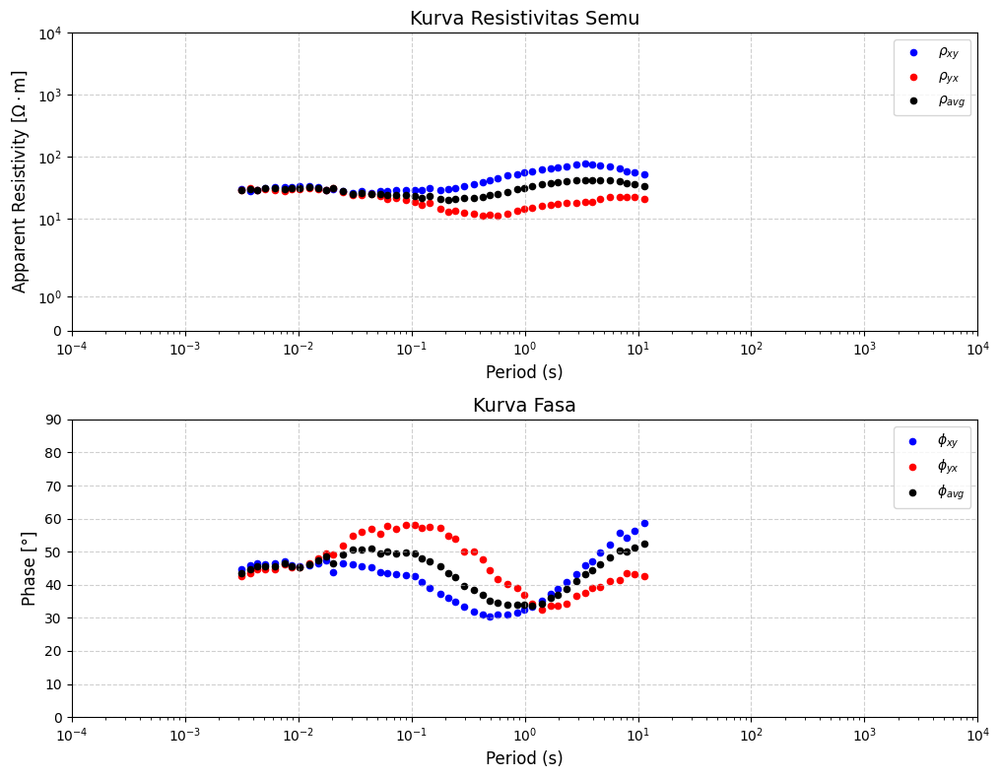

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

# Buat figure dan GridSpec
fig = plt.figure(figsize=(15, 8))
gs = gridspec.GridSpec(2, 2, width_ratios=[2, 1])  # 2 baris, 2 kolom, kolom kanan lebih kecil

# Subplot 1: Resistivitas Semu
ax1 = fig.add_subplot(gs[0, 0])
ax1.scatter(1/frequency, RHOXY, color='blue', label=r'$\rho_{xy}$', s=20)
ax1.scatter(1/frequency, RHOYX, color='red', label=r'$\rho_{yx}$', s=20)
ax1.scatter(1/frequency, rho_avg, color='black', label=r'$\rho_{avg}$', s=20)
ax1.set_ylabel(r'Apparent Resistivity [$\Omega\cdot$m]', fontsize=12)
ax1.set_xlabel('Period (s)', fontsize=12)
ax1.set_xscale('log')
ax1.set_yscale('symlog')
ax1.set_ylim([0, 10000])
ax1.set_xlim([1e-4, 1e4])
ax1.grid(True, linestyle='--', alpha=0.6)
ax1.set_title('Kurva Resistivitas Semu', fontsize=14)
ax1.legend()

# Subplot 2: Phase
ax2 = fig.add_subplot(gs[1, 0])
ax2.scatter(1/frequency, phaseXY, color='blue', label=r'$\phi_{xy}$', s=20)
ax2.scatter(1/frequency, phaseYX+180, color='red', label=r'$\phi_{yx}$', s=20)
ax2.scatter(1/frequency, phi_avg, color='black', label=r'$\phi_{avg}$', s=20)
ax2.set_ylabel('Phase [°]', fontsize=12)
ax2.set_xlabel('Period (s)', fontsize=12)
ax2.set_xscale('log')
ax2.set_ylim([0, 90])
ax2.set_xlim([1e-4, 1e4])
ax2.grid(True, linestyle='--', alpha=0.6)
ax2.set_title('Kurva Fasa', fontsize=14)
ax2.legend()

# Jika ingin mengaktifkan subplot 3, tinggal uncomment
# ax3 = fig.add_subplot(gs[:, 1])
# ax3.plot(resis_pred_plot, depth_pred_plot, label='Resistivitas Prediksi', color='red', linestyle='--', linewidth=2)
# ax3.set_xlabel('Resistivitas (Ohm·m)', fontsize=12)
# ax3.set_ylabel('Kedalaman (m)', fontsize=12)
# ax3.set_title('Model Inversi Magnetotelurik 1D', fontsize=14)
# ax3.legend(loc='upper right')
# ax3.grid(True, linestyle='--', alpha=0.6)
# ax3.set_xlim(0, 1200)
# ax3.set_ylim(4000, 0)  # Dari permukaan ke bawah

plt.tight_layout()
plt.show()


##Aceh 06

In [ ]:
frequency = np.loadtxt("/content/drive/MyDrive/Tugas Akhir/Data Lapangan/Aceh 06/Frequency_Aceh06.txt")
RHOXY = np.loadtxt("/content/drive/MyDrive/Tugas Akhir/Data Lapangan/Aceh 06/RhoXY_Aceh06.txt")
RHOYX = np.loadtxt("/content/drive/MyDrive/Tugas Akhir/Data Lapangan/Aceh 06/RhoYX_Aceh06.txt")
phaseXY = np.loadtxt("/content/drive/MyDrive/Tugas Akhir/Data Lapangan/Aceh 06/PHSXY_Aceh06.txt")
phaseYX = np.loadtxt("/content/drive/MyDrive/Tugas Akhir/Data Lapangan/Aceh 06/PHSYX_Aceh06.txt")

In [ ]:
frequency = frequency.flatten()
RHOXY = RHOXY.flatten()
RHOYX = RHOYX.flatten()
phaseXY = phaseXY.flatten()
phaseYX = phaseYX.flatten()+180

In [ ]:
rho_avg, phi_avg = hitung_rho_phi_avg(RHOXY, phaseXY, RHOYX, phaseYX)

In [ ]:
import numpy as np
from scipy import interpolate

# Misalkan data asli Anda (48 titik)
frequency_original = frequency  # Array dengan shape (48,)
rho_xy_original = rho_avg.flatten()  # Array dengan shape (48,)
phase_xy_original = phi_avg.flatten()  # Array dengan shape (48,)

# Pastikan frekuensi dalam skala log (karena biasanya MT menggunakan log-freq)
log_freq_original = np.log10(frequency_original)

# Buat frekuensi target (69 titik, dalam skala log)
log_freq_target = np.linspace(log_freq_original.min(), log_freq_original.max(), 69)
frequency_target = 10**log_freq_target  # Kembalikan ke skala linier jika diperlukan

# Interpolasi resistivitas dan fasa dalam skala log (karena ρ dan φ biasanya di-log)
log_rho_xy_original = np.log10(rho_xy_original)
log_phase_xy_original = np.log10(phase_xy_original)

# Buat fungsi interpolasi (bisa linear, spline, dll)
interp_rho = interpolate.interp1d(log_freq_original, log_rho_xy_original, kind='cubic', fill_value='extrapolate')
interp_phase = interpolate.interp1d(log_freq_original, log_phase_xy_original, kind='cubic', fill_value='extrapolate')

# Hitung nilai interpolasi (dalam log)
log_rho_interp = interp_rho(log_freq_target)
log_phase_interp = interp_phase(log_freq_target)

# Kembalikan ke nilai normal (jika diperlukan)
rho_interp = 10**log_rho_interp
phase_interp = 10**log_phase_interp

rho_interp = rho_interp[::-1]
phase_interp = phase_interp[::-1]



In [ ]:


resistivitas_semu = np.array([rho_interp])
fasa = np.array([phase_interp])

#Reshape sebelum Logaritma
resistivitas_semu = resistivitas_semu[0].reshape(1, X_input_res.shape[1]) # Corrected reshape syntax
fasa = fasa.reshape(1, X_input_phase.shape[1])

#Logaritma data input
resistivitas_semu_log = np.log10(resistivitas_semu)
fasa_log = np.log10(fasa)

# Normalisasi data input
resistivitas_semu_normalized = input_res_scaler.transform(resistivitas_semu_log)
fasa_normalized = input_phase_scaler.transform(fasa_log)

# Reshape jika perlu (misalnya, untuk input CNN)
resistivitas_semu_normalized = resistivitas_semu_normalized.reshape(1, X_input_res.shape[1], 1)
fasa_normalized = fasa_normalized.reshape(1, X_input_phase.shape[1], 1)

# Prediksi
predictions = model.predict([resistivitas_semu_normalized, fasa_normalized])

# Denormalisasi hasil prediksi, apply to the predictions, not hasil
predictions_denormalized = output_model_scaler.inverse_transform(predictions)

# Delogaritmik hasil prediksi
predictions_denormalized = np.power(10, predictions_denormalized)

# Accessing the values from predictions_denormalized
resis_predict = predictions_denormalized[0] #
ketebalan_predict = np.full(jumlah_layer-1,layer_thickness)

#Forward Modelling from prediction model
resistivitas_semu_predict, fasa_predict = forward_modelling(resis_predict,ketebalan_predict,frequency)
resistivitas_semu_predict = np.array([resistivitas_semu_predict])
fasa_predict = np.array([fasa_predict])


#print(hasil) #No need to print hasil as it's not used


print("Nilai resis_predict",resis_predict)
print("Nilai ketebalan_predict",ketebalan_predict)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
Nilai resis_predict [3.0542229e+01 1.0480826e+03 1.4383069e+01 2.1058396e+03 4.5186807e+02
 1.0391217e+03 8.5527502e+02 1.3604176e+02 1.4745773e+02 4.5732950e+02
 3.3874985e+02 2.9389124e+02 3.9393918e+02 6.1374194e+02 5.9098395e+02
 7.3625818e+02 6.6977649e+02 2.1322394e+02 2.0760120e-01 1.2585824e+03]
Nilai ketebalan_predict [200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200.
 200. 200. 200. 200. 200.]


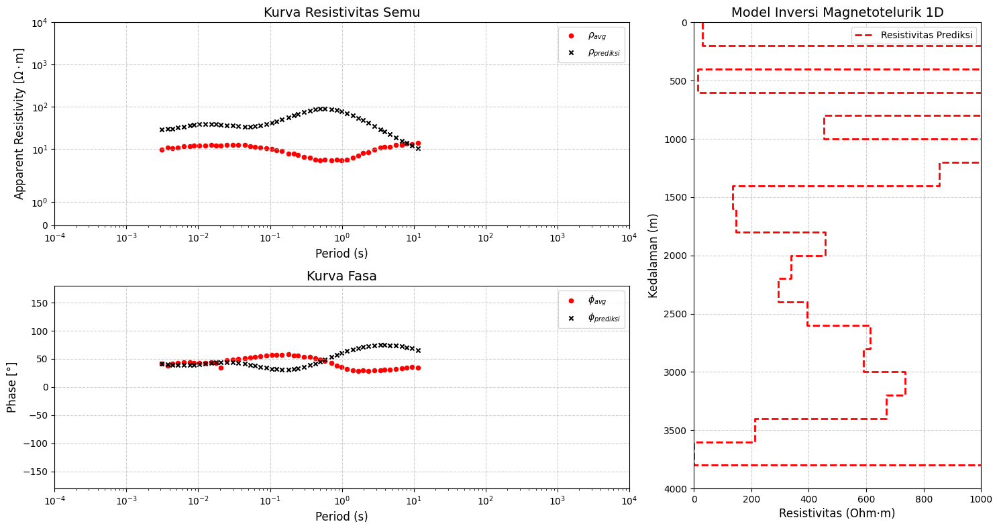

In [ ]:
def formating_result(resis, ketebalan, total_depth):
  depth = np.concatenate(([0], np.cumsum(ketebalan), [total_depth]))
  depth_plot = np.repeat(depth, 2)[1:-1]
  resis_plot = np.repeat(resis, 2)
  return depth_plot, resis_plot

depth_pred_plot, resis_pred_plot = formating_result(resis_predict, ketebalan_predict, total_depth)
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

# Buat figure dan GridSpec
fig = plt.figure(figsize=(15, 8))
gs = gridspec.GridSpec(2, 2, width_ratios=[2, 1])  # 2 baris, 2 kolom, kolom kanan lebih kecil

# Subplot 1: Resistivitas Semu
ax1 = fig.add_subplot(gs[0, 0])
ax1.scatter(1/frequency, rho_avg, color='red', label=r'$\rho_{avg}$', s=20)
ax1.scatter(1/frequency, resistivitas_semu_predict[0], color='black',marker ='x', label=r'$\rho_{prediksi}$', s=20)
ax1.set_ylabel(r'Apparent Resistivity [$\Omega\cdot$m]', fontsize=12)
ax1.set_xlabel('Period (s)', fontsize=12)
ax1.set_xscale('log')
ax1.set_yscale('symlog')
ax1.set_ylim([0, 10000])
ax1.set_xlim([1e-4, 1e4])
ax1.grid(True, linestyle='--', alpha=0.6)
ax1.set_title('Kurva Resistivitas Semu', fontsize=14)
ax1.legend()

# Subplot 2: Phase
ax2 = fig.add_subplot(gs[1, 0])
ax2.scatter(1/frequency, phi_avg, color='red', label=r'$\phi_{avg}$', s=20)
ax2.scatter(1/frequency, fasa_predict[0], color='black', marker = 'x', label=r'$\phi_{prediksi}$', s=20)
ax2.set_ylabel('Phase [°]', fontsize=12)
ax2.set_xlabel('Period (s)', fontsize=12)
ax2.set_xscale('log')
ax2.set_ylim([-180, 180])
ax2.set_xlim([1e-4, 1e4])
ax2.grid(True, linestyle='--', alpha=0.6)
ax2.set_title('Kurva Fasa', fontsize=14)
ax2.legend()

#Jika ingin mengaktifkan subplot 3, tinggal uncomment
ax3 = fig.add_subplot(gs[:, 1])
ax3.plot(resis_pred_plot, depth_pred_plot, label='Resistivitas Prediksi', color='red', linestyle='--', linewidth=2)
ax3.set_xlabel('Resistivitas (Ohm·m)', fontsize=12)
ax3.set_ylabel('Kedalaman (m)', fontsize=12)
ax3.set_title('Model Inversi Magnetotelurik 1D', fontsize=14)
ax3.legend(loc='upper right')
ax3.grid(True, linestyle='--', alpha=0.6)
ax3.set_xlim(0, 1000)
ax3.set_ylim(4000, 0)  # Dari permukaan ke bawah

plt.tight_layout()
plt.show()


## Aceh 07

In [ ]:
frequency = np.loadtxt("/content/drive/MyDrive/Tugas Akhir/Data Lapangan/Aceh 07/Frequency_Aceh07.txt")
RHOXY = np.loadtxt("/content/drive/MyDrive/Tugas Akhir/Data Lapangan/Aceh 07/RhoXY_Aceh07.txt")
RHOYX = np.loadtxt("/content/drive/MyDrive/Tugas Akhir/Data Lapangan/Aceh 07/RhoYX_Aceh07.txt")
phaseXY = np.loadtxt("/content/drive/MyDrive/Tugas Akhir/Data Lapangan/Aceh 07/PHSXY_Aceh07.txt")
phaseYX = np.loadtxt("/content/drive/MyDrive/Tugas Akhir/Data Lapangan/Aceh 07/PHSYX_Aceh07.txt")

In [ ]:
frequency = frequency.flatten()
RHOXY = RHOXY.flatten()
RHOYX = RHOYX.flatten()
phaseXY = phaseXY.flatten()
phaseYX = phaseYX.flatten()

In [ ]:
rho_avg, phi_avg = hitung_rho_phi_avg(RHOXY, phaseXY, RHOYX, phaseYX+180)

In [ ]:
import numpy as np
from scipy import interpolate

# Misalkan data asli Anda (48 titik)
frequency_original = frequency  # Array dengan shape (48,)
rho_xy_original = rho_avg.flatten()  # Array dengan shape (48,)
phase_xy_original = phi_avg.flatten()  # Array dengan shape (48,)

# Pastikan frekuensi dalam skala log (karena biasanya MT menggunakan log-freq)
log_freq_original = np.log10(frequency_original)

# Buat frekuensi target (69 titik, dalam skala log)
log_freq_target = np.linspace(log_freq_original.min(), log_freq_original.max(), 69)
frequency_target = 10**log_freq_target  # Kembalikan ke skala linier jika diperlukan

# Interpolasi resistivitas dan fasa dalam skala log (karena ρ dan φ biasanya di-log)
log_rho_xy_original = np.log10(rho_xy_original)
log_phase_xy_original = np.log10(phase_xy_original)

# Buat fungsi interpolasi (bisa linear, spline, dll)
interp_rho = interpolate.interp1d(log_freq_original, log_rho_xy_original, kind='cubic', fill_value='extrapolate')
interp_phase = interpolate.interp1d(log_freq_original, log_phase_xy_original, kind='cubic', fill_value='extrapolate')

# Hitung nilai interpolasi (dalam log)
log_rho_interp = interp_rho(log_freq_target)
log_phase_interp = interp_phase(log_freq_target)

# Kembalikan ke nilai normal (jika diperlukan)
rho_interp = 10**log_rho_interp
phase_interp = 10**log_phase_interp

rho_interp = rho_interp[::-1]
phase_interp = phase_interp[::-1]



In [ ]:


resistivitas_semu = np.array([rho_interp])
fasa = np.array([phase_interp])

#Reshape sebelum Logaritma
resistivitas_semu = resistivitas_semu[0].reshape(1, X_input_res.shape[1]) # Corrected reshape syntax
fasa = fasa.reshape(1, X_input_phase.shape[1])

#Logaritma data input
resistivitas_semu_log = np.log10(resistivitas_semu)
fasa_log = np.log10(fasa)

# Normalisasi data input
resistivitas_semu_normalized = input_res_scaler.transform(resistivitas_semu_log)
fasa_normalized = input_phase_scaler.transform(fasa_log)

# Reshape jika perlu (misalnya, untuk input CNN)
resistivitas_semu_normalized = resistivitas_semu_normalized.reshape(1, X_input_res.shape[1], 1)
fasa_normalized = fasa_normalized.reshape(1, X_input_phase.shape[1], 1)

# Prediksi
predictions = model.predict([resistivitas_semu_normalized, fasa_normalized])

# Denormalisasi hasil prediksi, apply to the predictions, not hasil
predictions_denormalized = output_model_scaler.inverse_transform(predictions)

# Delogaritmik hasil prediksi
predictions_denormalized = np.power(10, predictions_denormalized)

# Accessing the values from predictions_denormalized
resis_predict = predictions_denormalized[0] #
ketebalan_predict = np.full(jumlah_layer-1,layer_thickness)

#Forward Modelling from prediction model
resistivitas_semu_predict, fasa_predict = forward_modelling(resis_predict,ketebalan_predict,frequency)
resistivitas_semu_predict = np.array([resistivitas_semu_predict])
fasa_predict = np.array([fasa_predict])


#print(hasil) #No need to print hasil as it's not used


print("Nilai resis_predict",resis_predict)
print("Nilai ketebalan_predict",ketebalan_predict)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
Nilai resis_predict [7.67082825e+01 1.75451981e+02 3.65928936e+00 4.35313916e+03
 1.06561377e+03 1.94829297e+03 1.50213733e+03 7.27112854e+02
 4.30469727e+02 2.81510345e+02 9.06321564e+01 3.23396698e+02
 4.52341125e+02 5.02119232e+02 3.27024109e+02 3.67401520e+02
 2.74027527e+02 1.10838615e+02 1.15753078e+00 1.24487207e+03]
Nilai ketebalan_predict [200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200.
 200. 200. 200. 200. 200.]


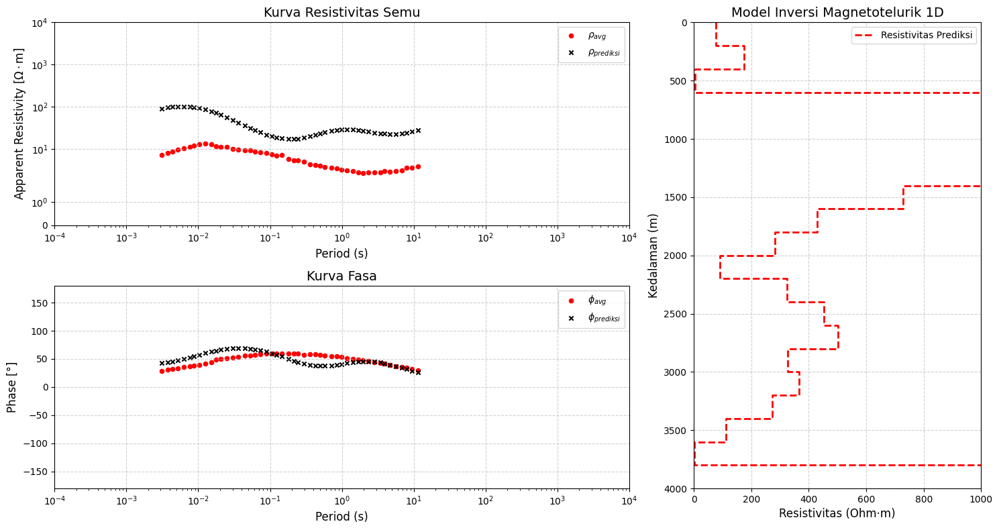

In [ ]:
def formating_result(resis, ketebalan, total_depth):
  depth = np.concatenate(([0], np.cumsum(ketebalan), [total_depth]))
  depth_plot = np.repeat(depth, 2)[1:-1]
  resis_plot = np.repeat(resis, 2)
  return depth_plot, resis_plot

depth_pred_plot, resis_pred_plot = formating_result(resis_predict, ketebalan_predict, total_depth)
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

# Buat figure dan GridSpec
fig = plt.figure(figsize=(15, 8))
gs = gridspec.GridSpec(2, 2, width_ratios=[2, 1])  # 2 baris, 2 kolom, kolom kanan lebih kecil

# Subplot 1: Resistivitas Semu
ax1 = fig.add_subplot(gs[0, 0])
ax1.scatter(1/frequency, rho_avg, color='red', label=r'$\rho_{avg}$', s=20)
ax1.scatter(1/frequency, resistivitas_semu_predict[0], color='black',marker ='x', label=r'$\rho_{prediksi}$', s=20)
ax1.set_ylabel(r'Apparent Resistivity [$\Omega\cdot$m]', fontsize=12)
ax1.set_xlabel('Period (s)', fontsize=12)
ax1.set_xscale('log')
ax1.set_yscale('symlog')
ax1.set_ylim([0, 10000])
ax1.set_xlim([1e-4, 1e4])
ax1.grid(True, linestyle='--', alpha=0.6)
ax1.set_title('Kurva Resistivitas Semu', fontsize=14)
ax1.legend()

# Subplot 2: Phase
ax2 = fig.add_subplot(gs[1, 0])
ax2.scatter(1/frequency, phi_avg, color='red', label=r'$\phi_{avg}$', s=20)
ax2.scatter(1/frequency, fasa_predict[0], color='black', marker = 'x', label=r'$\phi_{prediksi}$', s=20)
ax2.set_ylabel('Phase [°]', fontsize=12)
ax2.set_xlabel('Period (s)', fontsize=12)
ax2.set_xscale('log')
ax2.set_ylim([-180, 180])
ax2.set_xlim([1e-4, 1e4])
ax2.grid(True, linestyle='--', alpha=0.6)
ax2.set_title('Kurva Fasa', fontsize=14)
ax2.legend()

#Jika ingin mengaktifkan subplot 3, tinggal uncomment
ax3 = fig.add_subplot(gs[:, 1])
ax3.plot(resis_pred_plot, depth_pred_plot, label='Resistivitas Prediksi', color='red', linestyle='--', linewidth=2)
ax3.set_xlabel('Resistivitas (Ohm·m)', fontsize=12)
ax3.set_ylabel('Kedalaman (m)', fontsize=12)
ax3.set_title('Model Inversi Magnetotelurik 1D', fontsize=14)
ax3.legend(loc='upper right')
ax3.grid(True, linestyle='--', alpha=0.6)
ax3.set_xlim(0, 1000)
ax3.set_ylim(4000, 0)  # Dari permukaan ke bawah

plt.tight_layout()
plt.show()


## Aceh 08

In [ ]:
def load_txt_cleaned(filepath):
    with open(filepath, "r") as f:
        lines = f.readlines()

    values = []
    for line in lines:
        for val in line.strip().split():
            try:
                values.append(float(val))
            except ValueError:
                pass  # Abaikan jika ada karakter non-numerik

    return np.array(values)


In [ ]:
# Path dasar folder
base = "/content/drive/MyDrive/Tugas Akhir/Data Lapangan/Aceh 08/"

# Baca dengan fungsi pembersih
frequency = load_txt_cleaned(base + "Frequency_Aceh08.txt")
RHOXY    = load_txt_cleaned(base + "RhoXY_Aceh08.txt")
RHOYX    = load_txt_cleaned(base + "RhoYX_Aceh08.txt")
phaseXY  = load_txt_cleaned(base + "PHSXY_Aceh08.txt")
phaseYX  = load_txt_cleaned(base + "PHSYX_Aceh08.txt")


In [ ]:
frequency = np.delete(frequency, -1)
RHOXY = np.delete(RHOXY, -1)
RHOYX = np.delete(RHOYX, -1)
phaseXY = np.delete(phaseXY, -1)
phaseYX = np.delete(phaseYX, -1)

In [ ]:
phaseYX = phaseYX + 180

In [ ]:
print("Jumlah data:", len(frequency), len(RHOXY), len(RHOYX), len(phaseXY), len(phaseYX))
print("Contoh data:", RHOXY[:5])


Jumlah data: 48 48 48 48 48
Contoh data: [3.971553 3.971553 3.805728 3.887897 3.946853]


In [ ]:
rho_avg, phi_avg = hitung_rho_phi_avg(RHOXY, phaseXY, RHOYX, phaseYX)
#

In [ ]:
import numpy as np
from scipy import interpolate

# Misalkan data asli Anda (48 titik)
frequency_original = frequency  # Array dengan shape (48,)
rho_xy_original = rho_avg.flatten()  # Array dengan shape (48,)
phase_xy_original = phi_avg.flatten()  # Array dengan shape (48,)

# Pastikan frekuensi dalam skala log (karena biasanya MT menggunakan log-freq)
log_freq_original = np.log10(frequency_original)

# Buat frekuensi target (69 titik, dalam skala log)
log_freq_target = np.linspace(log_freq_original.min(), log_freq_original.max(), 69)
frequency_target = 10**log_freq_target  # Kembalikan ke skala linier jika diperlukan

# Interpolasi resistivitas dan fasa dalam skala log (karena ρ dan φ biasanya di-log)
log_rho_xy_original = np.log10(rho_xy_original)
log_phase_xy_original = np.log10(phase_xy_original)

# Buat fungsi interpolasi (bisa linear, spline, dll)
interp_rho = interpolate.interp1d(log_freq_original, log_rho_xy_original, kind='cubic', fill_value='extrapolate')
interp_phase = interpolate.interp1d(log_freq_original, log_phase_xy_original, kind='cubic', fill_value='extrapolate')

# Hitung nilai interpolasi (dalam log)
log_rho_interp = interp_rho(log_freq_target)
log_phase_interp = interp_phase(log_freq_target)

# Kembalikan ke nilai normal (jika diperlukan)
rho_interp = 10**log_rho_interp
phase_interp = 10**log_phase_interp

rho_interp = rho_interp[::-1]
phase_interp = phase_interp[::-1]



In [ ]:


resistivitas_semu = np.array([rho_interp])
fasa = np.array([phase_interp])

#Reshape sebelum Logaritma
resistivitas_semu = resistivitas_semu[0].reshape(1, X_input_res.shape[1]) # Corrected reshape syntax
fasa = fasa.reshape(1, X_input_phase.shape[1])

#Logaritma data input
resistivitas_semu_log = np.log10(resistivitas_semu)
fasa_log = np.log10(fasa)

# Normalisasi data input
resistivitas_semu_normalized = input_res_scaler.transform(resistivitas_semu_log)
fasa_normalized = input_phase_scaler.transform(fasa_log)

# Reshape jika perlu (misalnya, untuk input CNN)
resistivitas_semu_normalized = resistivitas_semu_normalized.reshape(1, X_input_res.shape[1], 1)
fasa_normalized = fasa_normalized.reshape(1, X_input_phase.shape[1], 1)

# Prediksi
predictions = model.predict([resistivitas_semu_normalized, fasa_normalized])

# Denormalisasi hasil prediksi, apply to the predictions, not hasil
predictions_denormalized = output_model_scaler.inverse_transform(predictions)

# Delogaritmik hasil prediksi
predictions_denormalized = np.power(10, predictions_denormalized)

# Accessing the values from predictions_denormalized
resis_predict = predictions_denormalized[0] #
ketebalan_predict = np.full(jumlah_layer-1,layer_thickness)

#Forward Modelling from prediction model
resistivitas_semu_predict, fasa_predict = forward_modelling(resis_predict,ketebalan_predict,frequency)
resistivitas_semu_predict = np.array([resistivitas_semu_predict])
fasa_predict = np.array([fasa_predict])


#print(hasil) #No need to print hasil as it's not used


print("Nilai resis_predict",resis_predict)
print("Nilai ketebalan_predict",ketebalan_predict)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
Nilai resis_predict [2072.5156  1271.6519  3268.299    162.25725  781.77435  663.4535
 1024.6731   711.81384  892.55835  688.46375  802.1884  1020.07855
 1216.4312  1338.2437  1206.5726   934.8332   933.9714  1627.0468
  565.3929   854.55835]
Nilai ketebalan_predict [200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200.
 200. 200. 200. 200. 200.]


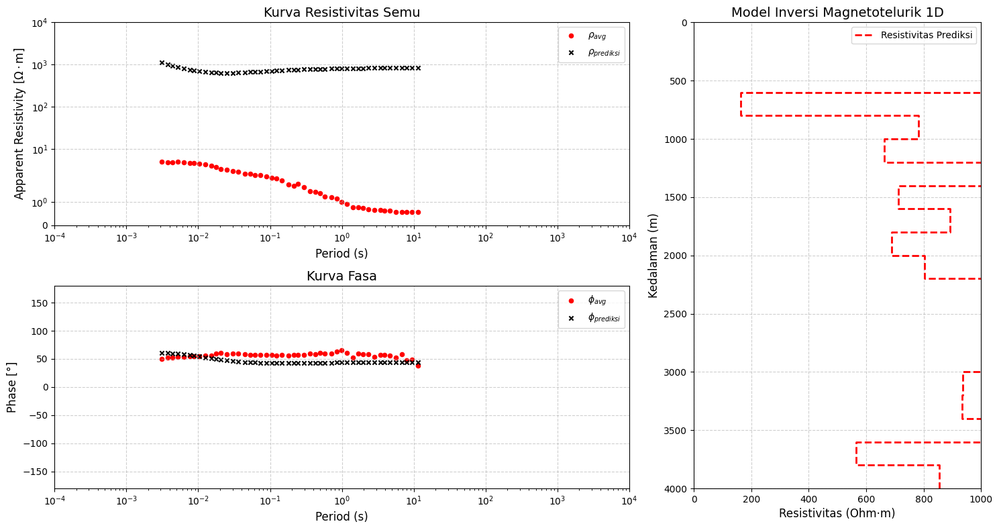

In [ ]:
def formating_result(resis, ketebalan, total_depth):
  depth = np.concatenate(([0], np.cumsum(ketebalan), [total_depth]))
  depth_plot = np.repeat(depth, 2)[1:-1]
  resis_plot = np.repeat(resis, 2)
  return depth_plot, resis_plot

depth_pred_plot, resis_pred_plot = formating_result(resis_predict, ketebalan_predict, total_depth)
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

# Buat figure dan GridSpec
fig = plt.figure(figsize=(15, 8))
gs = gridspec.GridSpec(2, 2, width_ratios=[2, 1])  # 2 baris, 2 kolom, kolom kanan lebih kecil

# Subplot 1: Resistivitas Semu
ax1 = fig.add_subplot(gs[0, 0])
ax1.scatter(1/frequency, rho_avg, color='red', label=r'$\rho_{avg}$', s=20)
ax1.scatter(1/frequency, resistivitas_semu_predict[0], color='black',marker ='x', label=r'$\rho_{prediksi}$', s=20)
ax1.set_ylabel(r'Apparent Resistivity [$\Omega\cdot$m]', fontsize=12)
ax1.set_xlabel('Period (s)', fontsize=12)
ax1.set_xscale('log')
ax1.set_yscale('symlog')
ax1.set_ylim([0, 10000])
ax1.set_xlim([1e-4, 1e4])
ax1.grid(True, linestyle='--', alpha=0.6)
ax1.set_title('Kurva Resistivitas Semu', fontsize=14)
ax1.legend()

# Subplot 2: Phase
ax2 = fig.add_subplot(gs[1, 0])
ax2.scatter(1/frequency, phi_avg, color='red', label=r'$\phi_{avg}$', s=20)
ax2.scatter(1/frequency, fasa_predict[0], color='black', marker = 'x', label=r'$\phi_{prediksi}$', s=20)
ax2.set_ylabel('Phase [°]', fontsize=12)
ax2.set_xlabel('Period (s)', fontsize=12)
ax2.set_xscale('log')
ax2.set_ylim([-180, 180])
ax2.set_xlim([1e-4, 1e4])
ax2.grid(True, linestyle='--', alpha=0.6)
ax2.set_title('Kurva Fasa', fontsize=14)
ax2.legend()

#Jika ingin mengaktifkan subplot 3, tinggal uncomment
ax3 = fig.add_subplot(gs[:, 1])
ax3.plot(resis_pred_plot, depth_pred_plot, label='Resistivitas Prediksi', color='red', linestyle='--', linewidth=2)
ax3.set_xlabel('Resistivitas (Ohm·m)', fontsize=12)
ax3.set_ylabel('Kedalaman (m)', fontsize=12)
ax3.set_title('Model Inversi Magnetotelurik 1D', fontsize=14)
ax3.legend(loc='upper right')
ax3.grid(True, linestyle='--', alpha=0.6)
ax3.set_xlim(0, 1000)
ax3.set_ylim(4000, 0)  # Dari permukaan ke bawah

plt.tight_layout()
plt.show()
